In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import os
# Importing the numpy and pandas package
import numpy as np # linear algebra
import pandas as pd # data processing, file I/O
# Data Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (train_test_split,
                    StratifiedKFold, KFold,
                    cross_val_score, 
                    cross_validate, 
                    GridSearchCV)

from skopt import BayesSearchCV

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error, max_error, explained_variance_score,
    mean_absolute_percentage_error,
    root_mean_squared_error)
import numpy as np

import category_encoders as ce




import pickle
# Import all models
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, 
                                BaggingRegressor,
                                AdaBoostRegressor,
                                ExtraTreesRegressor,
                                GradientBoostingRegressor)



from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

from sklearn.linear_model import (LinearRegression,
                                    Ridge,
                                    Lasso,
                                    ElasticNet)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from tensorflow import keras

In [3]:
os.chdir(r"C:\Users\Owner\Downloads\Data Science Metro\DSPP\Projects")
os.getcwd()

'C:\\Users\\Owner\\Downloads\\Data Science Metro\\DSPP\\Projects'

In [4]:
outputfolder=r"C:\Users\Owner\Downloads\Data Science Metro\DSPP\Projects\Output"

## Load and split data

In [5]:
df = pd.read_csv(r"C:\Users\Owner\Downloads\Data Science Metro\DSPP\Projects\quebec_housing_sales_v2.csv")
df.shape

(5000, 14)

In [6]:
df.head()

,property_id,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,renovation_year,garage,basement,sale_year,sale_price
0,1,Châteauguay,Centre-Ville,Townhouse,3,2,1160,2304.0,2022,NaN,Yes,No,2024,326000
1,2,Trois-Rivières,Cap-de-la-Madeleine,Duplex,4,4,1807,5869.0,2006,2024.0,No,Yes,2025,444000
2,3,Lévis,Charny,Townhouse,3,1,803,3387.0,1989,NaN,Yes,Yes,2025,273000
3,4,Laval,Fabreville,Single Family,3,3,1083,11417.0,1972,2016.0,Yes,Yes,2023,465000
4,5,Longueuil,Greenfield Park,Condo,2,2,714,NaN,1997,2010.0,Yes,No,2022,371000


In [7]:
df['sale_price'].isna().sum()

np.int64(0)

In [8]:
print(df.shape)
df=df.dropna(subset=['sale_price'])
print(df.shape)

(5000, 14)
(5000, 14)


In [9]:
df['sale_price'].value_counts()

sale_price
452000     22
387000     21
472000     21
412000     20
318000     20
           ..
1189000     1
786000      1
1057000     1
945000      1
748000      1
Name: count, Length: 803, dtype: int64

## Import DataPipeline

In [10]:
#a .py file(datapipeline.py) must be in the current working directory or in Python’s module search path to be imported.
from Pipeline_housing_regression_SobiaPervaiz import *

In [11]:
X=df.drop(columns=['sale_price'])
y=df['sale_price']

In [12]:
target = 'sale_price'
#Split data
X_train,X_test,y_train,y_test = train_test_split(
    X,y,
    test_size=0.20,                 # 20%
   
    random_state=42
)


In [13]:
"""
MODEL COMPARISON SUMMARY (REGRESSION)
==================================================
For each model, displays:
- R-Square (R²) Score (Variance Explained)
- Root Mean Squared Error (RMSE)
- Mean Absolute Error (MAE)
- Model Rankings and Average Rank Performance
"""

print("Dataset Information:")
print("=" * 70)
print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

print()




# ══════════════════════════════════════════════════════════════════════
# HELPER FUNCTION: Calculate standard regression metrics
# ══════════════════════════════════════════════════════════════════════
def evaluate_regression_model(y_true, y_pred, model_name="Model"):
    """
    Calculate core regression metrics (R2, RMSE, MAE, and MAPE) for a model.
    
    Args:
        y_true: True continuous targets
        y_pred: Predicted continuous values
        model_name: Name of the model
    
    Returns:
        Dictionary with all regression metrics
    """
    # Calculate standard regression metrics
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    
    
    # Calculate Mean Absolute Percentage Error (MAPE) safely
    # (handles potential division by zero if any y_true value is exactly 0)
    # MAPE - handle division by zero
    # Only calculate MAPE if no zero values in y_true
    if (y_true == 0).any():
        mape = np.nan  # Can't calculate MAPE with zero values
    else:
        mape = mean_absolute_percentage_error(y_true, y_pred)
    
    return {
        'Model': model_name,
        'MAE': mae,
        'R2': r2,
        'MSE': mse,
        'RMSE': rmse,
        'MAPE': mape
    }

# ══════════════════════════════════════════════════════════════════════
# Helper function to print results table (Regression)
# ══════════════════════════════════════════════════════════════════════
def print_results_table(results_list, title):
    """Print a formatted table of results"""
    print(f"\n{title}")
    print("=" * 100)
    print(f"{'Model':<25} {'MAE':<12} {'RMSE':<12} {'R²':<12} {'MAPE (%)':<12}")
    print("-" * 100)
    
    for result in results_list:
        mape_str = f"{result['MAPE']*100:<12.2f}" if not np.isnan(result['MAPE']) else "N/A         "
        print(f"{result['Model']:<25} "
              f"{result['MAE']:<12.4f} "
              f"{result['RMSE']:<12.4f} "
              f"{result['R2']:<12.4f} "
              f"{mape_str}")
    print()

# ══════════════════════════════════════════════════════════════════════
# GROUP 1: ROBUST TREE MODELS (Decision Trees / Random Forest / Extra Trees)
# ══════════════════════════════════════════════════════════════════════
# Preprocess ONCE for all these models
X_train_tree = pipeline_housing(X_train, X_train,
                        scaling_data=False, Handling_Outliers=False,
                        Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=True,
                        encoding=True, is_training_data=True)

y_train_tree = y_train.loc[X_train_tree.index]

X_test_tree = pipeline_housing(X_test, X_train,
                    scaling_data=False, Handling_Outliers=False,
                    Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=True,
                    encoding=True, is_training_data=False)

X_test_tree = X_test_tree.reindex(columns=X_train_tree.columns, fill_value=0)
y_test_tree = y_test.loc[X_test_tree.index]

# Updated with Regressors
tree_robust_models = {
    "Decision Tree": DecisionTreeRegressor(max_depth=10,random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100,random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100,random_state=42)
}

tree_results = []
for name, model in tree_robust_models.items():
    # Train
    model.fit(X_train_tree, y_train_tree)
    
    # Predict continuous, raw targets directly (no probabilities!)
    y_pred = model.predict(X_test_tree)
    
    # Evaluate using your regression helper function
    metrics = evaluate_regression_model(y_test_tree, y_pred, name)
    tree_results.append(metrics)

print_results_table(tree_results, "GROUP 1: ROBUST TREE MODELS")
print("=" * 115)



# ══════════════════════════════════════════════════════════════════════
# GROUP 2: ADABOOST (OUTLIER-SENSITIVE)
# ══════════════════════════════════════════════════════════════════════
X_train_ada = pipeline_housing(X_train, X_train,
                        scaling_data=False, Handling_Outliers=True,
                        Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=True,
                        encoding=True, is_training_data=True)

y_train_ada = y_train.loc[X_train_ada.index]

X_test_ada = pipeline_housing(X_test, X_train,
                    scaling_data=False, Handling_Outliers=True,
                    Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=True,
                    encoding=True, is_training_data=False)
X_test_ada = X_test_ada.reindex(columns=X_train_ada.columns, fill_value=0)

y_test_ada = y_test.loc[X_test_ada.index]

# Updated with Regressor
model_ada = AdaBoostRegressor(random_state=42)
model_ada.fit(X_train_ada, y_train_ada)

# Predict raw targets directly
y_pred_ada = model_ada.predict(X_test_ada)

# Evaluate using regression helper function
metrics_ada = evaluate_regression_model(y_test_ada, y_pred_ada, "AdaBoost")

print_results_table([metrics_ada], "GROUP 2: ADABOOST")



# ══════════════════════════════════════════════════════════════════════
# GROUP 3: GRADIENT BOOSTING MODELS (WITH ENCODING)
# ══════════════════════════════════════════════════════════════════════
# Preprocess ONCE for all gradient boosting models
X_train_gb = pipeline_housing(X_train, X_train,
                        scaling_data=False, Handling_Outliers=False,
                        Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=False,
                        encoding=True, is_training_data=True)

y_train_gb = y_train.loc[X_train_gb.index]
X_test_gb = pipeline_housing(X_test, X_train,
                    scaling_data=False, Handling_Outliers=False,
                    Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=False,
                    encoding=True, is_training_data=False)

X_test_gb = X_test_gb.reindex(columns=X_train_gb.columns, fill_value=0)
y_test_gb = y_test.loc[X_test_gb.index]

# Updated with correct regression parameters
gradient_boosting_models = {
    "XGBoost": XGBRegressor(random_state=42, eval_metric='rmse'),  # XGBRegressor and rmse
    "LightGBM": LGBMRegressor(random_state=42, verbose=-1)
}

gb_results = []
for name, model in gradient_boosting_models.items():
    # Train
    model.fit(X_train_gb, y_train_gb)
    
    # Predict continuous numeric targets directly
    y_pred = model.predict(X_test_gb)
    
    # Evaluate using the regression helper function
    metrics = evaluate_regression_model(y_test_gb, y_pred, name)
    gb_results.append(metrics)

print_results_table(gb_results, "GROUP 3: GRADIENT BOOSTING MODELS (WITH ENCODING)")
print("=" * 115)
    


# ══════════════════════════════════════════════════════════════════════
# GROUP 3: GRADIENT BOOSTING MODELS WITHOUT ENCODING
# ══════════════════════════════════════════════════════════════════════
# Preprocess ONCE for all gradient boosting models
X_train_gb2 = pipeline_housing(X_train, X_train,
                        scaling_data=False, Handling_Outliers=False,
                        Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=False,
                        encoding=False, is_training_data=True)

y_train_gb2 = y_train.loc[X_train_gb2.index]
X_test_gb2 = pipeline_housing(X_test, X_train,
                    scaling_data=False, Handling_Outliers=False,
                    Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=False,
                    encoding=False, is_training_data=False)

X_test_gb2 = X_test_gb2.reindex(columns=X_train_gb2.columns, fill_value=0)
y_test_gb2 = y_test.loc[X_test_gb2.index]

cat_features = ['city', 'neighborhood', 'property_type', 'garage', 'basement', 'ProvLocation']

# CatBoost does NOT allow raw NaN inside categorical columns.
for col in cat_features:
    X_train_gb2[col] = X_train_gb2[col].fillna("Missing").astype(str)
    X_test_gb2[col] = X_test_gb2[col].fillna("Missing").astype(str)
    
# Updated with Regressor
gradient_boosting_models = {
    "CatBoost": CatBoostRegressor(cat_features=cat_features, random_state=42, verbose=0)
}

gb_results_no_enc = []  # Renamed to avoid overwriting Group 3.a gb_results list

for name, model in gradient_boosting_models.items():
    # Train
    model.fit(X_train_gb2, y_train_gb2)
    
    # Predict continuous targets directly
    y_pred = model.predict(X_test_gb2)
    
    # Evaluate using the regression helper function
    metrics = evaluate_regression_model(y_test_gb2, y_pred, name)
    gb_results_no_enc.append(metrics)

print_results_table(gb_results_no_enc, "GROUP 3.b: GRADIENT BOOSTING MODELS (NO ENCODING!)")
print("=" * 115)

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

# ══════════════════════════════════════════════════════════════════════
# GROUP 4: SCALE-SENSITIVE MODELS (REGRESSION)
# ══════════════════════════════════════════════════════════════════════
# Preprocess ONCE for all scale-sensitive models
X_train_scaled = pipeline_housing(
    X_train,
    X_train,         
    scaling_data=True,
    Handling_Outliers=True,
    Handling_Missing_Values_Not_DT=True,
    Handling_Missing_Values_DT=False,
    encoding=True,
    is_training_data=True
)
y_train_scaled = y_train.loc[X_train_scaled.index] 

X_test_scaled = pipeline_housing(
    X_test,
    X_train,         
    scaling_data=True,
    Handling_Outliers=True,
    Handling_Missing_Values_Not_DT=True,
    Handling_Missing_Values_DT=False,
    encoding=True,
    is_training_data=False
)
X_test_scaled = X_test_scaled.reindex(columns=X_train_scaled.columns, fill_value=0)
y_test_scaled = y_test.loc[X_test_scaled.index] 

# Updated dictionary with valid Regression models
scale_sensitive_models = {
    "Linear Regression": LinearRegression(),  
    "Ridge": Ridge(random_state=42),
    "Lasso": Lasso(random_state=42),
    "ElasticNet": ElasticNet(random_state=42),      
    "SVR": SVR(kernel='rbf'),                 
    "KNN Regressor": KNeighborsRegressor(n_neighbors=5)
}

scale_results = []
for name, model in scale_sensitive_models.items():
    # Train
    model.fit(X_train_scaled, y_train_scaled)
    
    # Predict continuous numeric values directly
    y_pred = model.predict(X_test_scaled)
    
    # Evaluate using the regression helper function
    metrics = evaluate_regression_model(y_test_scaled, y_pred, name)
    scale_results.append(metrics)

print_results_table(scale_results, "GROUP 4: SCALE-SENSITIVE MODELS")

from tensorflow import keras

# ══════════════════════════════════════════════════════════════════════
# Neural Network Regressor (uses scaled data)
# ══════════════════════════════════════════════════════════════════════
model_nn = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    keras.layers.Dropout(0.2), # Slightly lower dropout often works better for regression variance tracking
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(1, activation='linear') # CRITICAL:  'linear' for continuous range outputs
])

model_nn.compile(
    optimizer='adam',
    loss='mean_squared_error', # CRITICAL: Changed from classification 'binary_crossentropy' to 'mean_squared_error'
    metrics=['mae']            # Track Mean Absolute Error during training instead of accuracy
)

model_nn.fit(
    X_train_scaled, y_train_scaled,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# Predict continuous target values directly
y_pred_nn = model_nn.predict(X_test_scaled, verbose=0).flatten()

# Evaluate using your regression helper function
metrics_nn = evaluate_regression_model(y_test_scaled, y_pred_nn, "Neural Network")

print_results_table([metrics_nn], "NEURAL NETWORK")


# ══════════════════════════════════════════════════════════════════════
# COMPREHENSIVE COMPARISON - ALL MODELS (REGRESSION)
# ══════════════════════════════════════════════════════════════════════
print("\n" + "=" * 115)
print("COMPLETE MODEL COMPARISON - ALL MODELS")
print("=" * 115)

# Combine all results (Ensure your regression model dictionaries use keys: 'Model', 'R2', 'RMSE', 'MAE')
all_results = tree_results + [metrics_ada] + gb_results + scale_results + [metrics_nn]

# Convert to DataFrame for easier sorting
results_df = pd.DataFrame(all_results)

# Print complete table sorted by R² Score descending
print(f"\n{'Rank':<6} {'Model':<25} {'R² Score':<15} {'RMSE':<15} {'MAE':<15}")
print("-" * 115)

# Sorting by R2 descending so the best overall model sits at Rank 1
sorted_results = results_df.sort_values('R2', ascending=False)
for rank, row in enumerate(sorted_results.itertuples(), 1):
    mape_str = f"{row.MAPE*100:<12.2f}" if not np.isnan(row.MAPE) else "N/A         "
    print(f"{rank:<6} {row.Model:<25} "
          f"{row.MAE:<12.4f} "
          f"{row.RMSE:<12.4f} "
          f"{row.R2:<12.4f} "
          f"{mape_str}")

# ══════════════════════════════════════════════════════════════════════
# DETAILED RANKINGS BY EACH METRIC (REGRESSION)
# ══════════════════════════════════════════════════════════════════════
print("\n\n" + "=" * 115)
print("DETAILED RANKINGS BY EACH METRIC")
print("=" * 115)

# Ranking by R2 (Higher is better -> Descending)
print("\n" + "-" * 115)
print("RANKED BY R² SCORE (MAXIMUM VARIANCE EXPLAINED)")
print("-" * 115)
print(f"{'Rank':<6} {'Model':<25} {'MAE':<12} {'RMSE':<12} {'R²':<12} {'MAPE (%)':<12}")
print("-" * 115)

sorted_by_r2 = results_df.sort_values('R2', ascending=False)
for rank, row in enumerate(sorted_by_r2.itertuples(), 1):
    print(f"{rank:<6} {row.Model:<25} "
          f"{row.MAE:<12.4f} "
          f"{row.RMSE:<12.4f} "
          f"{row.R2:<12.4f} "
          f"{mape_str}")

# Ranking by RMSE (Lower is better -> Ascending)
print("\n" + "-" * 115)
print("RANKED BY RMSE (PENALIZES LARGE ERRORS)")
print("-" * 115)
print(f"{'Rank':<6} {'Model':<25} {'MAE':<12} {'RMSE':<12} {'R²':<12} {'MAPE (%)':<12}")
print("-" * 115)

sorted_by_rmse = results_df.sort_values('RMSE', ascending=True)
for rank, row in enumerate(sorted_by_rmse.itertuples(), 1):
    print(f"{rank:<6} {row.Model:<25} "
          f"{row.RMSE:<15.4f} "
          f"{row.R2:<15.4f} "
          f"{row.MAE:<15.4f}"
        )

# Ranking by MAE (Lower is better -> Ascending)
print("\n" + "-" * 115)
print("RANKED BY MAE (ROBUST TO OUTLIERS)")
print("-" * 115)
print(f"{'Rank':<6} {'Model':<25} {'MAE':<12} {'RMSE':<12} {'R²':<12} {'MAPE (%)':<12}")
print("-" * 115)

sorted_by_mae = results_df.sort_values('MAE', ascending=True)
for rank, row in enumerate(sorted_by_mae.itertuples(), 1):
    print(f"{rank:<6} {row.Model:<25} "
          f"{row.MAE:<15.4f} "
          f"{row.R2:<15.4f} "
          f"{row.RMSE:<15.4f}"
          )
# Ranking by MAPE (lower is better, if available)
if not results_df['MAPE'].isna().all():
    print("\n" + "-" * 100)
    print("RANKED BY MAPE (LOWER IS BETTER)")
    print("-" * 100)
    print(f"{'Rank':<6} {'Model':<25} {'MAE':<12} {'RMSE':<12} {'R²':<12} {'MAPE (%)':<12}")
    print("-" * 100)
    
    sorted_by_mape = results_df.dropna(subset=['MAPE']).sort_values('MAPE', ascending=True)
    for rank, row in enumerate(sorted_by_mape.itertuples(), 1):
        print(f"{rank:<6} {row.Model:<25} "
              f"{row.MAE:<12.4f} "
              f"{row.RMSE:<12.4f} "
              f"{row.R2:<12.4f} "
              f"{row.MAPE*100:<12.2f}")


# ══════════════════════════════════════════════════════════════════════
# BEST MODELS SUMMARY
# ══════════════════════════════════════════════════════════════════════

print("\n\n" + "=" * 115)
print("BEST REGRESSION MODELS BY EACH METRIC")
print("=" * 115)

# Assumes dataframes are sorted appropriately (R2 descending, RMSE/MAE ascending)
best_r2_model = sorted_by_r2.iloc[0]
best_rmse_model = sorted_by_rmse.iloc[0]
best_mae_model = sorted_by_mae.iloc[0]

print(f"\nBEST R² SCORE (RECOMMENDED):  {best_r2_model['Model']}")
print(f"   - R²:    {best_r2_model['R2']:.4f}")
print(f"   - MAE:   {best_r2_model['MAE']:.4f}")
print(f"   - RMSE:  {best_r2_model['RMSE']:.4f}")
if not np.isnan(best_r2_model['MAPE']):
    print(f"   - MAPE:  {best_r2_model['MAPE']*100:.2f}%")

print(f"\nBEST MAE (LEAST AVERAGE ERROR):  {best_mae_model['Model']}")
print(f"   - MAE:   {best_mae_model['MAE']:.4f}")
print(f"   - RMSE:  {best_mae_model['RMSE']:.4f}")
print(f"   - R²:    {best_mae_model['R2']:.4f}")
if not np.isnan(best_mae_model['MAPE']):
    print(f"   - MAPE:  {best_mae_model['MAPE']*100:.2f}%")

print(f"\nBEST RMSE (LEAST SQUARED ERROR):  {best_rmse_model['Model']}")
print(f"   - RMSE:  {best_rmse_model['RMSE']:.4f}")
print(f"   - MAE:   {best_rmse_model['MAE']:.4f}")
print(f"   - R²:    {best_rmse_model['R2']:.4f}")
if not np.isnan(best_rmse_model['MAPE']):
    print(f"   - MAPE:  {best_rmse_model['MAPE']*100:.2f}%")

# ══════════════════════════════════════════════════════════════════════
# OVERALL WINNER (Balanced Performance Across All Metrics)
# ══════════════════════════════════════════════════════════════════════
print("\n\n" + "=" * 115)
print("OVERALL WINNER (Average Rank Across All Metrics)")
print("=" * 115)

# Calculate ranks for each metric (CRITICAL: R2 is higher-better; RMSE/MAE are lower-better)
results_df['R2_Rank'] = results_df['R2'].rank(ascending=False)
results_df['RMSE_Rank'] = results_df['RMSE'].rank(ascending=True)
results_df['MAE_Rank'] = results_df['MAE'].rank(ascending=True)

# Calculate average rank across all three metrics
results_df['Avg_Rank'] = (results_df['R2_Rank'] + results_df['RMSE_Rank'] + results_df['MAE_Rank']) / 3

# Sort by average rank (lowest rank number means best overall performance)
sorted_by_avg = results_df.sort_values('Avg_Rank')

print(f"\n{'Rank':<6} {'Model':<25} {'Avg Rank':<12} {'R² Score':<15} {'RMSE':<15} {'MAE':<15}")
print("-" * 115)
for rank, row in enumerate(sorted_by_avg.itertuples(), 1):
    print(f"{rank:<6} {row.Model:<25} "
          f"{row.Avg_Rank:<12.2f} "
          f"{row.R2:<15.4f} "
          f"{row.RMSE:<15.4f} "
          f"{row.MAE:<15.4f}")

overall_winner = sorted_by_avg.iloc[0]
print("\n" + "=" * 100)
print(f"OVERALL WINNER: {overall_winner['Model']}")
print(f"   - Average Rank:  {overall_winner['Avg_Rank']:.2f}")
print(f"   - MAE:           {overall_winner['MAE']:.4f}")
print(f"   - RMSE:          {overall_winner['RMSE']:.4f}")
print(f"   - R²:            {overall_winner['R2']:.4f}")
if not np.isnan(overall_winner['MAPE']):
    print(f"   - MAPE:          {overall_winner['MAPE']*100:.2f}%")
print("=" * 100)


# ══════════════════════════════════════════════════════════════════════
# SAVE RESULTS TO CSV (REGRESSION)
# ══════════════════════════════════════════════════════════════════════
# Save complete results to CSV for further analysis
results_df_export = results_df[[
    'Model', 'MAE', 'MSE', 'RMSE', 'R2', 'MAPE', 'Avg_Rank'
]].copy()

results_df_export.to_csv('regression_model_comparison_results.csv', index=False)
print("\nResults saved to 'regression_model_comparison_results.csv'")

# ══════════════════════════════════════════════════════════════════════
# SUMMARY STATISTICS (REGRESSION)
# ══════════════════════════════════════════════════════════════════════
print("\n\n" + "=" * 115)
print("SUMMARY STATISTICS")
print("=" * 115)

print("\nR² Score Distribution (Higher is Better):")
print(f"   - Best R²:    {results_df['R2'].max():.4f}")
print(f"   - Average R²: {results_df['R2'].mean():.4f}")
print(f"   - Median R²:  {results_df['R2'].median():.4f}")
print(f"   - Worst R²:   {results_df['R2'].min():.4f}")

print("\nRMSE Distribution (Lower is Better):")
print(f"   - Best RMSE:    {results_df['RMSE'].min():.4f}")
print(f"   - Average RMSE: {results_df['RMSE'].mean():.4f}")
print(f"   - Median RMSE:  {results_df['RMSE'].median():.4f}")
print(f"   - Worst RMSE:   {results_df['RMSE'].max():.4f}")

print("\nMAE Distribution (Lower is Better):")
print(f"   - Best MAE:    {results_df['MAE'].min():.4f}")
print(f"   - Average MAE: {results_df['MAE'].mean():.4f}")
print(f"   - Median MAE:  {results_df['MAE'].median():.4f}")
print(f"   - Worst MAE:   {results_df['MAE'].max():.4f}")

if not results_df['MAPE'].isna().all():
    print(f"\nMAPE Distribution:")
    print(f"   - Mean:    {results_df['MAPE'].mean()*100:.2f}%")
    print(f"   - Median:  {results_df['MAPE'].median()*100:.2f}%")
    print(f"   - Best:    {results_df['MAPE'].min()*100:.2f}%")
    print(f"   - Worst:   {results_df['MAPE'].max()*100:.2f}%")

# Optional: Performance spread between the absolute best and worst model
r2_spread = results_df['R2'].max() - results_df['R2'].min()
print(f"\nModel Performance Spread:")
print(f"   - Range of Variance Explained (Max R² - Min R²): {r2_spread:.4f}")

print("\n" + "=" * 115)
# ══════════════════════════════════════════════════════════════════════
# METRIC EXPLANATIONS
# ══════════════════════════════════════════════════════════════════════
print("\n\n" + "=" * 100)
print("UNDERSTANDING REGRESSION METRICS")
print("=" * 100)

print("""
MAE - Mean Absolute Error (lower is better):
  - Average absolute difference between predicted and actual values
  - Measured in the same units as the target variable
  - Less sensitive to outliers than RMSE
  - Example: MAE=5.2 means predictions are off by 5.2 units on average

RMSE - Root Mean Squared Error (lower is better):
  - Square root of average squared differences
  - Penalizes large errors more heavily than MAE
  - Same units as target variable
  - Example: RMSE=7.8 means typical error is 7.8 units (with more weight on big errors)

R² - R-Squared / Coefficient of Determination (0-1, higher is better):
  - Proportion of variance in target explained by the model
  - 0.0 = model is no better than predicting the mean
  - 1.0 = perfect predictions
  - Example: R²=0.85 means model explains 85% of the variance

MAPE - Mean Absolute Percentage Error (lower is better):
  - Average absolute percentage difference
  - Scale-independent (useful for comparing different datasets)
  - Cannot be calculated if actual values contain zeros
  - Example: MAPE=8.5% means predictions are off by 8.5% on average

WHICH METRIC TO USE?
  - R² is most common (overall model performance)
  - MAE for interpretability (average error in original units)
  - RMSE when large errors are particularly bad
  - MAPE for comparing models across different scales
""")

print("=" * 100)

Dataset Information:
Training set size: 4000
Test set size: 1000


GROUP 1: ROBUST TREE MODELS
Model                     MAE          RMSE         R²           MAPE (%)    
----------------------------------------------------------------------------------------------------
Decision Tree             68147.1477   90609.9802   0.7284       15.15       
Random Forest             50689.9900   66929.9007   0.8518       11.23       
Extra Trees               48437.1100   64783.5564   0.8611       10.62       


GROUP 2: ADABOOST
Model                     MAE          RMSE         R²           MAPE (%)    
----------------------------------------------------------------------------------------------------
AdaBoost                  79807.6898   99234.5009   0.6742       19.78       


GROUP 3: GRADIENT BOOSTING MODELS (WITH ENCODING)
Model                     MAE          RMSE         R²           MAPE (%)    
-------------------------------------------------------------------------------------

In [14]:
X_train_gb2.select_dtypes(exclude='number').columns.tolist()

['city', 'neighborhood', 'property_type', 'garage', 'basement', 'ProvLocation']

In [15]:
X_train_tree.columns

Index(['bedrooms', 'bathrooms', 'living_area_sqft', 'lot_size_sqft',
       'year_built', 'garage', 'basement', 'sale_year', 'renovated',
       'sqft_relative_to_neighborhood',
       ...
       'property_type_Condo', 'property_type_Duplex',
       'property_type_Single_Family', 'property_type_Townhouse',
       'property_type_Triplex', 'ProvLocation_PEast', 'ProvLocation_PNorth',
       'ProvLocation_PSouth', 'ProvLocation_PWest', 'ProvLocation_nan'],
      dtype='object', length=126)

# Linear Regression

In [16]:
def safe_mape(y_true, y_pred, eps=1e-8):
    """MAPE that drops samples with |y_true| < eps to avoid divide-by-zero."""
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    mask = np.abs(y_true) > eps
    if mask.sum() == 0:
        return np.nan
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)


def within_tolerance(y_true, y_pred, pct):
    """Fraction of predictions whose relative error is within ±pct%."""
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    mask = np.abs(y_true) > 1e-8
    if mask.sum() == 0:
        return np.nan
    rel_err = np.abs((y_pred[mask] - y_true[mask]) / y_true[mask])
    return float((rel_err <= pct / 100.0).mean())


def metrics_at_top_k(y_true, y_pred, k_pct):
    """RMSE / MAE / mean(actual) / mean(pred) on the top-k% of samples ranked by prediction."""
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    n = len(y_true)
    k = max(1, int(np.ceil(n * k_pct / 100)))
    order = np.argsort(y_pred)[::-1]
    idx = order[:k]
    yt, yp = y_true[idx], y_pred[idx]
    return (
        float(np.sqrt(mean_squared_error(yt, yp))),
        float(mean_absolute_error(yt, yp)),
        float(yt.mean()),
        float(yp.mean()),
    )


def decile_breakdown(y_true, y_pred):
    """Per-decile (by predicted value) summary — analog of your rank-based evaluation."""
    df = pd.DataFrame({"y_true": np.asarray(y_true).ravel(),
                       "y_pred": np.asarray(y_pred).ravel()})
    df["decile"] = pd.qcut(df["y_pred"], q=10, labels=False, duplicates="drop") + 1
    out = (df.groupby("decile")
             .apply(lambda g: pd.Series({
                 "n":           len(g),
                 "mean_pred":   g["y_pred"].mean(),
                 "mean_actual": g["y_true"].mean(),
                 "rmse":        np.sqrt(((g["y_true"] - g["y_pred"])**2).mean()),
                 "mae":         (g["y_true"] - g["y_pred"]).abs().mean(),
             }))
             .reset_index())
    return out


def store_results_regression(name, X_train, y_train, X_test, y_test, model, folds,
                             norm="N/A", alpha="N/A"):
    # ---- 1-D y
    y_train_1d = np.asarray(y_train).ravel()
    y_test_1d  = np.asarray(y_test).ravel()

    # ---- fit + persist
    model.fit(X_train, y_train_1d)
    with open(f"{name}.pkl", "wb") as f:
        pickle.dump(model, f)

    # ---- predictions
    y_pred_train = model.predict(X_train)
    y_pred_test  = model.predict(X_test)

    # ---- point metrics
    train_rmse   = float(np.sqrt(mean_squared_error(y_train_1d, y_pred_train)))
    test_rmse    = float(np.sqrt(mean_squared_error(y_test_1d,  y_pred_test)))
    train_mae    = float(mean_absolute_error(y_train_1d, y_pred_train))
    test_mae     = float(mean_absolute_error(y_test_1d,  y_pred_test))
    train_r2     = float(r2_score(y_train_1d, y_pred_train))
    test_r2      = float(r2_score(y_test_1d,  y_pred_test))
    train_medae  = float(median_absolute_error(y_train_1d, y_pred_train))
    test_medae   = float(median_absolute_error(y_test_1d,  y_pred_test))
    train_maxerr = float(max_error(y_train_1d, y_pred_train))
    test_maxerr  = float(max_error(y_test_1d,  y_pred_test))
    train_evs    = float(explained_variance_score(y_train_1d, y_pred_train))
    test_evs     = float(explained_variance_score(y_test_1d,  y_pred_test))
    train_mape   = safe_mape(y_train_1d, y_pred_train)
    test_mape    = safe_mape(y_test_1d,  y_pred_test)

    # Adjusted R² (n = rows, p = features)
    p_feats = X_train.shape[1] if X_train.ndim > 1 else 1
    n_tr, n_te = X_train.shape[0], X_test.shape[0]
    train_adj_r2 = 1 - (1 - train_r2) * (n_tr - 1) / max(1, n_tr - p_feats - 1)
    test_adj_r2  = 1 - (1 - test_r2)  * (n_te - 1) / max(1, n_te - p_feats - 1)

    print(f"Train RMSE: {train_rmse:.4f}   Test RMSE: {test_rmse:.4f}")
    print(f"Train MAE:  {train_mae:.4f}    Test MAE:  {test_mae:.4f}")
    print(f"Train R^2:  {train_r2:.4f}    Test R^2:  {test_r2:.4f}")

    # ---- diagnostic plots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].scatter(y_test_1d, y_pred_test, alpha=0.4, edgecolor="none")
    lo = float(min(y_test_1d.min(), y_pred_test.min()))
    hi = float(max(y_test_1d.max(), y_pred_test.max()))
    axes[0].plot([lo, hi], [lo, hi], "r--", linewidth=1)
    axes[0].set_xlabel("Actual"); axes[0].set_ylabel("Predicted")
    axes[0].set_title(f"{name} — Predicted vs Actual (test)")

    resid = y_test_1d - y_pred_test
    axes[1].scatter(y_pred_test, resid, alpha=0.4, edgecolor="none")
    axes[1].axhline(0, color="r", linestyle="--", linewidth=1)
    axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual (actual - pred)")
    axes[1].set_title(f"{name} — Residuals vs Predicted (test)")
    plt.tight_layout(); plt.show()

    # ---- tolerance bands (% of predictions within ±X% of actual)
    tol_metrics = {}
    for pct in (5, 10, 20):
        tol_metrics[f"Train_Within_pm{pct}pct"] = round(within_tolerance(y_train_1d, y_pred_train, pct), 4)
        tol_metrics[f"Test_Within_pm{pct}pct"]  = round(within_tolerance(y_test_1d,  y_pred_test,  pct), 4)

    # ---- top-k% by predicted value (train + test)
    topk_metrics = {}
    for k_pct in (1, 5, 10):
        rmse_tr, mae_tr, ma_tr, mp_tr = metrics_at_top_k(y_train_1d, y_pred_train, k_pct)
        rmse_te, mae_te, ma_te, mp_te = metrics_at_top_k(y_test_1d,  y_pred_test,  k_pct)
        topk_metrics[f"Train_RMSE@top{k_pct}%"]       = round(rmse_tr, 4)
        topk_metrics[f"Train_MAE@top{k_pct}%"]        = round(mae_tr,  4)
        topk_metrics[f"Train_MeanActual@top{k_pct}%"] = round(ma_tr,   4)
        topk_metrics[f"Train_MeanPred@top{k_pct}%"]   = round(mp_tr,   4)
        topk_metrics[f"Test_RMSE@top{k_pct}%"]        = round(rmse_te, 4)
        topk_metrics[f"Test_MAE@top{k_pct}%"]         = round(mae_te,  4)
        topk_metrics[f"Test_MeanActual@top{k_pct}%"]  = round(ma_te,   4)
        topk_metrics[f"Test_MeanPred@top{k_pct}%"]    = round(mp_te,   4)

    # ---- cross-validation in one pass
    cv_s = KFold(n_splits=folds, shuffle=True, random_state=42)
    cv_res = cross_validate(
        model, X_train, y_train_1d, cv=cv_s, n_jobs=1,
        scoring=["r2", "neg_root_mean_squared_error",
                 "neg_mean_absolute_error", "neg_mean_absolute_percentage_error"],
        return_train_score=False,
    )
    cv_r2   = cv_res["test_r2"]
    cv_rmse = -cv_res["test_neg_root_mean_squared_error"]
    cv_mae  = -cv_res["test_neg_mean_absolute_error"]
    cv_mape = -cv_res["test_neg_mean_absolute_percentage_error"] * 100  # to %

    # ---- decile breakdown on test (analog of your rank-based output)
    decile_df = decile_breakdown(y_test_1d, y_pred_test)

    # ---- assemble row
    entry = {
        "Model":          [name],
        "Train_RMSE":     [round(train_rmse, 4)],
        "Test_RMSE":      [round(test_rmse,  4)],
        "Train_MAE":      [round(train_mae,  4)],
        "Test_MAE":       [round(test_mae,   4)],
        "Train_R2":       [round(train_r2,   4)],
        "Test_R2":        [round(test_r2,    4)],
        "Train_Adj_R2":   [round(train_adj_r2, 4)],
        "Test_Adj_R2":    [round(test_adj_r2,  4)],
        "Train_MedianAE": [round(train_medae, 4)],
        "Test_MedianAE":  [round(test_medae,  4)],
        "Train_MaxError": [round(train_maxerr, 4)],
        "Test_MaxError":  [round(test_maxerr,  4)],
        "Train_ExplVar":  [round(train_evs, 4)],
        "Test_ExplVar":   [round(test_evs,  4)],
        "Train_MAPE(%)":  [round(train_mape, 4) if train_mape == train_mape else np.nan],
        "Test_MAPE(%)":   [round(test_mape,  4) if test_mape  == test_mape  else np.nan],

        "CrossVal_Mean(R2)":    [round(cv_r2.mean(),   4)],
        "CrossVal_Std(R2)":     [round(cv_r2.std(),    4)],
        "CrossVal_Mean(RMSE)":  [round(cv_rmse.mean(), 4)],
        "CrossVal_Std(RMSE)":   [round(cv_rmse.std(),  4)],
        "CrossVal_Mean(MAE)":   [round(cv_mae.mean(),  4)],
        "CrossVal_Std(MAE)":    [round(cv_mae.std(),   4)],
        "CrossVal_Mean(MAPE%)": [round(cv_mape.mean(), 4)],
        "CrossVal_Std(MAPE%)":  [round(cv_mape.std(),  4)],
    }

    # per-fold scores (dynamic — works for any `folds`)
    for i, s in enumerate(cv_r2,   start=1): entry[f"CrossVal{i}(R2)"]   = [round(float(s), 4)]
    for i, s in enumerate(cv_rmse, start=1): entry[f"CrossVal{i}(RMSE)"] = [round(float(s), 4)]
    for i, s in enumerate(cv_mae,  start=1): entry[f"CrossVal{i}(MAE)"]  = [round(float(s), 4)]

    for col, val in tol_metrics.items():  entry[col] = [val]
    for col, val in topk_metrics.items(): entry[col] = [val]

    entry["Regularization"] = [norm]
    entry["alpha"] = [alpha]

    result = pd.DataFrame(entry)
    return result, decile_df

In [17]:
X_train_s=X_train_scaled.copy()
y_train=y_train_scaled.copy()#y_train_scaled is actual y_train we are not scaling targetwe only removed those Ys that we removed their rows
X_test_s=X_test_scaled.copy()
y_test=y_test_scaled.copy()#y_test_scaled is actual y_tes we are not scaling target

In [18]:
Model_Comparison=pd.DataFrame()

Train RMSE: 63930.9840   Test RMSE: 63479.4701
Train MAE:  48330.2883    Test MAE:  48648.0126
Train R^2:  0.8708    Test R^2:  0.8667


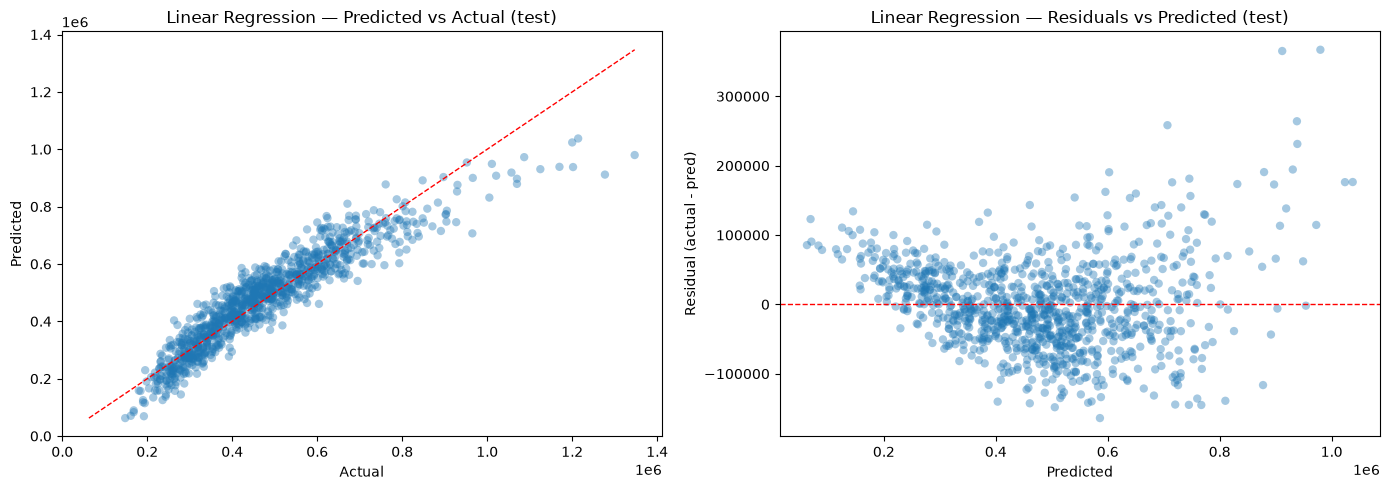

In [19]:
model=LinearRegression(n_jobs=-1)
result, decile_df=store_results_regression("Linear Regression", X_train_s, y_train, X_test_s, y_test, model, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result], ignore_index=True)

In [20]:
pd.options.display.max_columns=500
Model_Comparison

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.984,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.742,367148.2516,0.8708,0.8667,10.967,11.01,0.863,0.0086,65692.239,903.6695,49694.0167,516.129,11.3,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.429,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.29,0.576,0.56,0.8625,0.864,186483.0031,149110.7007,1110675.0,981203.3888,198511.0211,172624.8666,1136500.0,964263.2287,123804.4464,93394.27,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.389,810420.0,778939.5032,N/A,N/A


In [21]:
decile_df

,decile,n,mean_pred,mean_actual,rmse,mae
0,1,100.0,203459.834691,251530.0,58751.921579,50568.045127
1,2,100.0,294842.382565,310840.0,39114.519503,32065.669314
2,3,100.0,359914.975367,348050.0,43145.455467,34077.690176
3,4,100.0,412240.121328,404950.0,46876.162434,37271.595839
4,5,100.0,458836.363698,436540.0,55494.991250,45035.778225
5,6,100.0,495987.740322,471490.0,52985.227235,42439.824705
6,7,100.0,533191.868630,504060.0,63849.497986,53941.125209
7,8,100.0,580106.688110,570700.0,68979.736559,54113.174867
8,9,100.0,648752.329847,643750.0,59953.611398,47568.833610
9,10,100.0,778939.503179,810420.0,113750.894819,89398.388989


### Regularization
**Regularization** is a process used to create an optimally complex model, i.e., a model which is as simple as possible while performing well on the training data. Through regularization, you try to strike the delicate balance between keeping the model simple and not making it too naive to be of any use.
The two main types of regularization are the following:

-  **Ridge Regression:** This type of regression penalizes large coefficients.
-  **Lasso:** `This penalizes large coefficients and also the number of coefficients.`
-  ElasticNet: Combines both for better control — often used when there are many correlated prctors.

### Alpha (λ) is the regularization strength — a hyperparameter that controls how much penalty is applied to large coefficients.

# Linear Regression with Lasso Regularization L1

## Steps Involved:

   
1. **Initialize Model**
   
2. **Fit the Model**
   
3. **Make Predictions**
   
4. **Evaluate the Model**

Train RMSE: 63930.9845   Test RMSE: 63617.0919
Train MAE:  48330.0709    Test MAE:  48754.5130
Train R^2:  0.8708    Test R^2:  0.8661


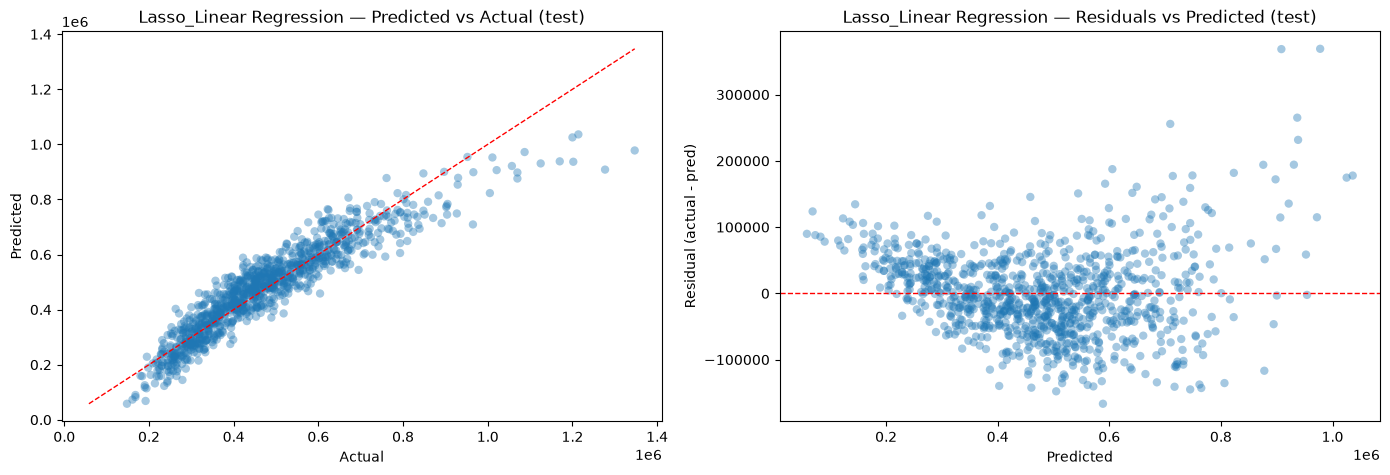

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.863,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.576,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,981203.3888,198511.0211,172624.8666,1136500.0,964263.2287,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.389,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.863,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.576,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,981199.9746,198781.4848,172407.9569,1136500.0,964554.6966,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.457,809850.0,778915.8852,L1,0.1


In [22]:
model_Lasso=Lasso(alpha=0.1,random_state=1234)
result_Lasso, decile_df_Lasso=store_results_regression("Lasso_Linear Regression", X_train_s, y_train, X_test_s, y_test, model_Lasso, 5,
                             norm="L1", alpha=0.1)
Model_Comparison=pd.concat([Model_Comparison, result_Lasso], ignore_index=True)
Model_Comparison

# Linear Regression with Ridge Regularization L2

Train RMSE: 63931.0309   Test RMSE: 63475.2908
Train MAE:  48326.0166    Test MAE:  48639.0784
Train R^2:  0.8708    Test R^2:  0.8667


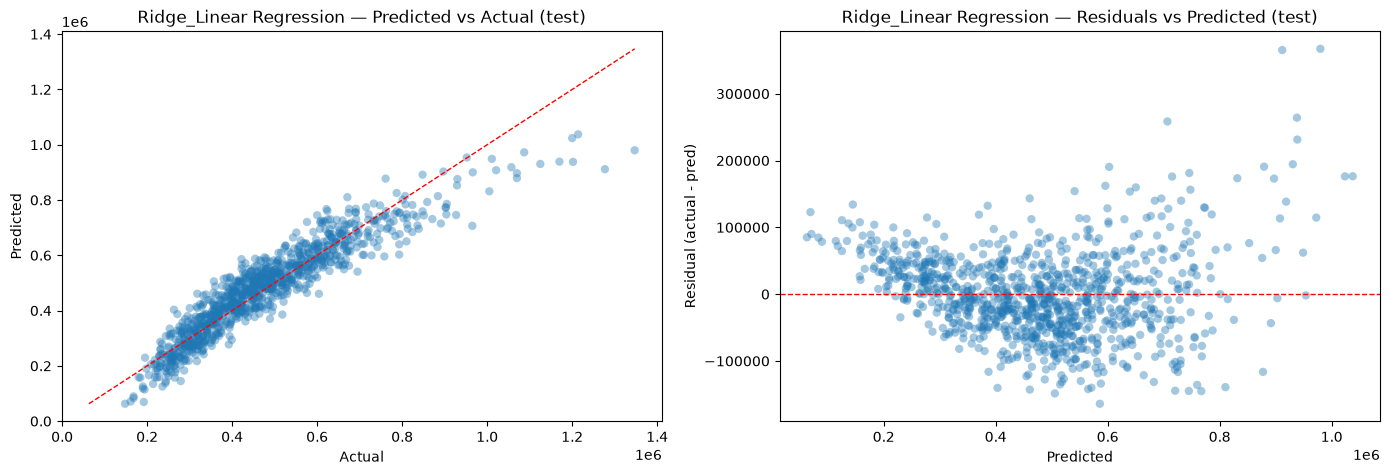

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.863,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.576,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,981203.3888,198511.0211,172624.8666,1136500.0,964263.2287,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.863,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.576,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,981199.9746,198781.4848,172407.9569,1136500.0,964554.6966,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.863,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.576,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,981130.4907,198559.8065,172673.2391,1136500.0,964200.7553,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1


In [23]:
model_Ridge=Ridge(alpha=0.1,random_state=1234)
result_Ridge, decile_df_Ridge=store_results_regression("Ridge_Linear Regression", X_train_s, y_train, X_test_s, y_test, model_Ridge, 5,
                             norm="L2", alpha=0.1)
Model_Comparison=pd.concat([Model_Comparison, result_Ridge], ignore_index=True)
Model_Comparison

# Linear Regression with Elastic Net Regularization

Train RMSE: 79945.7480   Test RMSE: 76623.9218
Train MAE:  58792.6170    Test MAE:  57378.0161
Train R^2:  0.7980    Test R^2:  0.8057


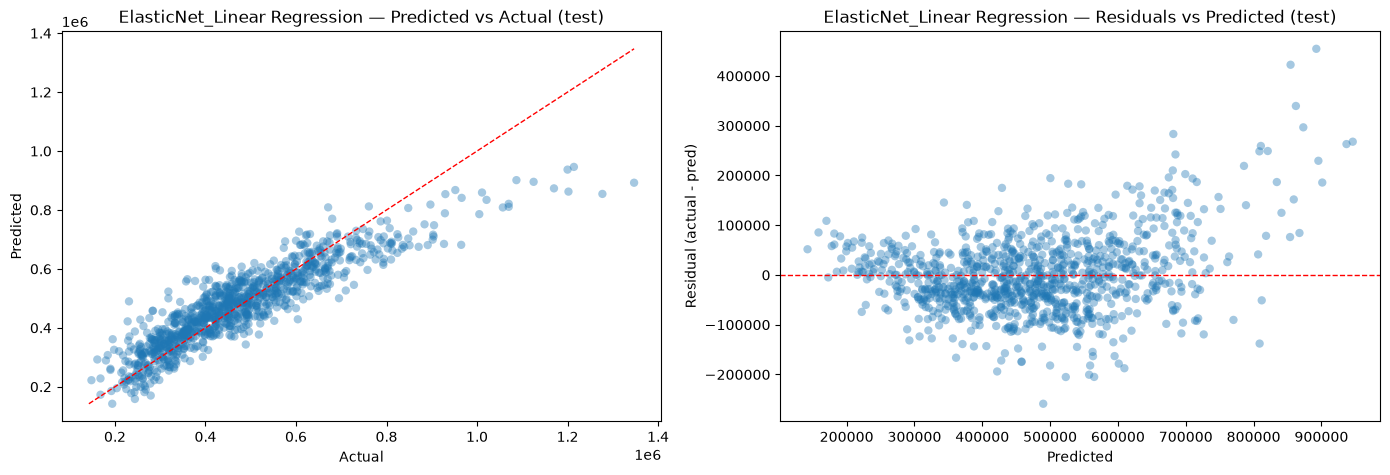

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.576,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,981203.3888,198511.0211,172624.8666,1136500.0,964263.2287,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.576,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,981199.9746,198781.4848,172407.9569,1136500.0,964554.6966,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.576,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,981130.4907,198559.8065,172673.2391,1136500.0,964200.7553,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.493,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,894242.7009,290978.5836,269553.3577,1158500.0,888946.6423,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,ElasticNet,0.1


In [24]:
model_ElasticNet=ElasticNet(alpha=0.1,random_state=1234,l1_ratio=0.5)
result_ElasticNet, decile_df_ElasticNet=store_results_regression("ElasticNet_Linear Regression", X_train_s, y_train, X_test_s, y_test, model_ElasticNet, 5,
                             norm="ElasticNet", alpha=0.1)
Model_Comparison=pd.concat([Model_Comparison, result_ElasticNet], ignore_index=True)
Model_Comparison

### Feature Selection
### Feature Selection Using RFE
Recursive Feature Elimination (RFE) is an automated feature elimination algorithm.Recursive feature elimination is based on the idea of repeatedly constructing a model (for example, an SVM or a regression model) and choosing either the best or the worst performing feature (for example, based on coefficients), setting the feature aside and then repeating the process with the rest of the features. This process is applied until all the features in the data set are exhausted. Features are then ranked according to when they were eliminated.  As such, it is a greedy optimisation for finding the best performing subset of features. The RFE object takes two arguments, a machine learning object and an integer, to represent the number of features to keep. RFE trains a model of the given ML algorithm, finds the least important feature, and eliminates it. Then it retrains a new model and again finds the least important feature to eliminate. This repeats until the specified number of features are left.

In [25]:
from sklearn.feature_selection import RFE


rfe = RFE(model_Ridge,n_features_to_select = 20)           # running RFE with 20 variable output. # 20 is a arbitrary number. 
rfe = rfe.fit(X_train_s, y_train)

In [26]:
col = X_train_s.columns[rfe.support_]
col

Index(['living_area_sqft', 'sale_year', 'city_Alma', 'city_Baie-Comeau',
       'city_Blainville', 'city_Châteauguay', 'city_Mirabel', 'city_Rimouski',
       'city_Rouyn-Noranda', 'city_Saguenay', 'city_Saint-Jean-sur-Richelieu',
       'city_Saint-Jérôme', 'city_Sept-Îles', 'city_Sherbrooke',
       'city_Val-d'Or', 'neighborhood_Baie-Comeau_Centre',
       'neighborhood_Sept-Îles_Centre', 'neighborhood_Val-d'Or_Centre',
       'property_type_Triplex', 'ProvLocation_PEast'],
      dtype='object')

### Dropped Columns after RFE

In [27]:
X_train_s.columns[~rfe.support_]

Index(['bedrooms', 'bathrooms', 'lot_size_sqft', 'year_built', 'garage',
       'basement', 'bedrooms_flag', 'bathrooms_flag', 'living_area_sqft_flag',
       'lot_size_sqft_flag',
       ...
       'neighborhood_West_Island', 'property_type_Bungalow',
       'property_type_Condo', 'property_type_Duplex',
       'property_type_Single_Family', 'property_type_Townhouse',
       'ProvLocation_PNorth', 'ProvLocation_PSouth', 'ProvLocation_PWest',
       'ProvLocation_nan'],
      dtype='object', length=113)

# """Decision Tree """

#### `So Decision Trees are not sensitve to missing values,Outliers,imbalanced data and do not require normalization`

In [28]:
X_train=X_train_tree.copy()
y_train =y_train_tree.copy()
X_test=X_test_tree.copy()
y_test = y_test_tree.copy()

In [29]:
X_train.describe()

,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,garage,basement,sale_year,renovated,sqft_relative_to_neighborhood,years_newer_than_neighborhood,city_Alma,city_Baie-Comeau,city_Blainville,city_Boucherville,city_Brossard,city_Candiac,city_Châteauguay,city_Dollard-des-Ormeaux,city_Drummondville,city_Gatineau,city_Granby,city_Laval,city_Longueuil,city_Lévis,city_Mirabel,city_Montréal,city_Pointe-Claire,city_Québec,city_Repentigny,city_Rimouski,city_Rouyn-Noranda,city_Saguenay,city_Saint-Bruno-de-Montarville,city_Saint-Jean-sur-Richelieu,city_Saint-Jérôme,city_Sept-Îles,city_Sherbrooke,city_Terrebonne,city_Trois-Rivières,city_Val-d'Or,city_Vaudreuil-Dorion,city_Victoriaville,neighborhood_Ahuntsic,neighborhood_Alma_Centre,neighborhood_Aylmer,neighborhood_Baie-Comeau_Centre,neighborhood_Beauport,neighborhood_Bellefeuille,neighborhood_Blainville_Centre,neighborhood_Boucherville_Centre,neighborhood_Buckingham,neighborhood_Candiac_Centre,neighborhood_Cap-de-la-Madeleine,neighborhood_Centre-Ville,neighborhood_Charlesbourg,neighborhood_Charny,neighborhood_Chicoutimi,neighborhood_Chomedey,neighborhood_Duvernay,neighborhood_Fabreville,neighborhood_Fleurimont,neighborhood_Gatineau_Centre,neighborhood_Greenfield_Park,neighborhood_Hochelaga-Maisonneuve,neighborhood_Hull,neighborhood_Iberville,neighborhood_Jonquière,neighborhood_La_Baie,neighborhood_La_Plaine,neighborhood_LaSalle,neighborhood_Lachenaie,neighborhood_Lachine,neighborhood_Le_Gardeur,neighborhood_Le_Vieux-Longueuil,neighborhood_Lebourgneuf,neighborhood_Lennoxville,neighborhood_Limoilou,neighborhood_Lévis_Centre,neighborhood_Mercier,neighborhood_NDG,neighborhood_Outremont,neighborhood_Plateau-Mont-Royal,neighborhood_Pointe-aux-Trembles,neighborhood_Pont-Viau,neighborhood_Repentigny_Centre,neighborhood_Rimouski_Centre,neighborhood_Rock_Forest,neighborhood_Rosemont,neighborhood_Rouyn_Centre,neighborhood_Saint-Canut,neighborhood_Saint-Charles,neighborhood_Saint-Hubert,neighborhood_Saint-Léonard,neighborhood_Saint-Nicolas,neighborhood_Sainte-Dorothée,neighborhood_Sainte-Foy,neighborhood_Sainte-Monique,neighborhood_Secteur_A,neighborhood_Secteur_B,neighborhood_Secteur_C,neighborhood_Sept-Îles_Centre,neighborhood_Sillery,neighborhood_Solar_Uniquartier,neighborhood_Terrebonne_Ouest,neighborhood_Trois-Rivières-Ouest,neighborhood_Val-Bélair,neighborhood_Val-d'Or_Centre,neighborhood_Vanier,neighborhood_Verdun,neighborhood_Vieux-Longueuil,neighborhood_Ville-Marie,neighborhood_Villeray,neighborhood_Vimont,neighborhood_West_Island,property_type_Bungalow,property_type_Condo,property_type_Duplex,property_type_Single_Family,property_type_Townhouse,property_type_Triplex,ProvLocation_PEast,ProvLocation_PNorth,ProvLocation_PSouth,ProvLocation_PWest,ProvLocation_nan
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.00000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.00000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.00000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.00

Train RMSE: 115679.9226   Test RMSE: 117137.1788
Train MAE:  89402.2854    Test MAE:  89776.0444
Train R^2:  0.5771    Test R^2:  0.5460


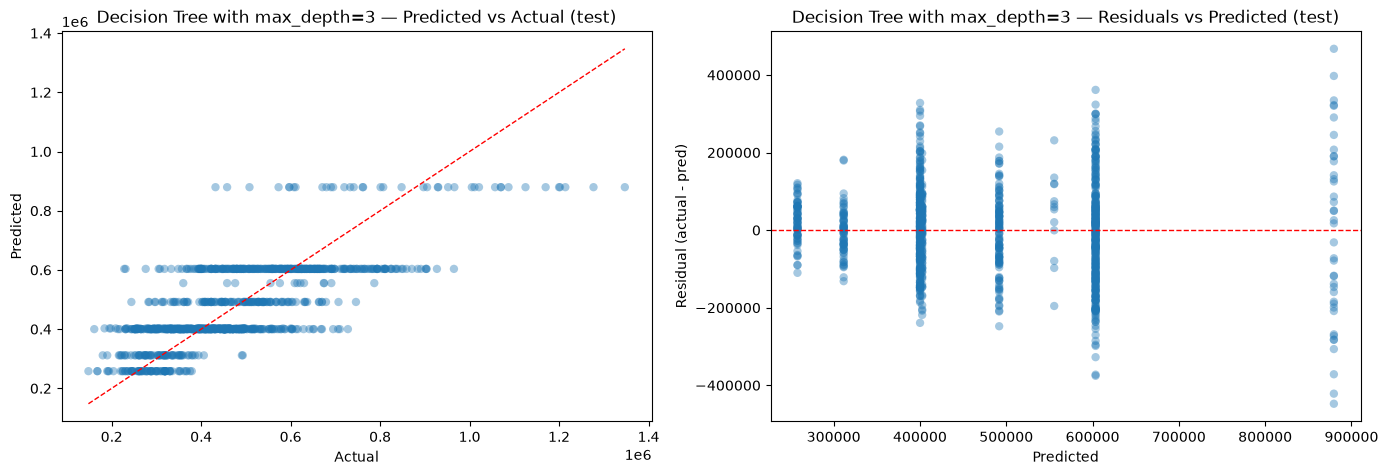

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.576,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,981203.3888,198511.0211,172624.8666,1136500.0,964263.2287,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.576,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,981199.9746,198781.4848,172407.9569,1136500.0,964554.6966,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.576,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,981130.4907,198559.8065,172673.2391,1136500.0,964200.7553,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.493,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,894242.7009,290978.5836,269553.3577,1158500.0,888946.6423,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,ElasticNet,0.1
4,D

In [30]:
model_DT=DecisionTreeRegressor(max_depth=3,random_state=1234)
result_DT, decile_df_DT=store_results_regression("Decision Tree with max_depth=3", X_train, y_train, X_test, y_test, model_DT, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result_DT], ignore_index=True)
Model_Comparison

# Visualize Decision Tree

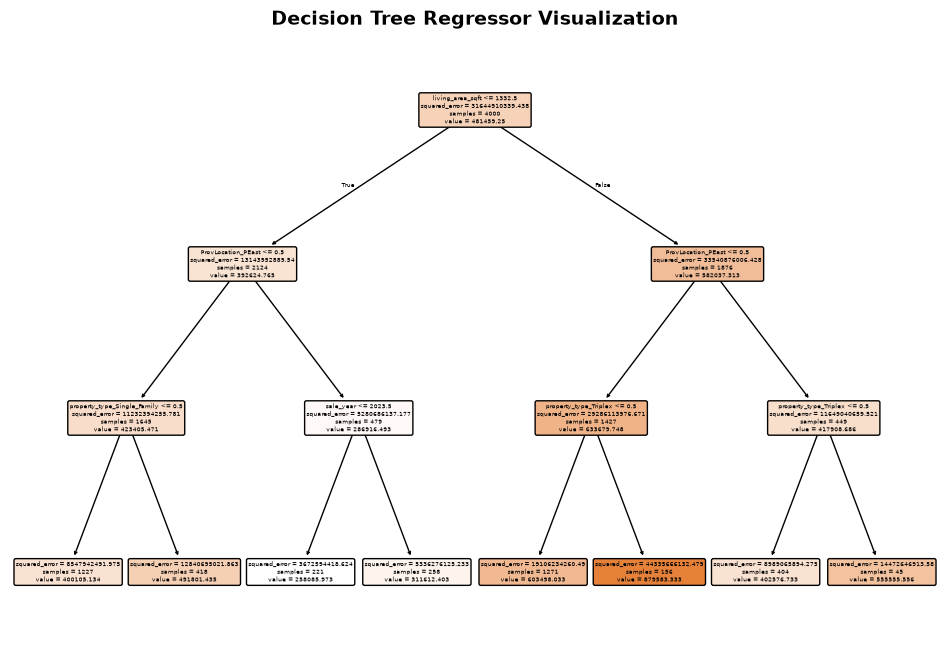

In [31]:
from sklearn.tree import plot_tree
feature_names1=list(X_train.columns)
plt.figure(figsize=(12, 8))
plot_tree(
    model_DT,
    feature_names=feature_names1,
    max_depth=3,
    filled=True,
    rounded=True
)
plt.title("Decision Tree Regressor Visualization", fontsize=14, fontweight='bold')
plt.show()

# Exporting Decision Tree Rules (Text Format)

In [32]:
from sklearn.tree import export_text

rules = export_text(model_DT, feature_names=feature_names1)
print(rules)

|--- living_area_sqft <= 1332.50
|   |--- ProvLocation_PEast <= 0.50
|   |   |--- property_type_Single_Family <= 0.50
|   |   |   |--- value: [400105.13]
|   |   |--- property_type_Single_Family >  0.50
|   |   |   |--- value: [491801.44]
|   |--- ProvLocation_PEast >  0.50
|   |   |--- sale_year <= 2023.50
|   |   |   |--- value: [258085.97]
|   |   |--- sale_year >  2023.50
|   |   |   |--- value: [311612.40]
|--- living_area_sqft >  1332.50
|   |--- ProvLocation_PEast <= 0.50
|   |   |--- property_type_Triplex <= 0.50
|   |   |   |--- value: [603498.03]
|   |   |--- property_type_Triplex >  0.50
|   |   |   |--- value: [879583.33]
|   |--- ProvLocation_PEast >  0.50
|   |   |--- property_type_Triplex <= 0.50
|   |   |   |--- value: [402576.73]
|   |   |--- property_type_Triplex >  0.50
|   |   |   |--- value: [555555.56]



In [33]:
from sklearn.tree import _tree
def get_rules(tree, feature_names):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]
    def recurse(node, depth):
        indent = "  " * depth
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            print(f"{indent}if {name} <= {threshold:.2f}:")
            recurse(tree_.children_left[node], depth + 1)
            print(f"{indent}else:  # if {name} > {threshold:.2f}")
            recurse(tree_.children_right[node], depth + 1)
        else:
            print(f"{indent}return {tree_.value[node]}")

    recurse(0, 0)

In [34]:
scores=[]
for i in range(1,20):
    dt=DecisionTreeRegressor(max_depth=i,random_state=1234)
    scores.append(cross_val_score(dt,X_train,y_train,cv=4).mean())

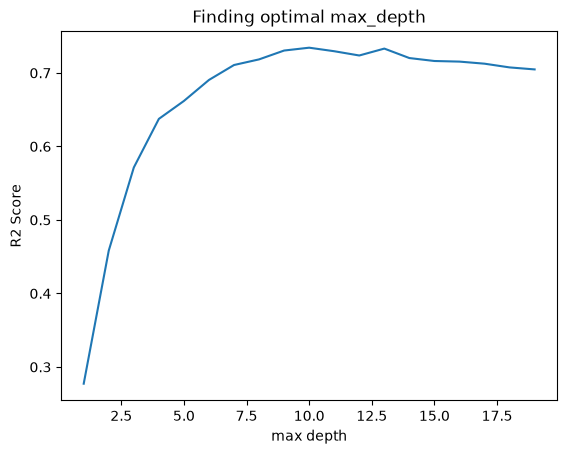

In [35]:
plt.plot(range(1,20),scores)
plt.xlabel('max depth')
plt.ylabel('R2 Score')
plt.title("Finding optimal max_depth")
plt.show()

# Hyperparameter Tuning with Grid Search and Cross Validation

In [36]:
param_grid_dt = {
    'criterion': ['squared_error',  'absolute_error'],
    'max_depth': range(3,12),
    'min_samples_split': [5, 10, 20],
    'min_samples_leaf': [2,3] #min_samples_leaf = the minimum number of samples (rows) that must be present in a leaf node(A leaf node is the final node that makes a final prediction, numeric average
}

In [37]:
from sklearn.model_selection import KFold
dt=DecisionTreeRegressor(random_state=1234)
cv=KFold(n_splits=4,shuffle=True,random_state=1234)
grid=GridSearchCV(estimator=dt,
             param_grid=param_grid_dt,
                 scoring={'R2':'r2',
                         'Neg_MSE':'neg_mean_squared_error',
                         'Neg_MAE':'neg_mean_absolute_error'},
                  refit='R2',
                  cv=cv,
                  n_jobs=-1,
                  verbose=1
             )
grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best R2:", grid.best_score_)

Fitting 4 folds for each of 108 candidates, totalling 432 fits
Best Parameters: {'criterion': 'squared_error', 'max_depth': 11, 'min_samples_leaf': 2, 'min_samples_split': 20}
Best R2: 0.741420122085789


In [38]:
# All CV results
cvres = pd.DataFrame(grid.cv_results_)
cvres.head(2)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_criterion,param_max_depth,param_min_samples_leaf,param_min_samples_split,params,split0_test_R2,split1_test_R2,split2_test_R2,split3_test_R2,mean_test_R2,std_test_R2,rank_test_R2,split0_test_Neg_MSE,split1_test_Neg_MSE,split2_test_Neg_MSE,split3_test_Neg_MSE,mean_test_Neg_MSE,std_test_Neg_MSE,rank_test_Neg_MSE,split0_test_Neg_MAE,split1_test_Neg_MAE,split2_test_Neg_MAE,split3_test_Neg_MAE,mean_test_Neg_MAE,std_test_Neg_MAE,rank_test_Neg_MAE
0,0.063458,0.005254,0.008381,0.002450,squared_error,3,2,5,"{'criterion': 'squared_error', 'max_depth': 3,...",0.597677,0.527395,0.599328,0.550553,0.568738,0.030875,97,-1.363359e+10,-1.385305e+10,-1.323838e+10,-1.359331e+10,-1.357958e+10,2.204007e+08,97,-89464.205428,-91339.086085,-88182.313114,-91420.168897,-90101.443381,1356.459513,97
1,0.061958,0.004415,0.007363,0.002025,squared_error,3,2,10,"{'criterion': 'squared_error', 'max_depth': 3,...",0.597677,0.527395,0.599328,0.550553,0.568738,0.030875,97,-1.363359e+10,-1.385305e+10,-1.323838e+10,-1.359331e+10,-1.357958e+10,2.204007e+08,97,-89464.205428,-91339.086085,-88182.313114,-91420.168897,-90101.443381,1356.459513,97


In [39]:
grid.cv_results_.keys()

dict_keys(['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'param_criterion', 'param_max_depth', 'param_min_samples_leaf', 'param_min_samples_split', 'params', 'split0_test_R2', 'split1_test_R2', 'split2_test_R2', 'split3_test_R2', 'mean_test_R2', 'std_test_R2', 'rank_test_R2', 'split0_test_Neg_MSE', 'split1_test_Neg_MSE', 'split2_test_Neg_MSE', 'split3_test_Neg_MSE', 'mean_test_Neg_MSE', 'std_test_Neg_MSE', 'rank_test_Neg_MSE', 'split0_test_Neg_MAE', 'split1_test_Neg_MAE', 'split2_test_Neg_MAE', 'split3_test_Neg_MAE', 'mean_test_Neg_MAE', 'std_test_Neg_MAE', 'rank_test_Neg_MAE'])

In [40]:
# Columns for your three metrics
keep = [
    'param_criterion', 'param_max_depth', 'param_min_samples_leaf', 'param_min_samples_split','params',
  'mean_test_R2','std_test_R2','mean_test_Neg_MSE','rank_test_Neg_MSE', 'std_test_Neg_MSE', 'rank_test_Neg_MSE',
    'mean_test_Neg_MAE', 'std_test_Neg_MAE','rank_test_R2'
]
pd.set_option('display.max_colwidth', None)
# View top rows sorted by the R2 rank
cvres[keep].sort_values('rank_test_R2').head(3)

,param_criterion,param_max_depth,param_min_samples_leaf,param_min_samples_split,params,mean_test_R2,std_test_R2,mean_test_Neg_MSE,rank_test_Neg_MSE,std_test_Neg_MSE,rank_test_Neg_MSE,mean_test_Neg_MAE,std_test_Neg_MAE,rank_test_R2
50,squared_error,11,2,20,"{'criterion': 'squared_error', 'max_depth': 11, 'min_samples_leaf': 2, 'min_samples_split': 20}",0.741420,0.025715,-8.130492e+09,1,3.589416e+08,1,-66147.959857,1078.455564,1
44,squared_error,10,2,20,"{'criterion': 'squared_error', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 20}",0.740627,0.027466,-8.154111e+09,2,4.321200e+08,2,-66383.142479,1486.157915,2
104,absolute_error,11,2,20,"{'criterion': 'absolute_error', 'max_depth': 11, 'min_samples_leaf': 2, 'min_samples_split': 20}",0.737748,0.015990,-8.274891e+09,4,4.494324e+08,4,-67163.750000,737.944315,3


Train RMSE: 69057.7857   Test RMSE: 82327.3625
Train MAE:  51406.4732    Test MAE:  62785.4727
Train R^2:  0.8493    Test R^2:  0.7758


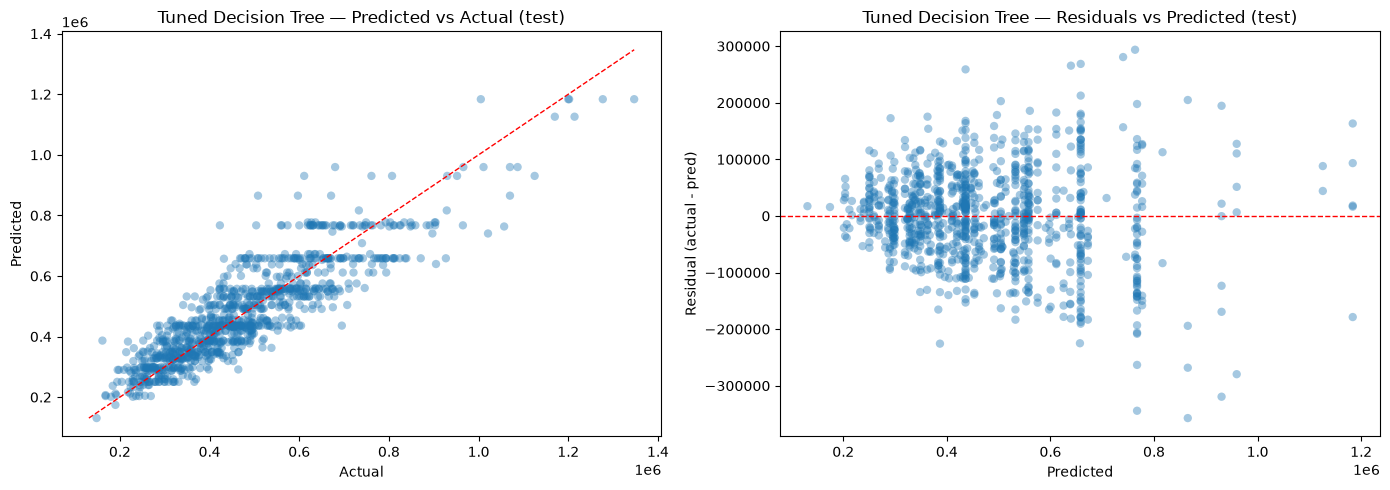

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,Elasti

In [41]:
DT_Tuned=grid.best_estimator_
result_DT_tuned, decile_df_DT_tuned=store_results_regression("Tuned Decision Tree", X_train, y_train, X_test, y_test, DT_Tuned, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result_DT_tuned], ignore_index=True)
Model_Comparison

## Ensemble learning models

Train RMSE: 30977.0084   Test RMSE: 70271.1964
Train MAE:  21612.2250    Test MAE:  52355.7000
Train R^2:  0.9697    Test R^2:  0.8366


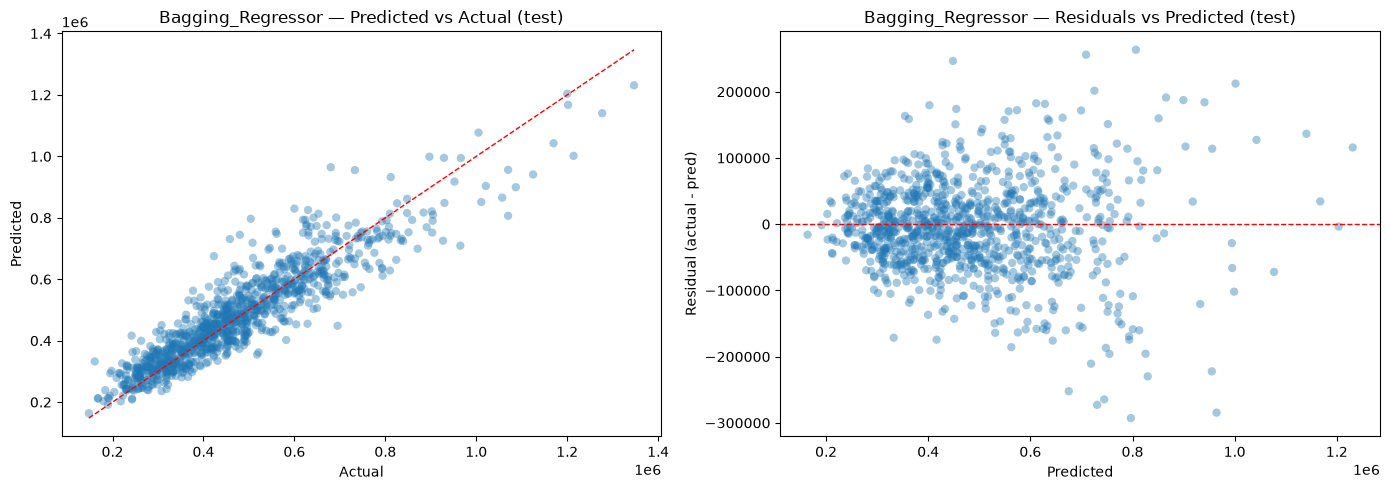

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,Elasti

In [42]:
model_Bag_Reg=BaggingRegressor(random_state=1234, n_jobs=-1) #default n_estimators=10
result_Bag, decile_df_Bag=store_results_regression("Bagging_Regressor", X_train, y_train, X_test, y_test, model_Bag_Reg, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result_Bag], ignore_index=True)
Model_Comparison

## Random Forest

Train RMSE: 26333.3083   Test RMSE: 66991.7015
Train MAE:  19592.6125    Test MAE:  50782.9000
Train R^2:  0.9781    Test R^2:  0.8515


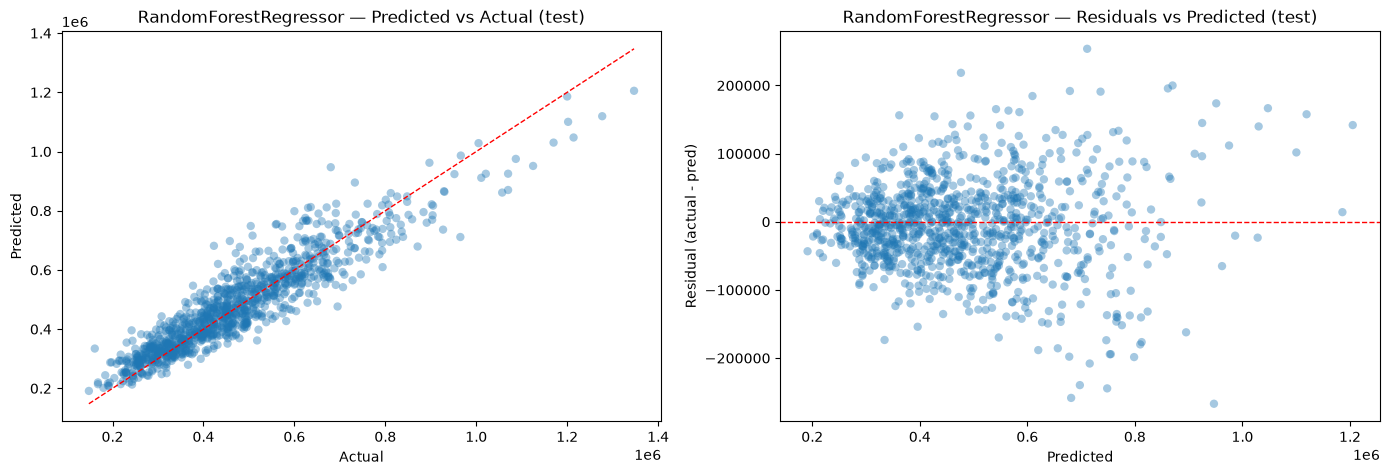

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,Elasti

In [43]:
model_RF1=RandomForestRegressor(random_state=1234, n_jobs=-1) 
result_RF1, decile_df_RF1=store_results_regression("RandomForestRegressor", X_train, y_train, X_test, y_test, model_RF1, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result_RF1], ignore_index=True)
Model_Comparison

## Tuning

In [44]:
param_grid={'n_estimators':[100,150,200],#range(10,110,10),
            'max_depth':[3,5,7],
            'min_samples_split':[3,5],
            'criterion':['squared_error', 'absolute_error']}

grid2 = GridSearchCV(
    RandomForestRegressor(n_jobs=-1,random_state=1234),
    param_grid,
    cv=5,
    scoring='r2',  # PR_AUC (Precision-Recall)
    return_train_score=True  # Get training scores too
)

# fit the model
grid2.fit(X_train, y_train)

# Analyze results
results_df = pd.DataFrame(grid2.cv_results_)
results_df['gap'] = results_df['mean_train_score'] - results_df['mean_test_score']

# Sort by test R² (high to low) then by gap (small to large)
results_df_sorted = results_df.sort_values(
    ['mean_test_score', 'gap'], 
    ascending=[False, True]
)

# Display top candidates
print("Top models by R² with smallest gap:")
print(results_df_sorted[['params', 'mean_test_score', 'mean_train_score', 'gap']].head(10))

# Get the best model details
best_idx = results_df_sorted.index[0]
best_params = results_df.loc[best_idx, 'params']

print(f"\n Best params: {best_params}")
print(f"  Test R²: {results_df.loc[best_idx, 'mean_test_score']:.4f}")
print(f"  Train R²: {results_df.loc[best_idx, 'mean_train_score']:.4f}")
print(f"  Gap: {results_df.loc[best_idx, 'gap']:.4f}")

# Use the best estimator
best_model = grid2.best_estimator_

Top models by R² with smallest gap:
                                                                                          params  \
31  {'criterion': 'absolute_error', 'max_depth': 7, 'min_samples_split': 3, 'n_estimators': 150}   
34  {'criterion': 'absolute_error', 'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 150}   
32  {'criterion': 'absolute_error', 'max_depth': 7, 'min_samples_split': 3, 'n_estimators': 200}   
35  {'criterion': 'absolute_error', 'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 200}   
13   {'criterion': 'squared_error', 'max_depth': 7, 'min_samples_split': 3, 'n_estimators': 150}   
14   {'criterion': 'squared_error', 'max_depth': 7, 'min_samples_split': 3, 'n_estimators': 200}   
16   {'criterion': 'squared_error', 'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 150}   
17   {'criterion': 'squared_error', 'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 200}   
30  {'criterion': 'absolute_error', 'max_depth': 7, 'min_samples

Train RMSE: 76578.3650   Test RMSE: 83692.4631
Train MAE:  57783.8658    Test MAE:  64872.6900
Train R^2:  0.8147    Test R^2:  0.7683


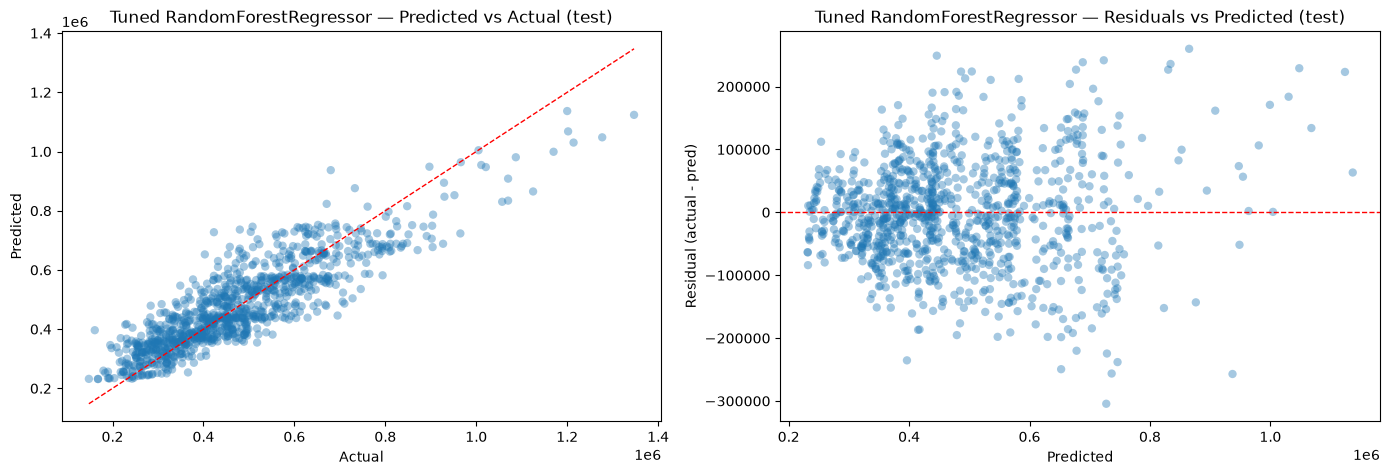

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,Elasti

In [45]:
model_RF2=grid2.best_estimator_
result_RF2, decile_df_RF2=store_results_regression("Tuned RandomForestRegressor", X_train, y_train, X_test, y_test, model_RF2, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result_RF2], ignore_index=True)
Model_Comparison

##  Bayesian Method

In [46]:
search_spaces={'n_estimators':[100,150,200],#range(10,110,10),
            'max_depth':[3,5,7],
            'min_samples_split':[3,5],
            'criterion':['squared_error', 'absolute_error']}
# Define model
rf = RandomForestRegressor(random_state=1234, n_jobs=-1)

# Bayesian Optimization
opt = BayesSearchCV(
    estimator=rf,
    search_spaces=search_spaces,
    scoring='r2',  # R2-Coefficient of Determination
    cv=5,
    n_iter=30,             # number of iterations (trials)
    random_state=1234,
    n_jobs=-1
)

# Fit optimizer
opt.fit(X_train, y_train)

# Best parameters
print("Best Parameters:", opt.best_params_)
print("Best R2 Score:", opt.best_score_)

Best Parameters: OrderedDict({'criterion': 'absolute_error', 'max_depth': 7, 'min_samples_split': 3, 'n_estimators': 150})
Best R2 Score: 0.7696631603806479


Train RMSE: 69057.7857   Test RMSE: 82327.3625
Train MAE:  51406.4732    Test MAE:  62785.4727
Train R^2:  0.8493    Test R^2:  0.7758


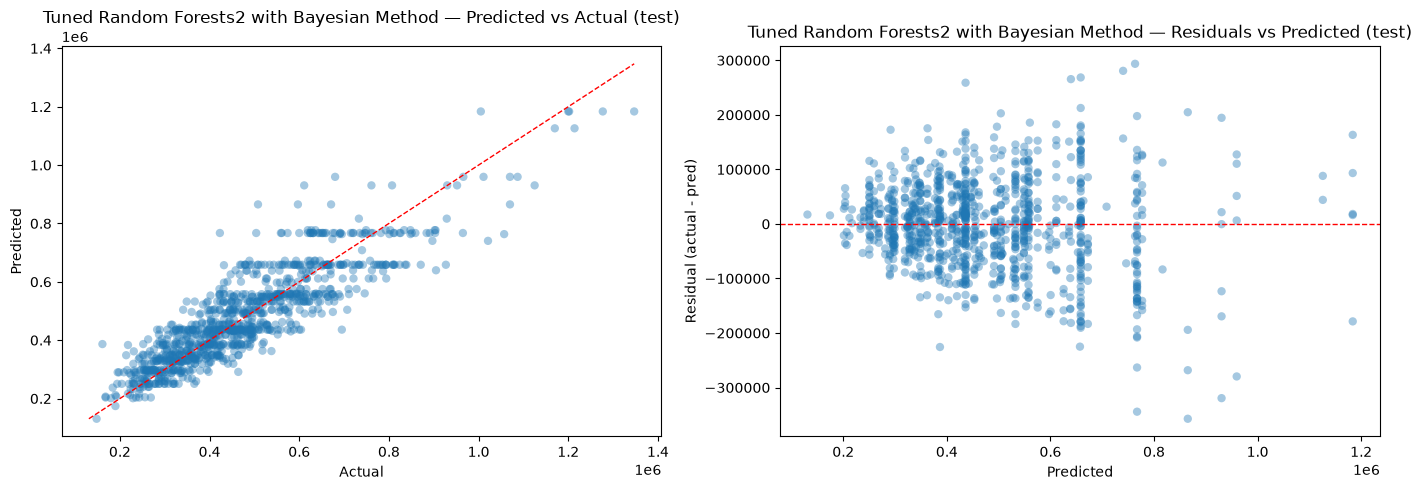

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,Elasti

In [47]:
model_RF3=grid.best_estimator_
result_RF3, decile_df_RF3=store_results_regression("Tuned Random Forests2 with Bayesian Method", X_train, y_train, X_test, y_test, model_RF3, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result_RF3], ignore_index=True)
Model_Comparison

## Feature Importance

In [48]:
feature_importances = model_RF3.feature_importances_
features = X_train.columns
feature_importances_df = pd.DataFrame({'features': features, 'importance': feature_importances})
feature_importances_df.sort_values(by="importance", ascending=False).reset_index(drop=True)

,features,importance
0,living_area_sqft,0.380340
1,ProvLocation_PEast,0.212197
2,property_type_Triplex,0.107331
3,sale_year,0.093359
4,city_Sherbrooke,0.024851
...,...,...
121,neighborhood_West_Island,0.000000
122,neighborhood_Ville-Marie,0.000000
123,neighborhood_Vieux-Longueuil,0.000000
124,neighborhood_Villeray,0.000000


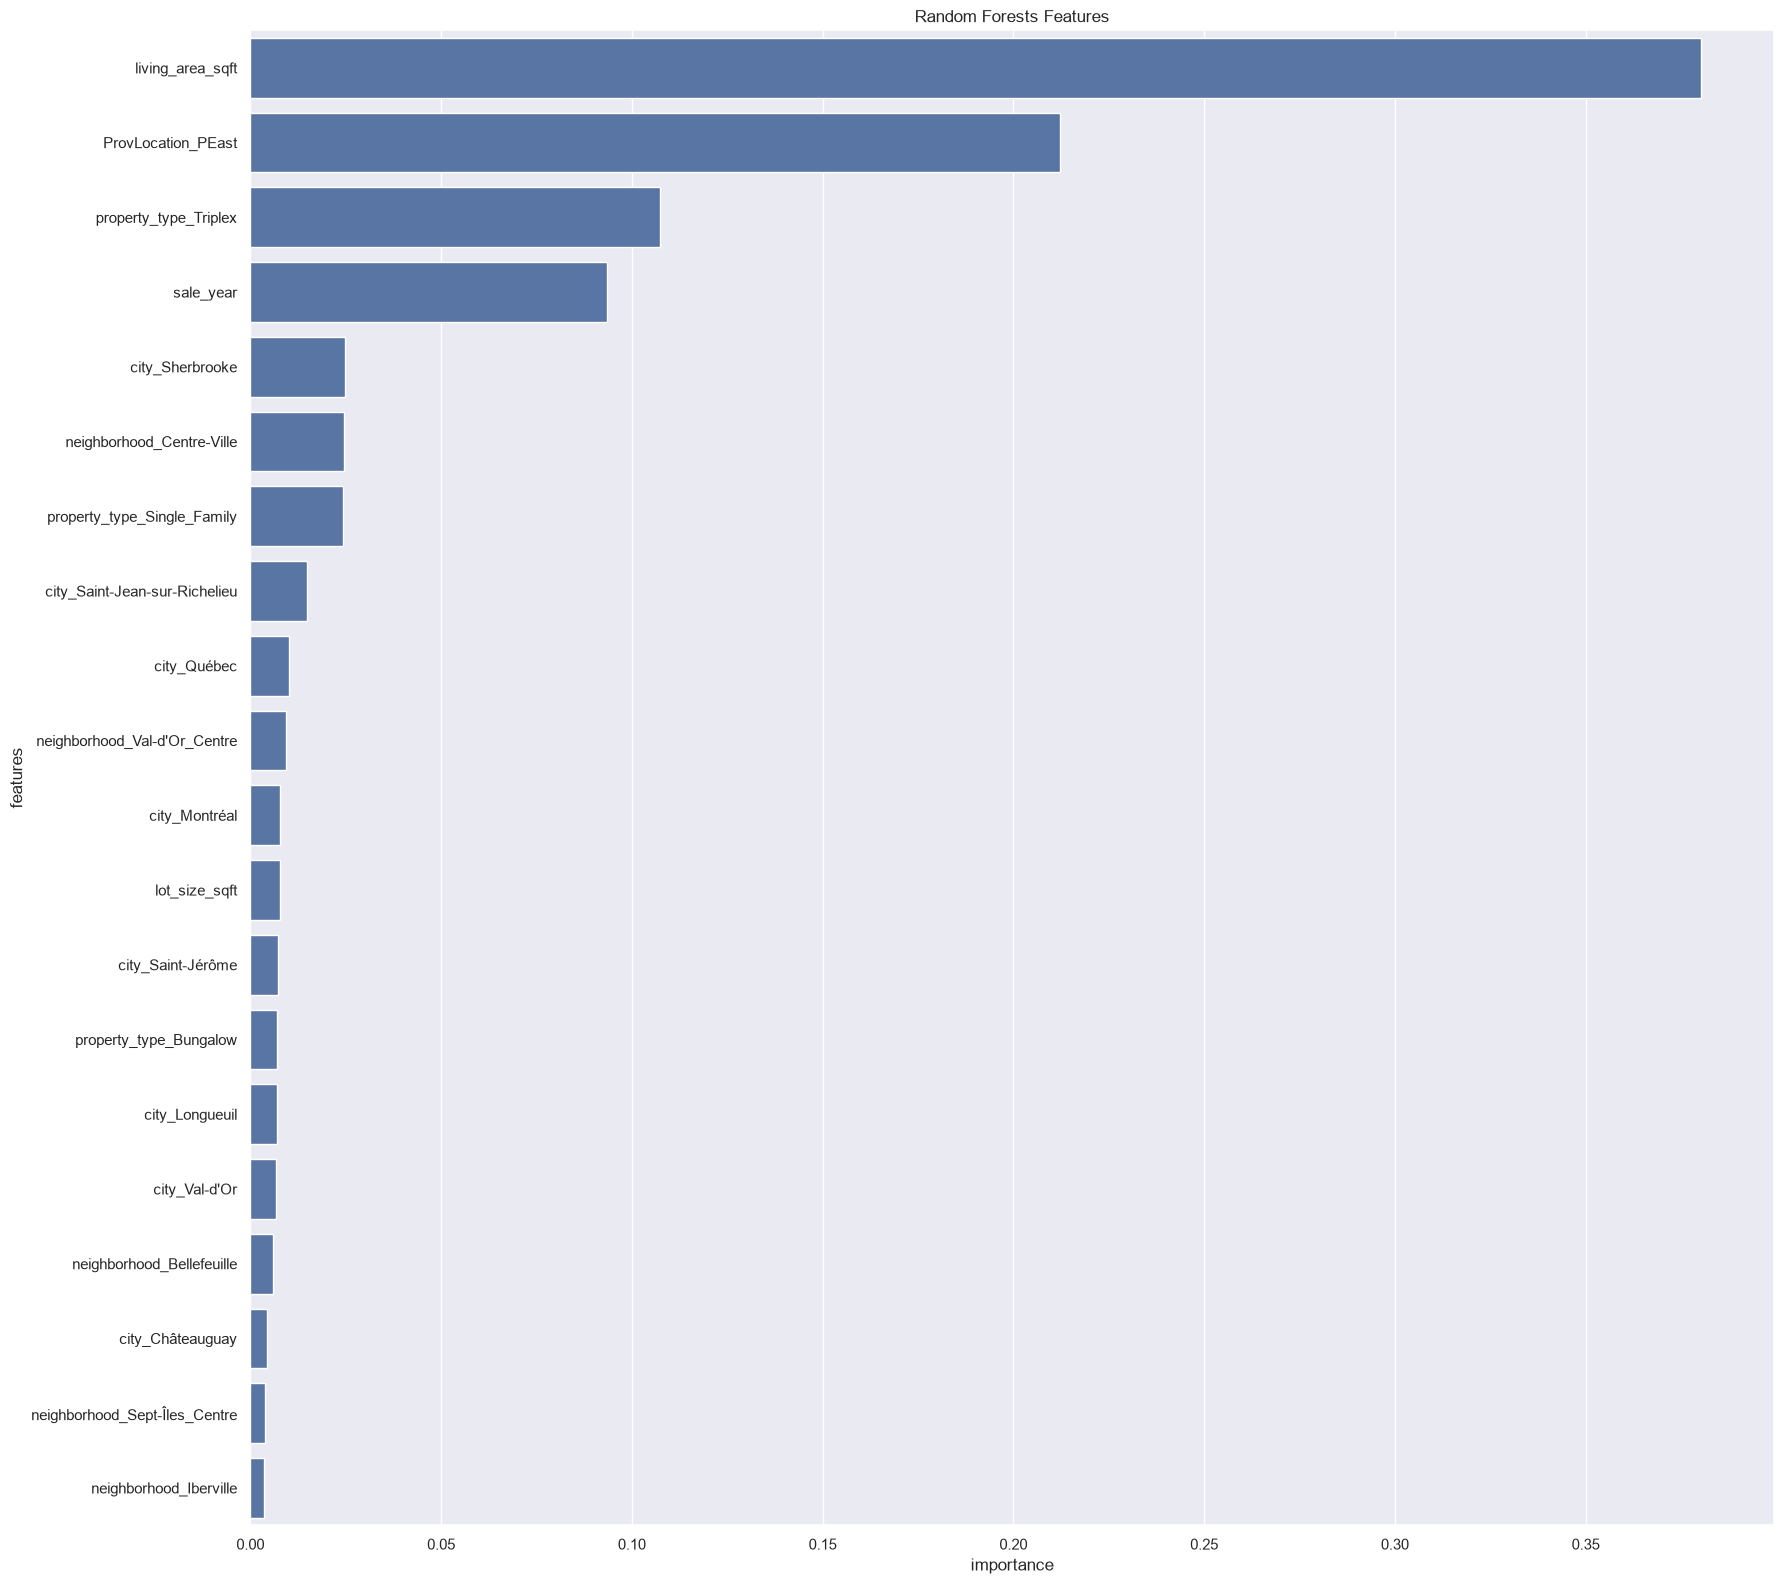

In [49]:
imp=feature_importances_df.sort_values(by="importance", ascending=False).head(20)
plt.figure(figsize=(18, 16))
sns.set(font_scale = 1)
sns.barplot(x="importance", y="features", data=imp.sort_values(by="importance", ascending=False))
plt.title('Random Forests Features')
plt.tight_layout()
plt.show()

## Customizing metric for Tuning

In [50]:
# ===== 1. BAYESIAN SEARCH =====
search_spaces = {
    'n_estimators': [100, 150, 200],
    'max_depth': [3, 5, 7],
    'min_samples_split': [3, 5],
    'criterion': ['squared_error', 'absolute_error']
}

rf = RandomForestRegressor(random_state=1234, n_jobs=-1)

opt = BayesSearchCV(
    estimator=rf,
    search_spaces=search_spaces,
    scoring='r2',
    cv=5,
    n_iter=30,
    random_state=1234,
    n_jobs=-1,
    return_train_score=True
)

opt.fit(X_train, y_train)

# ===== 2. PENALIZE BY GAP =====
results_df = pd.DataFrame(opt.cv_results_)
results_df['gap'] = results_df['mean_train_score'] - results_df['mean_test_score']

gap_penalty_weight = 0.5
results_df['penalized_score'] = results_df['mean_test_score'] - (gap_penalty_weight * results_df['gap'])

# ===== 3. GET BEST MODEL =====
best_idx = results_df['penalized_score'].idxmax()
best_params = results_df.loc[best_idx, 'params']

print("="*70)
print("BEST MODEL")
print("="*70)
print(f"Parameters: {best_params}")
print(f"CV Test R2:  {results_df.loc[best_idx, 'mean_test_score']:.4f}")
print(f"CV Train R2: {results_df.loc[best_idx, 'mean_train_score']:.4f}")
print(f"Gap:             {results_df.loc[best_idx, 'gap']:.4f}")
print(f"Penalized Score: {results_df.loc[best_idx, 'penalized_score']:.4f}")
print("="*70)

# ===== 4. TRAIN FINAL MODEL WITH BEST PARAMS =====
best_model = RandomForestRegressor(
    **best_params,
    n_jobs=-1,
    random_state=1234
)
best_model.fit(X_train, y_train)
'''
# ===== 5. EVALUATE ON TEST SET =====

y_pred = best_model.predict(X_test)

test_r2 = r2_score(y_test, y_pred)
test_mse=mean_squared_error(y_test,y_pred)
test_rmse=np.sqrt(test_mse)

print(f"\nTest Set Performance:")
print(f"R2 Score: {test_r2:.4f}")
rint(f"MSE:      {test_mse:.4f}  (Lower is better)")
print(f"RMSE:     {test_rmse:.4f}  (In original target units; lower is better)")


print(f"\nClassification Report:")
print(classification_report(y_test, y_pred))
print(f"\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# ===== 6. USE BEST MODEL FOR PREDICTIONS =====
# On new data
new_predictions = best_model.predict(X_new)


print(f"\nSample predictions (continuous values): {new_predictions[:5]}")
print(f"Sample probabilities: {new_probabilities[:5]}")

# ===== 7. SAVE BEST MODEL (optional) =====
import joblib
joblib.dump(best_model, 'best_rf_model.pkl')
print("\nModel saved as 'best_rf_model.pkl'")
'''
# Later: Load the model
# best_model = joblib.load('best_rf_model.pkl')

BEST MODEL
Parameters: OrderedDict({'criterion': 'absolute_error', 'max_depth': 7, 'min_samples_split': 3, 'n_estimators': 150})
CV Test R2:  0.7697
CV Train R2: 0.8203
Gap:             0.0506
Penalized Score: 0.7444


'\n# ===== 5. EVALUATE ON TEST SET =====\n\ny_pred = best_model.predict(X_test)\n\ntest_r2 = r2_score(y_test, y_pred)\ntest_mse=mean_squared_error(y_test,y_pred)\ntest_rmse=np.sqrt(test_mse)\n\nprint(f"\nTest Set Performance:")\nprint(f"R2 Score: {test_r2:.4f}")\nrint(f"MSE:      {test_mse:.4f}  (Lower is better)")\nprint(f"RMSE:     {test_rmse:.4f}  (In original target units; lower is better)")\n\n\nprint(f"\nClassification Report:")\nprint(classification_report(y_test, y_pred))\nprint(f"\nConfusion Matrix:")\nprint(confusion_matrix(y_test, y_pred))\n\n# ===== 6. USE BEST MODEL FOR PREDICTIONS =====\n# On new data\nnew_predictions = best_model.predict(X_new)\n\n\nprint(f"\nSample predictions (continuous values): {new_predictions[:5]}")\nprint(f"Sample probabilities: {new_probabilities[:5]}")\n\n# ===== 7. SAVE BEST MODEL (optional) =====\nimport joblib\njoblib.dump(best_model, \'best_rf_model.pkl\')\nprint("\nModel saved as \'best_rf_model.pkl\'")\n'

Train RMSE: 76578.3650   Test RMSE: 83692.4631
Train MAE:  57783.8658    Test MAE:  64872.6900
Train R^2:  0.8147    Test R^2:  0.7683


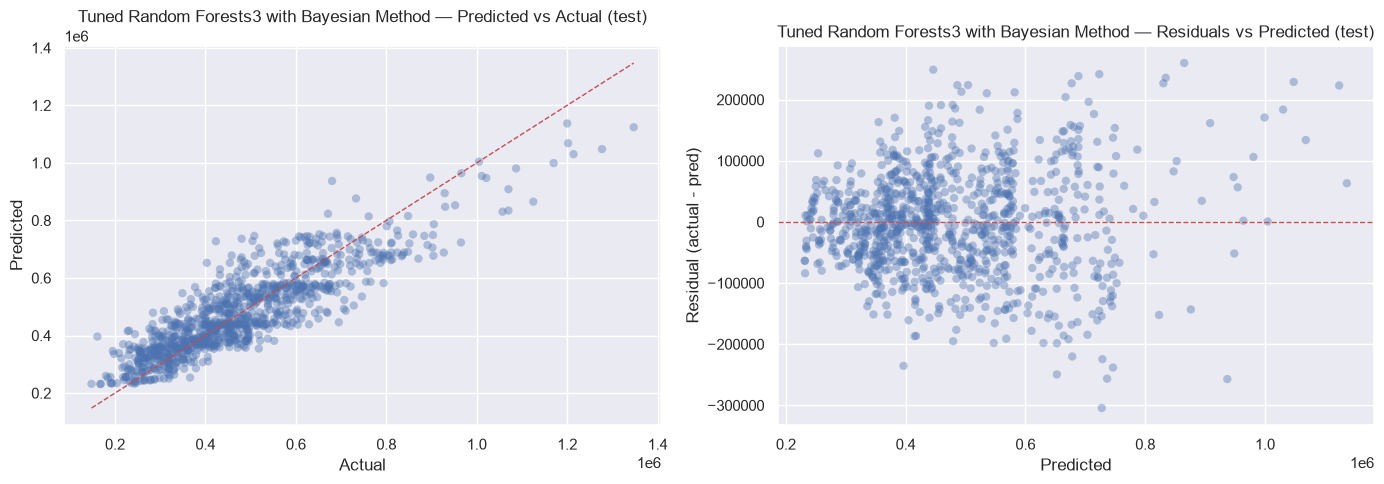

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,Elasti

In [51]:
model_RF4=best_model
result_RF4, decile_df_RF4=store_results_regression("Tuned Random Forests3 with Bayesian Method", X_train, y_train, X_test, y_test, model_RF4, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result_RF4], ignore_index=True)
Model_Comparison

## Extra trees

In [52]:
# ===== 1. BAYESIAN SEARCH WITH EXTRA TREES =====
search_spaces = {
    'n_estimators': [100, 150, 200],
    'max_depth': [3, 5, 7],
    'min_samples_split': [3, 5],
    'criterion': ['squared_error', 'absolute_error']
}

et = ExtraTreesRegressor(n_jobs=-1, random_state=1234)

opt = BayesSearchCV(
    estimator=et,
    search_spaces=search_spaces,
    scoring='r2',  # R2
    cv=5,
    n_iter=30,
    random_state=1234,
    n_jobs=-1,
    return_train_score=True
)

opt.fit(X_train, y_train)

# ===== 2. PENALIZE BY GAP =====
results_df = pd.DataFrame(opt.cv_results_)
results_df['gap'] = results_df['mean_train_score'] - results_df['mean_test_score']

gap_penalty_weight = 0.5
results_df['penalized_score'] = results_df['mean_test_score'] - (gap_penalty_weight * results_df['gap'])

# ===== 3. GET BEST MODEL =====
best_idx = results_df['penalized_score'].idxmax()
best_params = results_df.loc[best_idx, 'params']

print("="*70)
print("BEST EXTRA TREES MODEL")
print("="*70)
print(f"Parameters: {best_params}")
print(f"CV Test R2:  {results_df.loc[best_idx, 'mean_test_score']:.4f}")
print(f"CV Train R2: {results_df.loc[best_idx, 'mean_train_score']:.4f}")
print(f"Gap:             {results_df.loc[best_idx, 'gap']:.4f}")
print(f"Penalized Score: {results_df.loc[best_idx, 'penalized_score']:.4f}")
print("="*70)

# ===== 4. TRAIN FINAL MODEL WITH BEST PARAMS =====
best_model_et = ExtraTreesRegressor(
    **best_params,
    n_jobs=-1,
    random_state=1234
)
best_model_et.fit(X_train, y_train)


BEST EXTRA TREES MODEL
Parameters: OrderedDict({'criterion': 'absolute_error', 'max_depth': 7, 'min_samples_split': 3, 'n_estimators': 150})
CV Test R2:  0.7597
CV Train R2: 0.8052
Gap:             0.0454
Penalized Score: 0.7370


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'absolute_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",1234
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` f

Train RMSE: 79417.1626   Test RMSE: 83594.3413
Train MAE:  59722.4483    Test MAE:  64590.6467
Train R^2:  0.8007    Test R^2:  0.7688


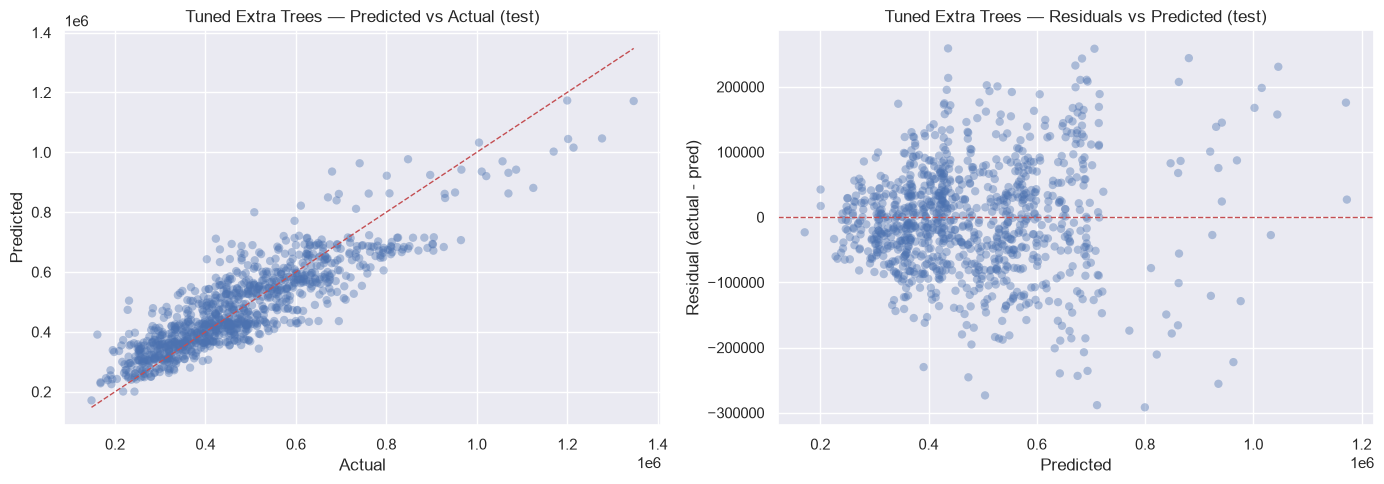

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,Elasti

In [53]:
model_et1=best_model_et
result_et1, decile_df_et1=store_results_regression("Tuned Extra Trees", X_train, y_train, X_test, y_test, model_et1, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result_et1], ignore_index=True)
Model_Comparison

## AdaBoost (Adaptive Boosting)

In [54]:
X_train=X_train_ada.copy()
y_train =y_train_ada.copy()
X_test=X_test_ada.copy()
y_test = y_test_ada.copy()

Train RMSE: 114476.5762   Test RMSE: 111676.0433
Train MAE:  91570.4950    Test MAE:  89337.6983
Train R^2:  0.5859    Test R^2:  0.5874


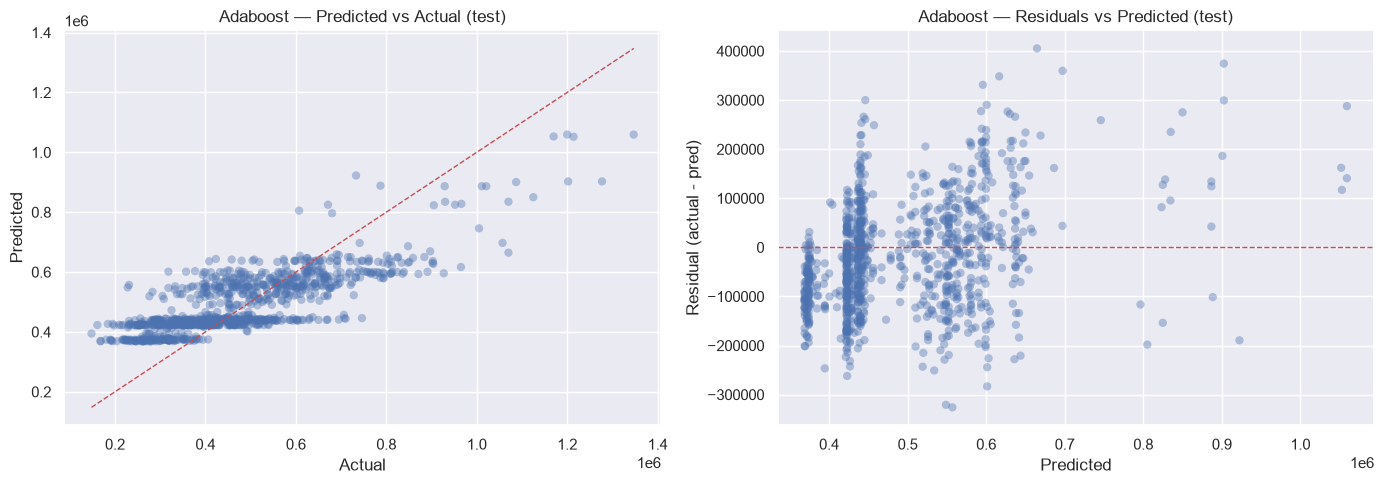

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,Elasti

In [55]:
base_est = DecisionTreeRegressor (max_depth =2,random_state=1234)
model_ADA1 = AdaBoostRegressor(base_est, n_estimators=500, random_state=1234, learning_rate=.05)
result_ADA1, decile_df_ADA1=store_results_regression("Adaboost", X_train, y_train, X_test, y_test, model_ADA1, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result_ADA1], ignore_index=True)
Model_Comparison

## Tuning

In [56]:
base_est = DecisionTreeRegressor (random_state=1234,max_depth=2)
ada_boost1 = AdaBoostRegressor(base_est, random_state=1234, learning_rate=.05)
#param_grid = {"base_estimator__max_depth" : [2, 5],"n_estimators": [200, 400, 600]}
param_grid = {"n_estimators": [200, 400, 600]}
# Bayesian Optimization
opt = BayesSearchCV(
    estimator=ada_boost1,
    search_spaces=param_grid,
    scoring='r2',  # R2
    cv=5,
    n_iter=30,
    random_state=1234,
    n_jobs=-1,
    return_train_score=True
)

opt.fit(X_train, y_train)

# ===== 2. PENALIZE BY GAP =====
results_df = pd.DataFrame(opt.cv_results_)
results_df['gap'] = results_df['mean_train_score'] - results_df['mean_test_score']

gap_penalty_weight = 0.5
results_df['penalized_score'] = results_df['mean_test_score'] - (gap_penalty_weight * results_df['gap'])

# ===== 3. GET BEST MODEL =====
best_idx = results_df['penalized_score'].idxmax()
best_params = results_df.loc[best_idx, 'params']

print("="*70)
print("BEST EXTRA TREES MODEL")
print("="*70)
print(f"Parameters: {best_params}")
print(f"CV Test R2:  {results_df.loc[best_idx, 'mean_test_score']:.4f}")
print(f"CV Train R2: {results_df.loc[best_idx, 'mean_train_score']:.4f}")
print(f"Gap:             {results_df.loc[best_idx, 'gap']:.4f}")
print(f"Penalized Score: {results_df.loc[best_idx, 'penalized_score']:.4f}")
print("="*70)

# ===== 4. TRAIN FINAL MODEL WITH BEST PARAMS =====
best_model_ada = ExtraTreesRegressor(
    **best_params,
    random_state=1234,
    n_jobs=-1
)
best_model_ada.fit(X_train, y_train)

BEST EXTRA TREES MODEL
Parameters: OrderedDict({'n_estimators': 600})
CV Test R2:  0.5766
CV Train R2: 0.5889
Gap:             0.0124
Penalized Score: 0.5704


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",600
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",1234
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features``

Train RMSE: 0.2981   Test RMSE: 64711.9467
Train MAE:  0.0067    Test MAE:  48259.5867
Train R^2:  1.0000    Test R^2:  0.8615


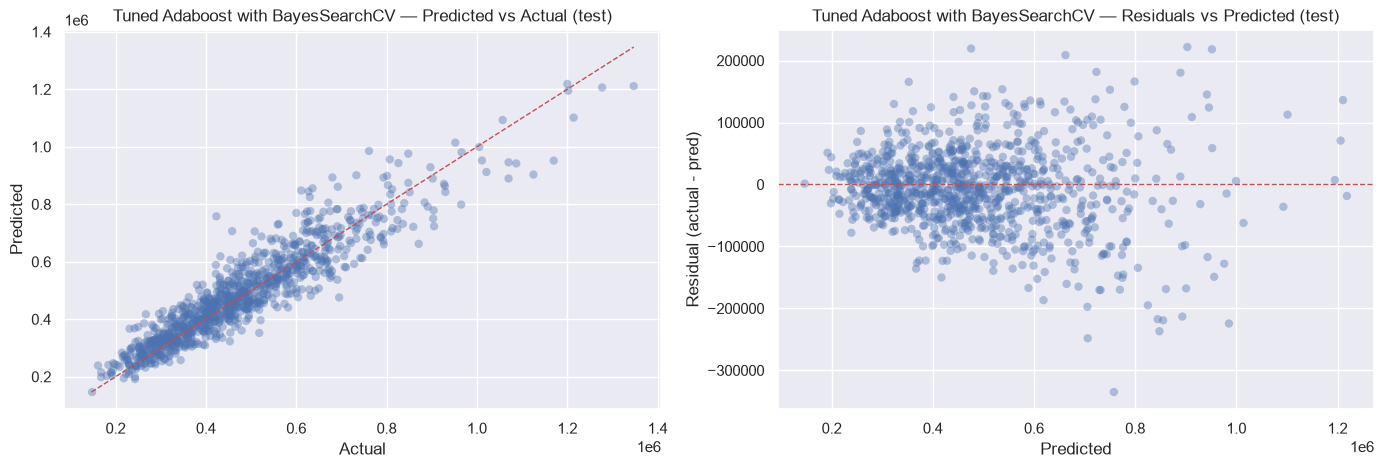

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,Elasti

In [57]:
model_ada2=best_model_ada

result_ADA2, decile_df_ADA2=store_results_regression("Tuned Adaboost with BayesSearchCV", X_train, y_train, X_test, y_test, model_ada2, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result_ADA2], ignore_index=True)
Model_Comparison

## Feature Importance

In [58]:
feature_importances = model_ada2.feature_importances_
features = X_train.columns
feature_importances_df = pd.DataFrame({'features': features, 'importance': feature_importances})
feature_importances_df.sort_values(by="importance", ascending=False).reset_index(drop=True)

,features,importance
0,living_area_sqft,0.220521
1,ProvLocation_PEast,0.174405
2,property_type_Triplex,0.141763
3,sale_year,0.088532
4,property_type_Single_Family,0.044492
...,...,...
128,sale_year_flag,0.000000
129,year_built_flag,0.000000
130,living_area_sqft_flag,0.000000
131,bedrooms_flag,0.000000


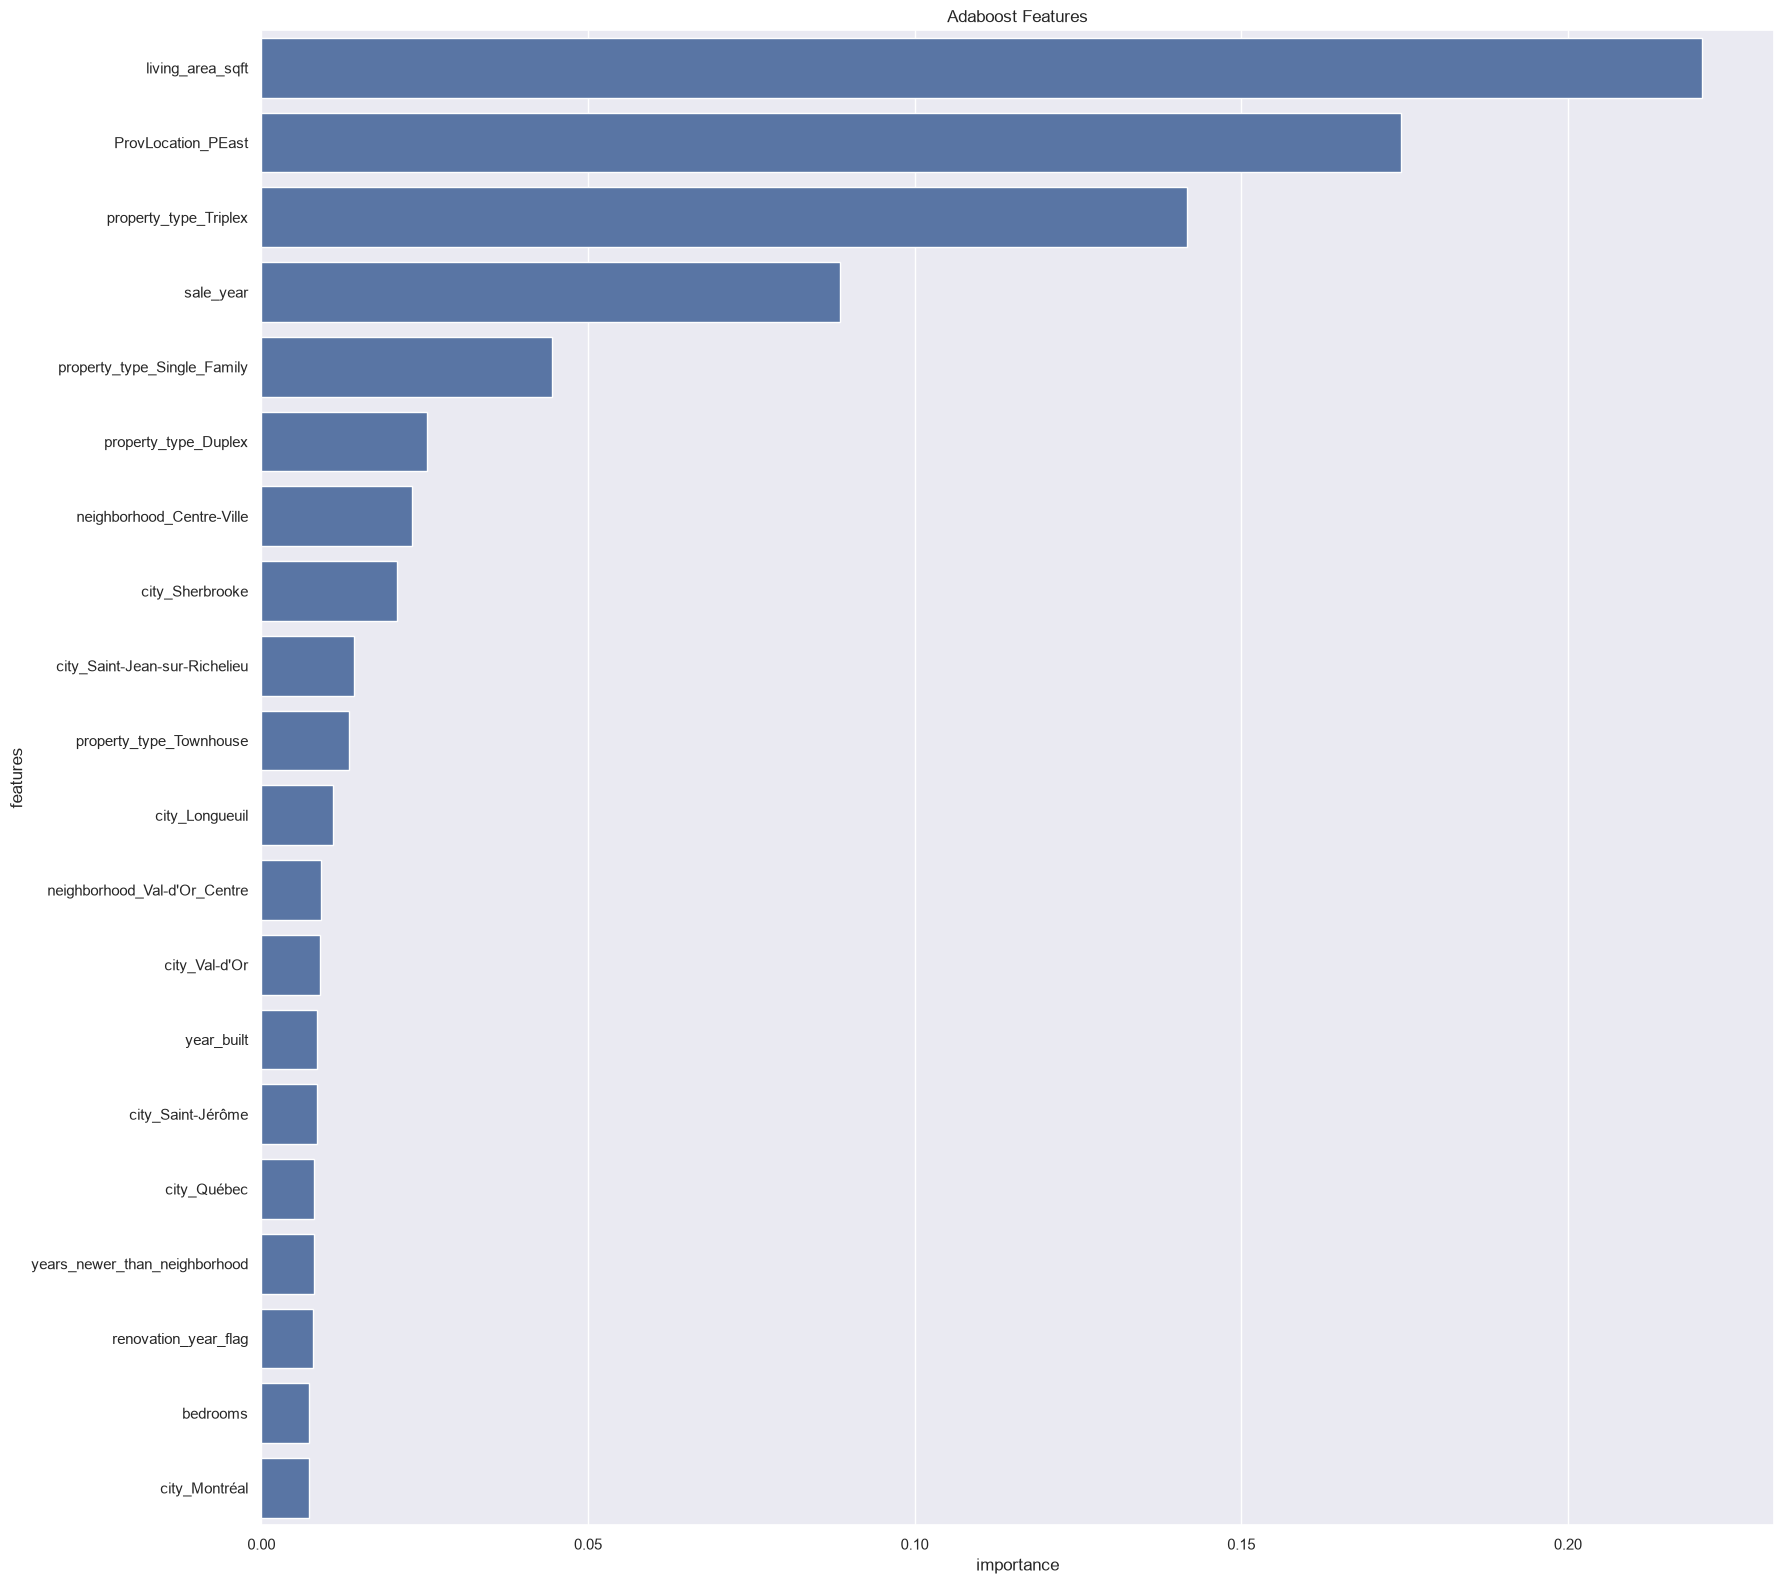

In [59]:
imp=feature_importances_df.sort_values(by="importance", ascending=False).head(20)
plt.figure(figsize=(18, 16))
sns.set(font_scale = 1)
sns.barplot(x="importance", y="features", data=imp.sort_values(by="importance", ascending=False))
plt.title('Adaboost Features')
plt.tight_layout()
plt.show()

## XGBOOST

In [60]:
X_train=X_train_gb.copy()
y_train =y_train_gb.copy()
X_test=X_test_gb.copy()
y_test = y_test_gb.copy()

In [61]:
X_train.dtypes

bedrooms                 int64
bathrooms                int64
living_area_sqft         int64
lot_size_sqft          float64
year_built               int64
                        ...   
ProvLocation_PEast     float64
ProvLocation_PNorth    float64
ProvLocation_PSouth    float64
ProvLocation_PWest     float64
ProvLocation_nan       float64
Length: 126, dtype: object

Train RMSE: 30592.6768   Test RMSE: 56285.1620
Train MAE:  23468.1582    Test MAE:  43125.4258
Train R^2:  0.9704    Test R^2:  0.8952


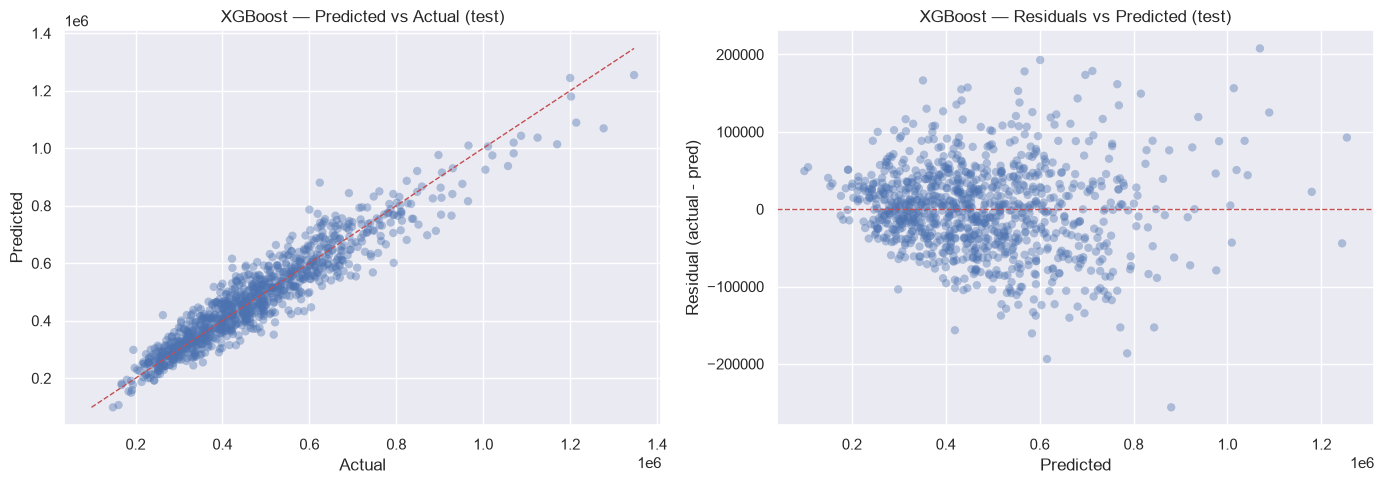

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,Elasti

In [62]:
model_XGB1=XGBRegressor(n_jobs=-1,random_state=1234,max_depth= 3,n_estimators= 500)
result_XGB1, decile_df_XGB1=store_results_regression("XGBoost", X_train, y_train, X_test, y_test, model_XGB1, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result_XGB1], ignore_index=True)
Model_Comparison

### Tuning 

Train RMSE: 76578.3650   Test RMSE: 83692.4631
Train MAE:  57783.8658    Test MAE:  64872.6900
Train R^2:  0.8147    Test R^2:  0.7683


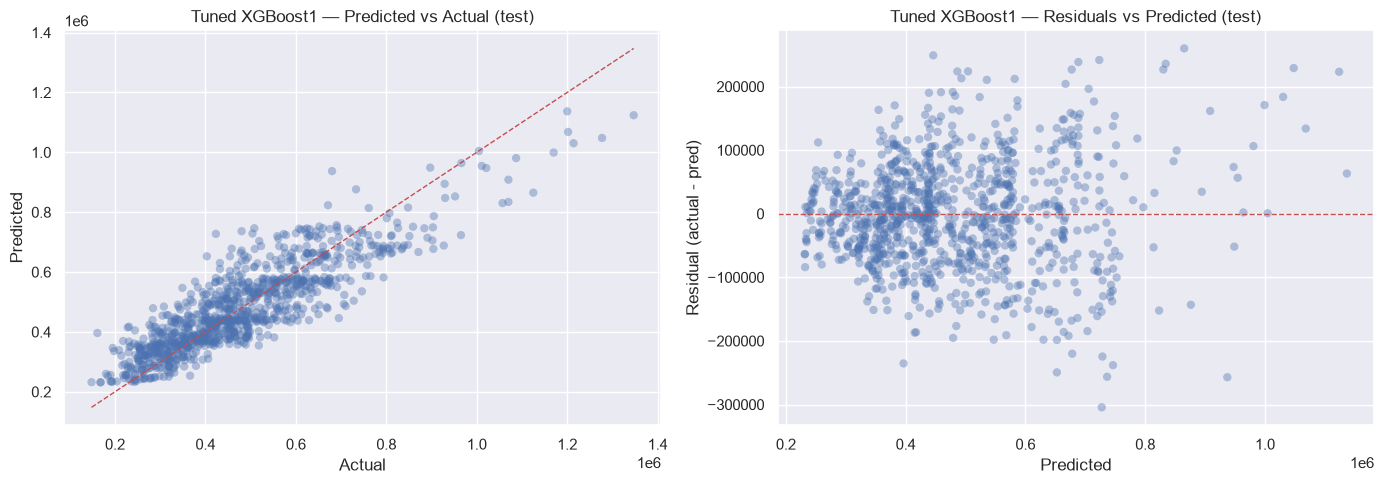

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,Elasti

In [63]:
model_XGB2=best_model 
result_XGB2, decile_df_XGB2=store_results_regression("Tuned XGBoost1", X_train, y_train, X_test, y_test, model_XGB2, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result_XGB2], ignore_index=True)
Model_Comparison

In [64]:
xgb=XGBRegressor(random_state=1234)

#param_grid={'loss':['ls', 'lad', 'huber'],'n_estimators':range(5,50,10),'max_depth':[3,4,5,6],
#            'min_samples_leaf':range(2,10,3),'max_features':['auto', 'sqrt', 'log2', None]}
param_grid={'n_estimators':[100,300,500],'max_depth':[3,4,5]
           }
opt = BayesSearchCV(
    estimator=xgb,
    search_spaces=param_grid,
    scoring='r2',
    cv=5,
    n_iter=30,
    random_state=1234,
    n_jobs=-1,
    return_train_score=True
)

opt.fit(X_train, y_train)

# ===== 2. PENALIZE BY GAP =====
results_df = pd.DataFrame(opt.cv_results_)
results_df['gap'] = results_df['mean_train_score'] - results_df['mean_test_score']

gap_penalty_weight = 0.5
results_df['penalized_score'] = results_df['mean_test_score'] - (gap_penalty_weight * results_df['gap'])

# ===== 3. GET BEST MODEL =====
best_idx = results_df['penalized_score'].idxmax()
best_params = results_df.loc[best_idx, 'params']

print("="*70)
print("BEST MODEL")
print("="*70)
print(f"Parameters: {best_params}")
print(f"CV Test R2:  {results_df.loc[best_idx, 'mean_test_score']:.4f}")
print(f"CV Train R2: {results_df.loc[best_idx, 'mean_train_score']:.4f}")
print(f"Gap:             {results_df.loc[best_idx, 'gap']:.4f}")
print(f"Penalized Score: {results_df.loc[best_idx, 'penalized_score']:.4f}")
print("="*70)

# ===== 4. TRAIN FINAL MODEL WITH BEST PARAMS =====
best_model = XGBRegressor(
    **best_params,
    n_jobs=-1,
    random_state=1234
)
best_model.fit(X_train, y_train)

BEST MODEL
Parameters: OrderedDict({'max_depth': 3, 'n_estimators': 100})
CV Test R2:  0.8880
CV Train R2: 0.9277
Gap:             0.0398
Penalized Score: 0.8681


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## Feature Importance

In [65]:
feature_importances = model_XGB2.feature_importances_
features = X_train.columns
feature_importances_df = pd.DataFrame({'features': features, 'importance': feature_importances})
feature_importances_df.sort_values(by="importance", ascending=False).reset_index(drop=True)


,features,importance
0,living_area_sqft,0.386096
1,ProvLocation_PEast,0.224432
2,sale_year,0.108965
3,property_type_Triplex,0.041470
4,neighborhood_Centre-Ville,0.036929
...,...,...
121,city_Candiac,0.000000
122,neighborhood_Outremont,0.000000
123,neighborhood_LaSalle,0.000000
124,neighborhood_Verdun,0.000000


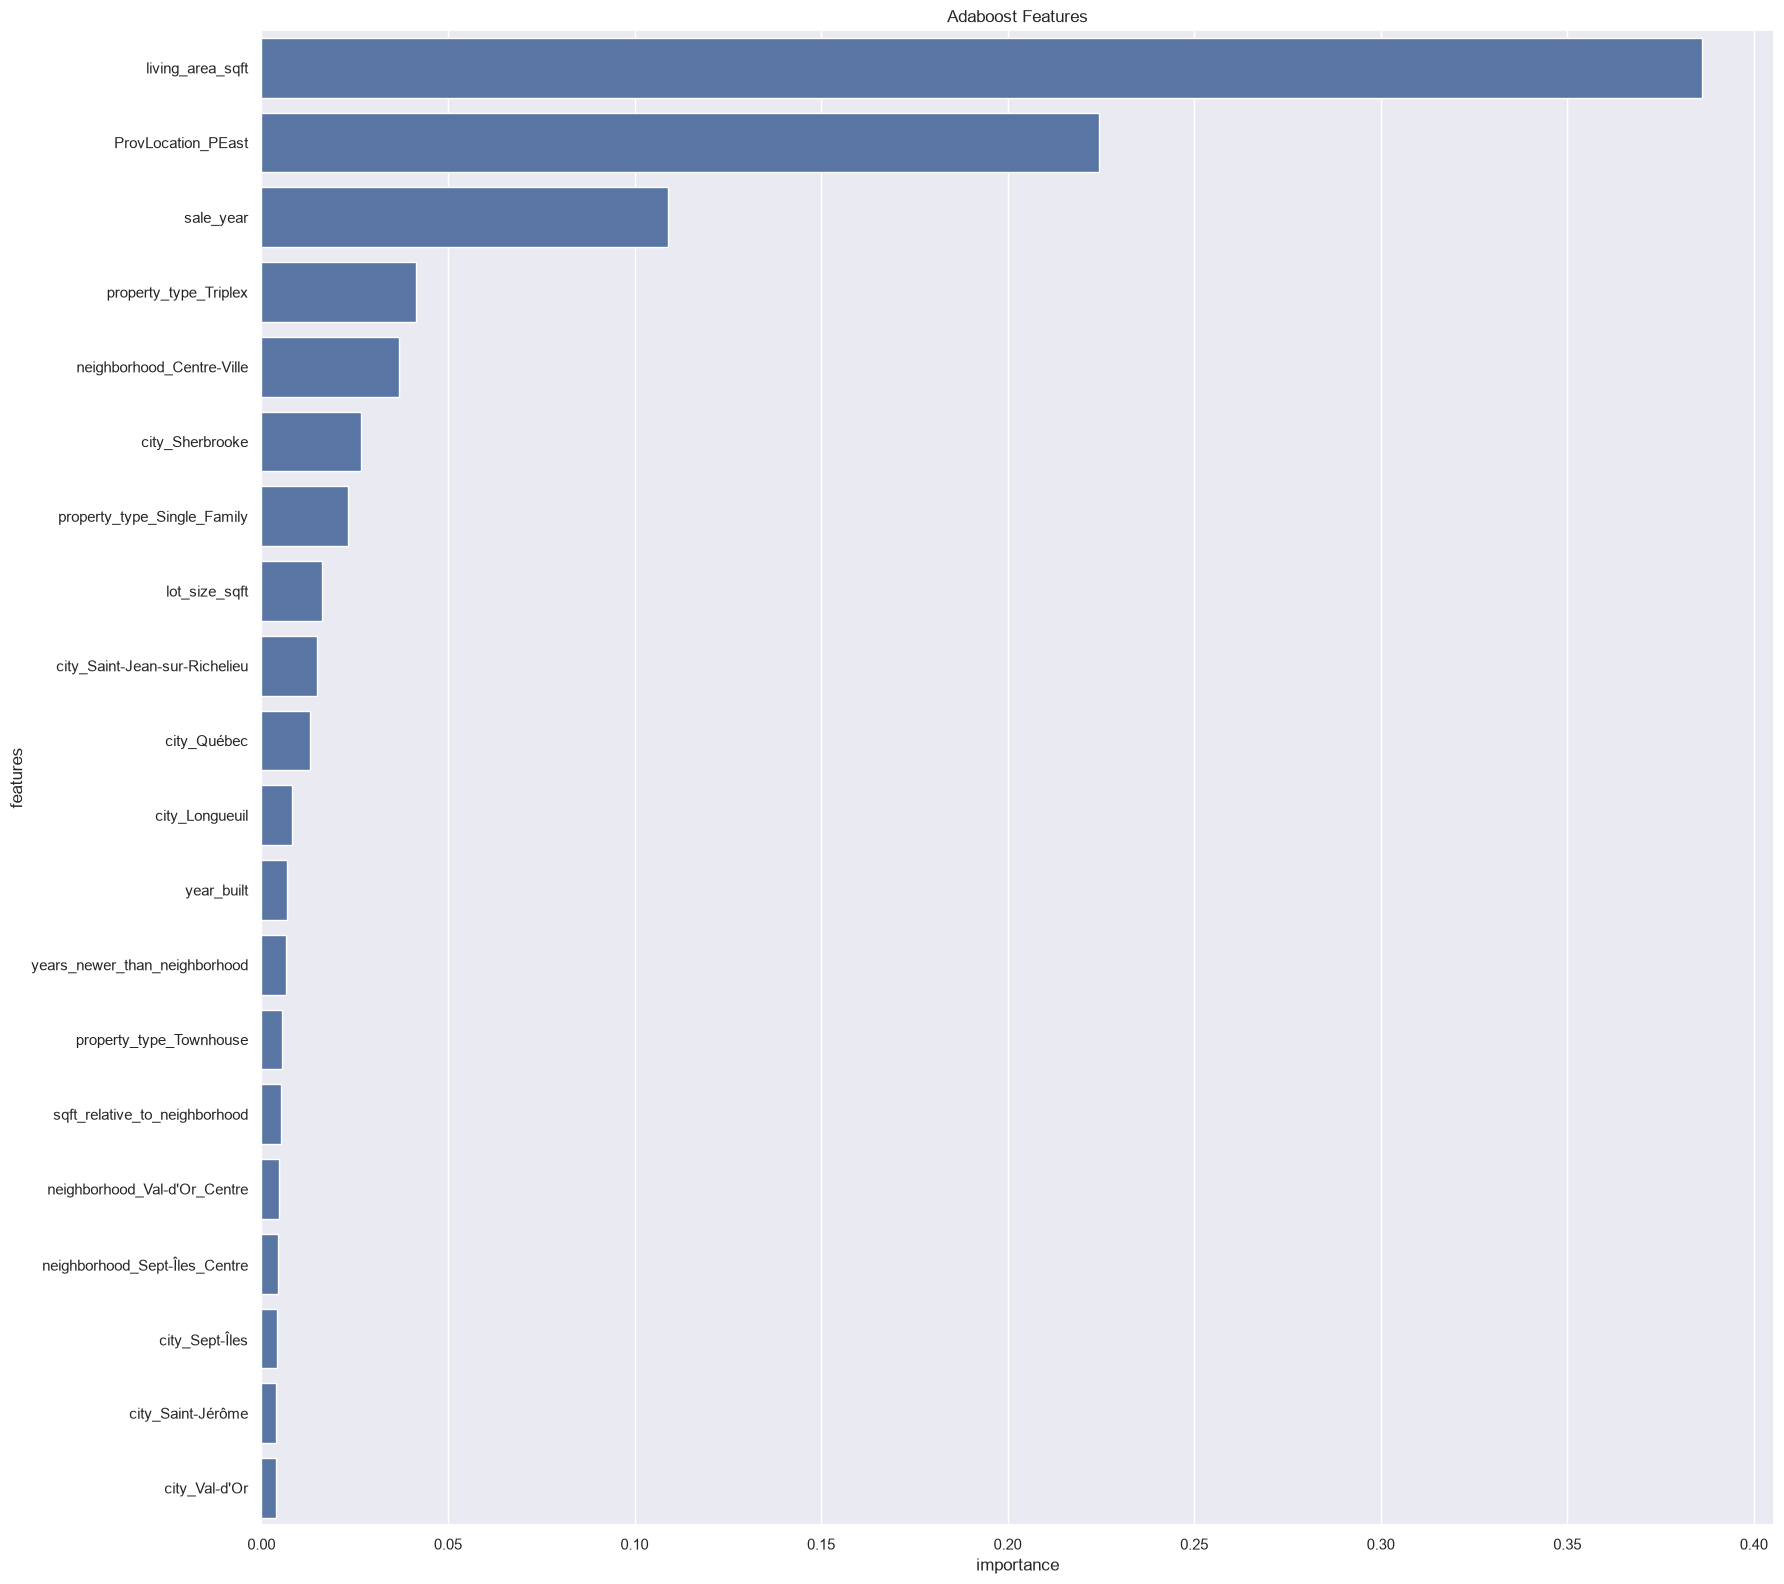

In [67]:

imp=feature_importances_df.sort_values(by="importance", ascending=False).head(20)
plt.figure(figsize=(18, 16))
sns.set(font_scale = 1)
sns.barplot(x="importance", y="features", data=imp.sort_values(by="importance", ascending=False))
plt.title('Adaboost Features')
plt.tight_layout()
plt.show()

## # Save the Model Comparison metrics (R², MSE, RMSE, etc.)

In [68]:
Model_Comparison.to_csv(r"C:\Users\Owner\Downloads\Data Science Metro\DSPP\Projects\Model_Comparison2_Regression.csv")
print("Regression model comparison saved successfully!")

Regression model comparison saved successfully!


## LightGBM

Train RMSE: 43014.3130   Test RMSE: 54854.3926
Train MAE:  33134.7453    Test MAE:  42080.7479
Train R^2:  0.9415    Test R^2:  0.9004


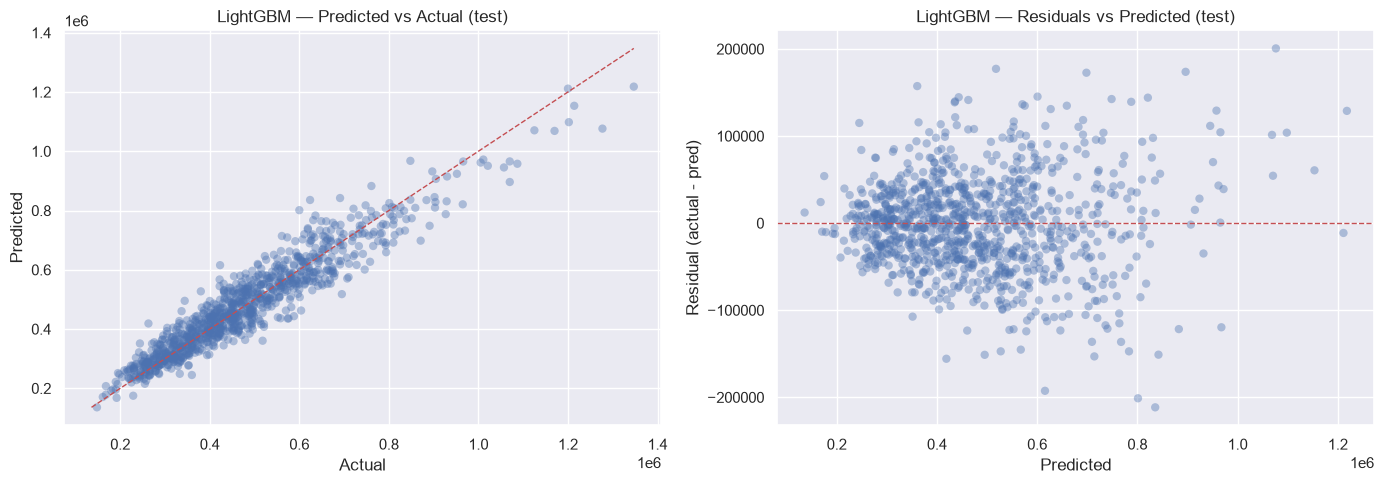

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,Elasti

In [69]:
model_lgb1 = LGBMRegressor(
    
    n_estimators=100,      # Number of trees
    max_depth=10,          # Max tree depth
    learning_rate=0.1,     # How fast it learns
    random_state=1234,
    n_jobs=-1
)

result_lgb1, decile_df_lgb1=store_results_regression("LightGBM", X_train, y_train, X_test, y_test, model_lgb1, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result_lgb1], ignore_index=True)
Model_Comparison

In [70]:
"""param_grid = {

    # Tree structure
    'n_estimators': [100,200, 400, 800],
    'max_depth': [3, 5, 8,10, -1],   # -1 = no limit
    'num_leaves': [15, 31, 63, 127],

    #  Learning control
    'learning_rate': [0.01, 0.05, 0.1],

    #  Regularization
    'min_data_in_leaf': [20, 50, 100],
    'lambda_l2': [0, 1, 5],
    'lambda_l1': [0, 0.5, 1],

    # Sampling
    'feature_fraction': [0.7, 0.8, 0.9],
    'bagging_fraction': [0.7, 0.8, 0.9],
    'bagging_freq': [5]
}"""
param_grid = {

    # Tree structure
    'n_estimators': [100,200],
    'max_depth': [5, 8,10], 
    'num_leaves': [15, 31, 63, 127],

    #  Learning control
    'learning_rate': [0.01, 0.1],
}

reg_LGBM = GridSearchCV(
    LGBMRegressor(random_state=1234,n_job=-1),
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

reg_LGBM.fit(X_train, y_train)

reg_LGBM.best_params_

{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'num_leaves': 15}

Train RMSE: 46066.9756   Test RMSE: 53362.4575
Train MAE:  35149.3468    Test MAE:  40808.6248
Train R^2:  0.9329    Test R^2:  0.9058


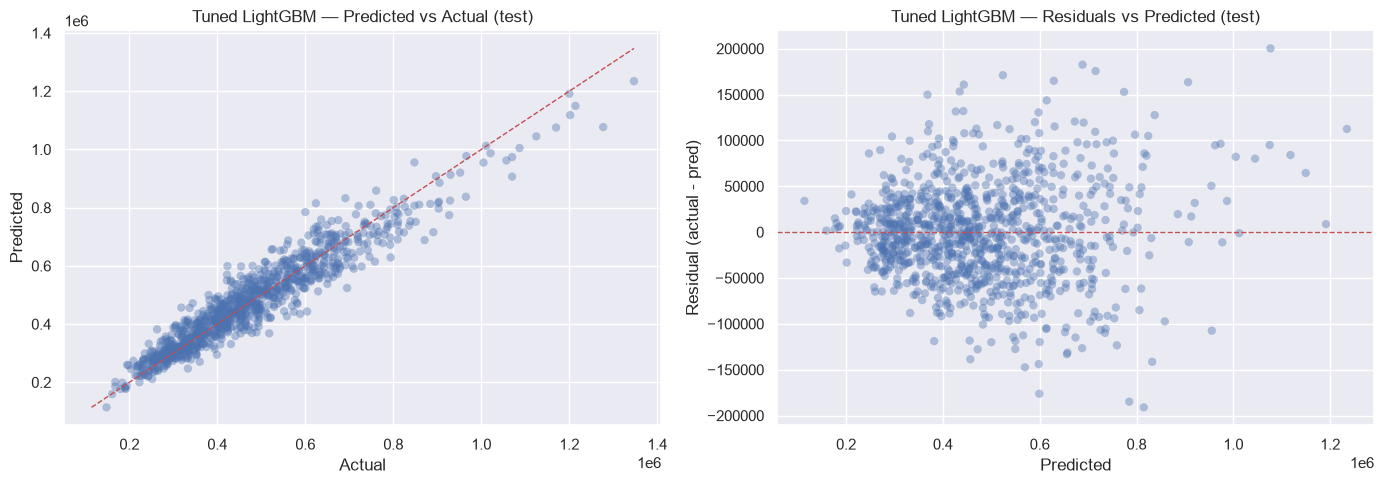

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,845631.3412,129557.4874,99894.3634,889000.0,836572.3498,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,845628.8044,132447.3475,103060.8738,891900.0,836614.6962,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,845573.5018,129577.3050,99905.8827,889000.0,836520.4699,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,785550.9872,169925.7500,133912.9375,881900.0,779374.7236,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.4066,Elasti

In [71]:
model_lgb2=reg_LGBM.best_estimator_
result_lgb2, decile_df_lgb3=store_results_regression("Tuned LightGBM", X_train, y_train, X_test, y_test, model_lgb2, 5,
                             norm="N/A", alpha="N/A")
Model_Comparison=pd.concat([Model_Comparison, result_lgb2], ignore_index=True)
Model_Comparison

In [73]:
Model_Comparison.to_csv(fr"{outputfolder}\Model_Comparison2_Regression.csv")
print("Regression model comparison saved successfully!")

Regression model comparison saved successfully!


In [74]:
#Feature Importance
feature_importances = model_lgb2.feature_importances_
features = X_train.columns
feature_importances_df = pd.DataFrame({'features': features, 'importance': feature_importances})
feature_importances_df.sort_values(by="importance", ascending=False).reset_index(drop=True)


,features,importance
0,living_area_sqft,456
1,sale_year,170
2,year_built,166
3,lot_size_sqft,128
4,sqft_relative_to_neighborhood,112
...,...,...
121,neighborhood_Secteur_A,0
122,neighborhood_Trois-Rivières-Ouest,0
123,neighborhood_Villeray,0
124,neighborhood_Vimont,0


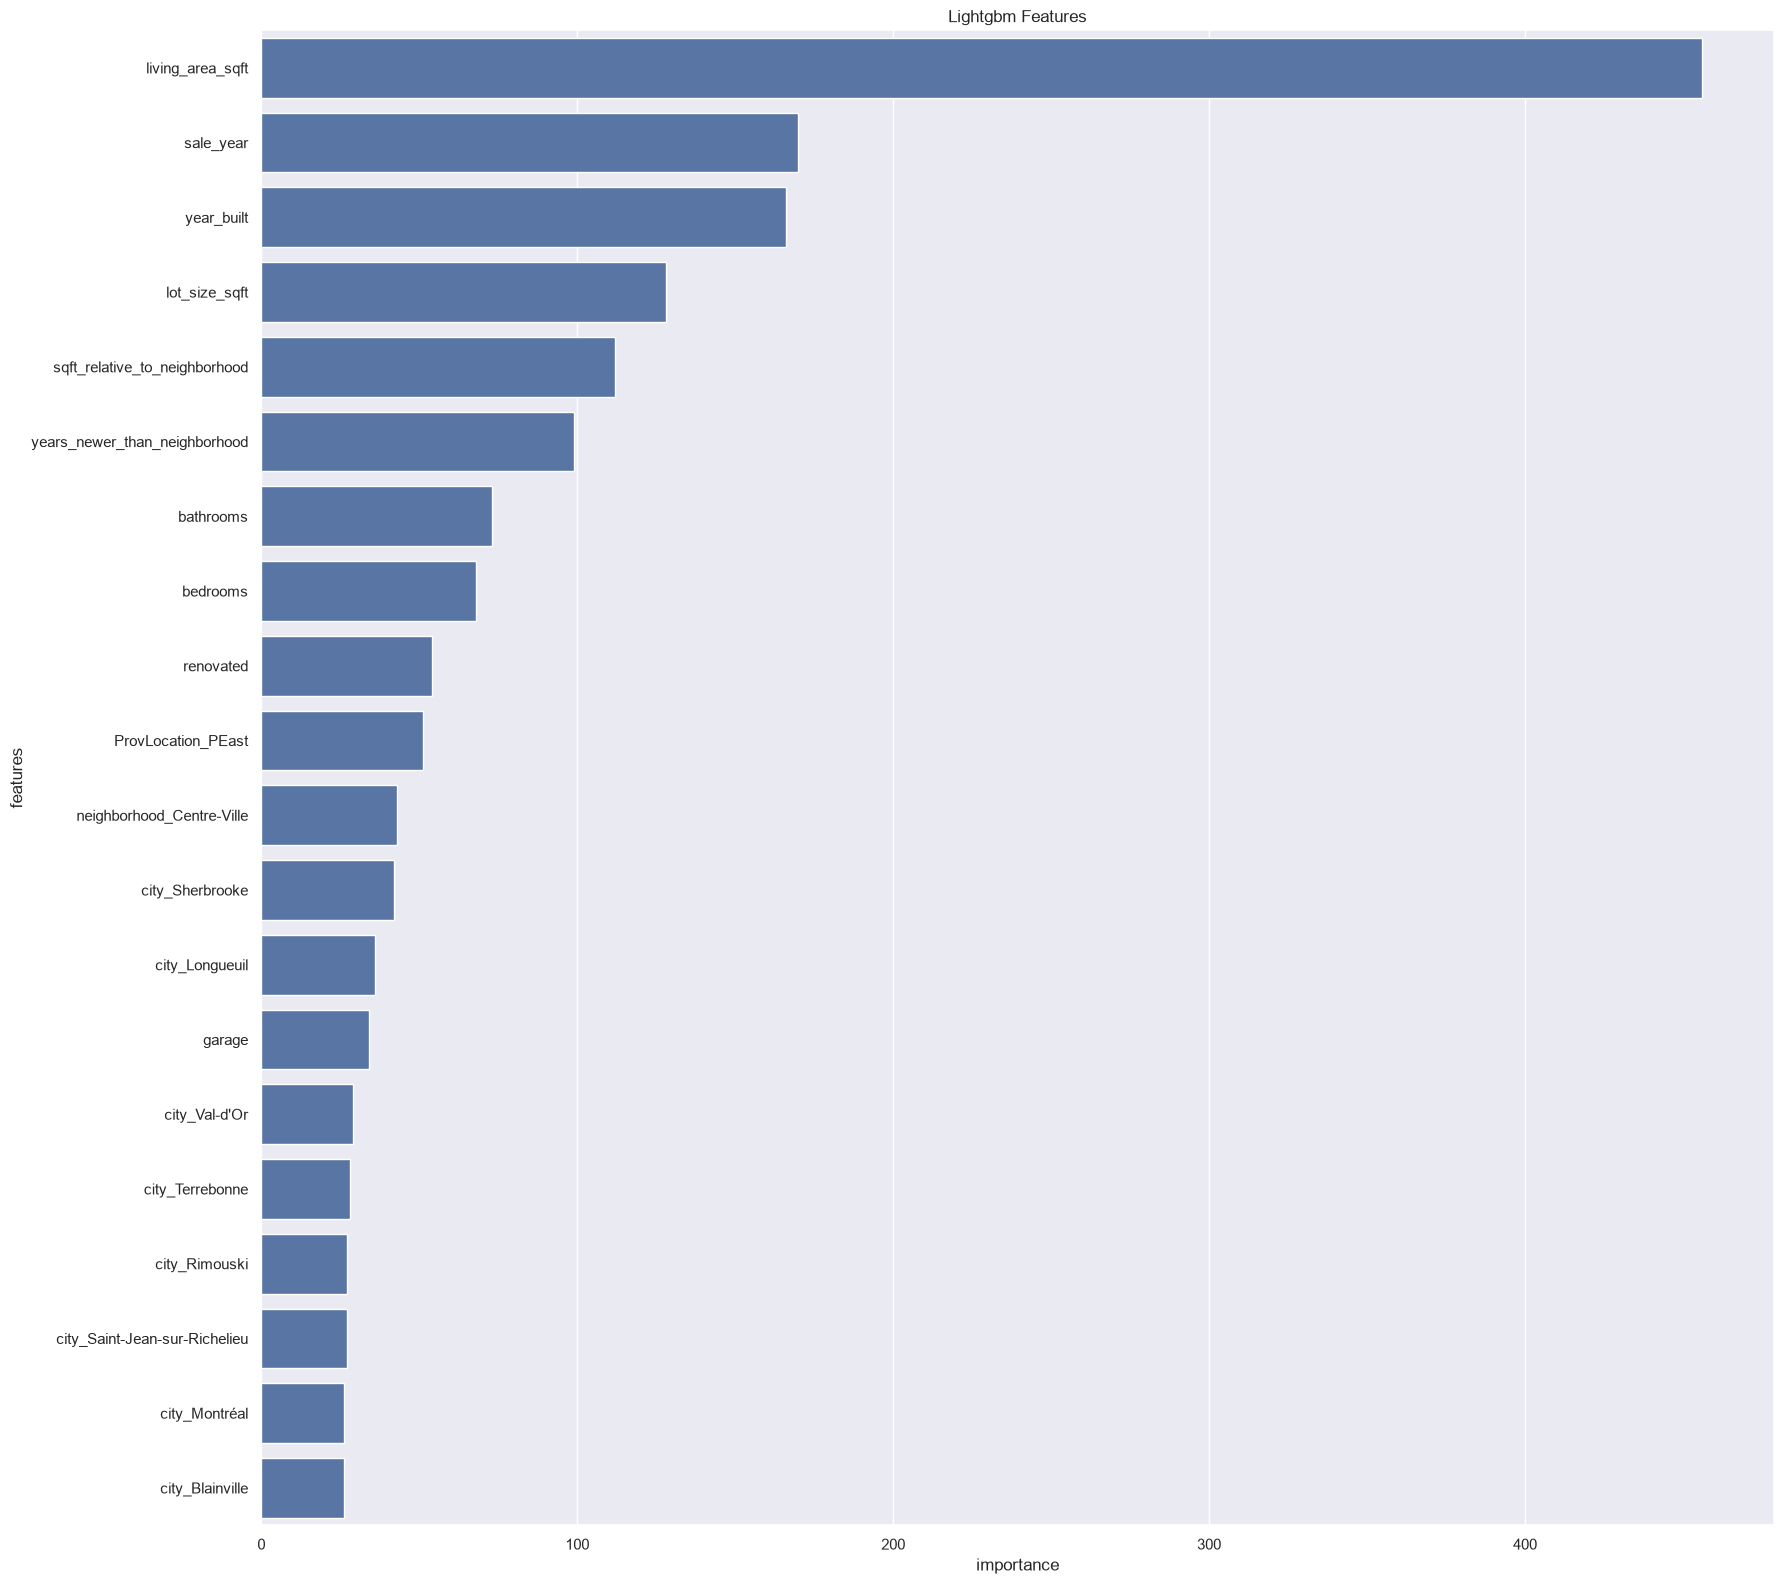

In [75]:
imp=feature_importances_df.sort_values(by="importance", ascending=False).head(20)
plt.figure(figsize=(18, 16))
sns.set(font_scale = 1)
sns.barplot(x="importance", y="features", data=imp.sort_values(by="importance", ascending=False))
plt.title('Lightgbm Features')
plt.tight_layout()
plt.show()

## Neural Network

Train RMSE: 290752.2545   Test RMSE: 287655.1964
Train MAE:  235770.5000    Test MAE:  233038.0000
Train R^2:  -1.6714    Test R^2:  -1.7377


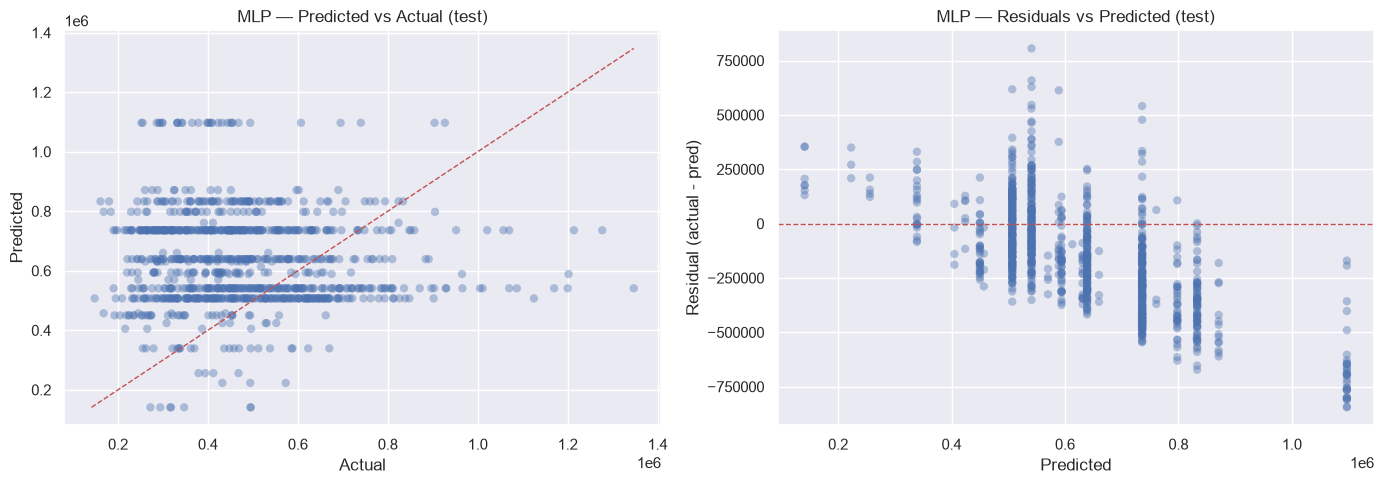

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,8.456313e+05,129557.4874,99894.3634,889000.0,8.365723e+05,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,8.456288e+05,132447.3475,103060.8738,891900.0,8.366147e+05,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,8.455735e+05,129577.3050,99905.8827,889000.0,8.365205e+05,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,7.855510e+05,169925.7500,133912.9375,881900.0,7.793747e+05,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.406

In [76]:
#step1 : import classifier
from sklearn.neural_network import MLPClassifier
#step 2: create an intanse

MLP = MLPClassifier(hidden_layer_sizes=(10,12), #I designed 2 hidden layers for HL1 I put 10 Nerouns and HL2 I put 12 Neorons 
                    activation='relu', # activation = 'identity', 'logistic', 'relu', 'tanh'
                    learning_rate_init=0.01,# normaly best learning rate between .001 and 0.1
                    learning_rate='invscaling',# I learning rate will be started from 0.01 and decreases gradually
                    solver='sgd',#earning_rate='invscaling' works only with solver='sgd'
                    max_iter=50,
                    #momentum=0.5,
                    #batch_size=32,      # Mini-batch size 
                    #batch_size=X_train_scaled.shape[0] #Full Batch Gradient Descent
                   )


result_nn, decile_df_nn=store_results_regression("MLP",X_train_scaled, y_train_scaled,X_test_scaled,
                                                 y_test_scaled, MLP, 5,"NA", "NA")
Model_Comparison=pd.concat([Model_Comparison, result_nn], ignore_index=True)
Model_Comparison

## Keras Sequential

In [77]:
# Define the Neural Network Architecture for Regression
model_nn_reg = keras.Sequential([
    # Input layer and first hidden layer
    keras.layers.Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    keras.layers.Dropout(0.3),
    
    # Second hidden layer
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.3),
    
    # Output layer: 1 node with NO activation (linear) for continuous values
    keras.layers.Dense(1) 
])

# Compile using regression-specific loss and metrics
model_nn_reg.compile(
    optimizer='adam',
    loss='mean_squared_error',      # used for regression
    metrics=['mean_absolute_error']  # used for regression
)

# Fit the model
model_nn_reg.fit(
    X_train_scaled, 
    y_train,                        # Use raw target variables (not scaled to 0/1)
    epochs=50, 
    batch_size=32, 
    validation_split=0.2, 
    verbose=0
)

# 4. Get continuous predictions
y_pred_nn_reg = model_nn_reg.predict(X_test_scaled, verbose=0).flatten()

# Note: Thresholding (find_optimal_threshold_and_evaluate) is unique to classification.
# For regression, you directly evaluate continuous metrics (e.g., R², RMSE, MAE).
metrics_nn_reg = evaluate_regression_model(y_test, y_pred_nn_reg, "Neural Network Regression")
print_results_table([metrics_nn_reg], "NEURAL NETWORK REGRESSION")


NEURAL NETWORK REGRESSION
Model                     MAE          RMSE         R²           MAPE (%)    
----------------------------------------------------------------------------------------------------
Neural Network Regression 97457.7422   127919.3438  0.4586       21.24       



store_results_regression() function is designed for scikit-learn models because it expects methods like:
```python
model.fit()
model.predict_proba()
```

A Keras Sequential model has:
```python
model.fit()
model.predict()
```
but does not have:
```python
model.predict_proba()
```
Therefore, our current store_results() will fail at:
```python
y_prob = model.predict_proba(X_test)[:,1]
```

`So one option is Wrap the Keras model to mimic scikit-learn`


In [78]:
from sklearn.base import BaseEstimator, RegressorMixin
import numpy as np
from tensorflow import keras

class KerasRegressorWrapper(BaseEstimator, RegressorMixin):
    def __init__(self, input_dim, epochs=50, batch_size=32, verbose=0):
        self.input_dim = input_dim
        self.epochs = epochs
        self.batch_size = batch_size
        self.verbose = verbose

    def build_model(self):
        model = keras.Sequential([
            keras.layers.Dense(64, activation='relu', #a hidden layer of 64 neurons
                        input_shape=(self.input_dim,)),#relu activation function helped learn complex, non-linear relationships.
            keras.layers.Dropout(0.3), #randomly turned off 30% of the neurons during training to 
                                        #prevent the network from just memorizing the data (overfitting)
            keras.layers.Dense(32, activation='relu'),
            keras.layers.Dropout(0.3),
            # Output layer: 1 node with no activation (linear) for continuous outputs
            keras.layers.Dense(1)
        ])

        model.compile(
            optimizer='adam',
            loss='mean_squared_error',       # for regression
            metrics=['mean_absolute_error']   # for regression
        )

        return model

    def fit(self, X, y):
        # build_model() is called here so the structure resets if re-fitted
        self.model_ = self.build_model()

        self.model_.fit(
            X,
            np.asarray(y).ravel(),
            epochs=self.epochs,
            batch_size=self.batch_size,
            validation_split=0.2,
            verbose=self.verbose
        )

        return self

    def predict(self, X):
        # Directly return the continuous predicted values
        return self.model_.predict(X, verbose=0).ravel()

Train RMSE: 127787.9243   Test RMSE: 128719.9354
Train MAE:  98751.9219    Test MAE:  98020.9062
Train R^2:  0.4840    Test R^2:  0.4518


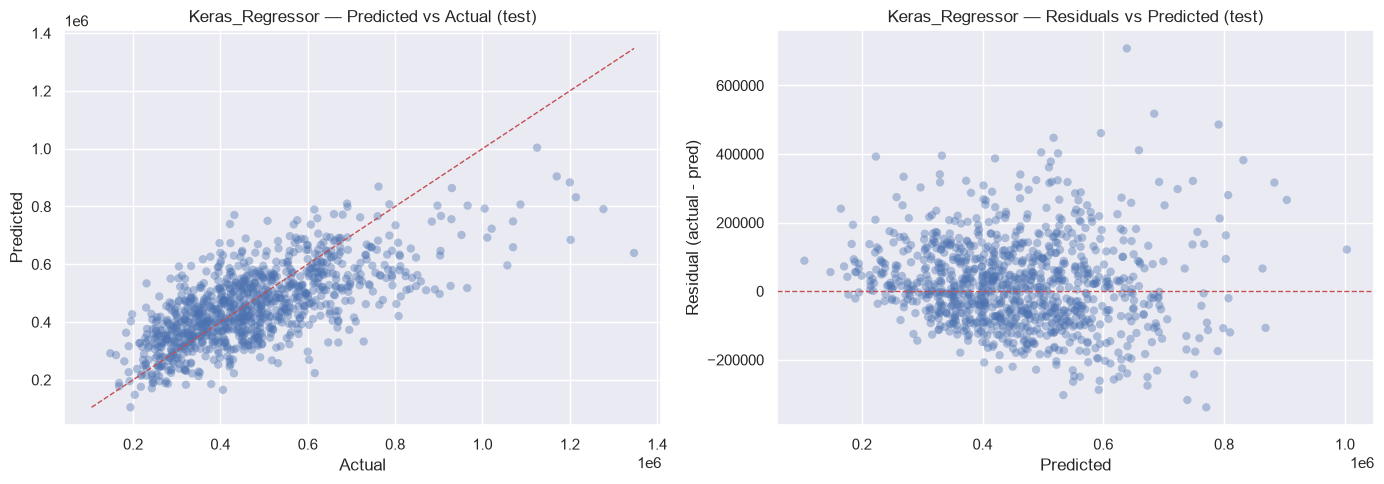

In [79]:
# Instantiate the Regression Wrapper
keras_reg_wrapper = KerasRegressorWrapper(
    input_dim=X_train_scaled.shape[1],
    epochs=50,
    batch_size=32,
    verbose=0
)

# Store results (adjusted parameters for regression metrics)
result_df_keras, decile_df_keras = store_results_regression(
    "Keras_Regressor",
    X_train_scaled,
    y_train,         # Continuous target variable (not binary scaled)
    X_test_scaled,
    y_test,          # Continuous target variable (not binary scaled)
    keras_reg_wrapper,
    5      # Assuming the integer parameter represents Cross-Validation folds

)

In [80]:
Model_Comparison=pd.concat([Model_Comparison, result_df_keras], ignore_index=True)
Model_Comparison

,Model,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2,Train_Adj_R2,Test_Adj_R2,Train_MedianAE,Test_MedianAE,Train_MaxError,Test_MaxError,Train_ExplVar,Test_ExplVar,Train_MAPE(%),Test_MAPE(%),CrossVal_Mean(R2),CrossVal_Std(R2),CrossVal_Mean(RMSE),CrossVal_Std(RMSE),CrossVal_Mean(MAE),CrossVal_Std(MAE),CrossVal_Mean(MAPE%),CrossVal_Std(MAPE%),CrossVal1(R2),CrossVal2(R2),CrossVal3(R2),CrossVal4(R2),CrossVal5(R2),CrossVal1(RMSE),CrossVal2(RMSE),CrossVal3(RMSE),CrossVal4(RMSE),CrossVal5(RMSE),CrossVal1(MAE),CrossVal2(MAE),CrossVal3(MAE),CrossVal4(MAE),CrossVal5(MAE),Train_Within_pm5pct,Test_Within_pm5pct,Train_Within_pm10pct,Test_Within_pm10pct,Train_Within_pm20pct,Test_Within_pm20pct,Train_RMSE@top1%,Train_MAE@top1%,Train_MeanActual@top1%,Train_MeanPred@top1%,Test_RMSE@top1%,Test_MAE@top1%,Test_MeanActual@top1%,Test_MeanPred@top1%,Train_RMSE@top5%,Train_MAE@top5%,Train_MeanActual@top5%,Train_MeanPred@top5%,Test_RMSE@top5%,Test_MAE@top5%,Test_MeanActual@top5%,Test_MeanPred@top5%,Train_RMSE@top10%,Train_MAE@top10%,Train_MeanActual@top10%,Train_MeanPred@top10%,Test_RMSE@top10%,Test_MAE@top10%,Test_MeanActual@top10%,Test_MeanPred@top10%,Regularization,alpha
0,Linear Regression,63930.9840,63479.4701,48330.2883,48648.0126,0.8708,0.8667,0.8664,0.8462,38672.8893,39850.3878,450408.7420,367148.2516,0.8708,0.8667,10.9670,11.0100,0.8630,0.0086,65692.2390,903.6695,49694.0167,516.1290,11.3000,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67471.3054,65219.4290,65194.6403,65532.7556,65043.0648,50613.0411,49092.5463,49484.3156,49834.7475,49445.4332,0.3035,0.290,0.5760,0.560,0.8625,0.864,186483.0031,149110.7007,1110675.0,9.812034e+05,198511.0211,172624.8666,1136500.0,9.642632e+05,123804.4464,93394.2700,886665.0,8.456313e+05,129557.4874,99894.3634,889000.0,8.365723e+05,108135.0067,81586.2445,816070.0,781357.5378,113750.8948,89398.3890,810420.0,778939.5032,N/A,N/A
1,Lasso_Linear Regression,63930.9845,63617.0919,48330.0709,48754.5130,0.8708,0.8661,0.8664,0.8455,38671.2843,40495.9704,450401.5518,369142.0202,0.8708,0.8662,10.9669,11.0388,0.8630,0.0086,65691.5229,903.8360,49693.2140,516.1749,11.2997,0.1968,0.8589,0.8523,0.8689,0.8764,0.8585,67470.8534,65218.6864,65193.5523,65532.3904,65042.1321,50612.3097,49091.7807,49483.2610,49834.0937,49444.6249,0.3035,0.293,0.5760,0.552,0.8625,0.862,186485.5704,149114.3284,1110675.0,9.812000e+05,198781.4848,172407.9569,1136500.0,9.645547e+05,123805.2395,93395.3697,886665.0,8.456288e+05,132447.3475,103060.8738,891900.0,8.366147e+05,108135.6140,81586.9264,816070.0,781355.8034,114005.5020,89496.4570,809850.0,778915.8852,L1,0.1
2,Ridge_Linear Regression,63931.0309,63475.2908,48326.0166,48639.0784,0.8708,0.8667,0.8664,0.8462,38667.7694,39750.7975,450477.8148,367191.3976,0.8708,0.8668,10.9644,11.0066,0.8630,0.0086,65688.1892,902.7578,49685.2534,513.4909,11.2959,0.1956,0.8589,0.8523,0.8689,0.8764,0.8586,67464.2321,65215.4969,65188.2686,65535.8945,65037.0536,50599.4722,49089.9145,49473.0860,49828.6599,49435.1343,0.3040,0.292,0.5760,0.562,0.8625,0.863,186533.2521,149165.5959,1110675.0,9.811305e+05,198559.8065,172673.2391,1136500.0,9.642008e+05,123828.6155,93412.9327,886665.0,8.455735e+05,129577.3050,99905.8827,889000.0,8.365205e+05,108154.0531,81601.2878,816070.0,781306.9174,113763.6582,89404.1767,810420.0,778895.5343,L2,0.1
3,ElasticNet_Linear Regression,79945.7480,76623.9218,58792.6170,57378.0161,0.7980,0.8057,0.7911,0.7759,44708.5212,44346.6696,539317.1323,454534.5584,0.7980,0.8058,13.3647,12.9103,0.7936,0.0045,80745.7732,2819.9502,59405.0150,1649.8847,13.5113,0.4938,0.7967,0.7877,0.7979,0.7885,0.7972,80993.8438,78184.7016,80945.6734,85730.8991,77873.7480,58930.9986,58828.4218,58648.2858,62637.5865,57979.7821,0.2800,0.253,0.4930,0.490,0.8047,0.808,262726.2006,223921.6441,1111475.0,8.942427e+05,290978.5836,269553.3577,1158500.0,8.889466e+05,160347.6429,121848.2213,878285.0,7.855510e+05,169925.7500,133912.9375,881900.0,7.793747e+05,140858.0459,108311.9463,811085.0,730117.4935,143088.2600,111005.5235,808360.0,729720.406

In [81]:
Model_Comparison.to_csv(fr"{outputfolder}\Model_Comparison2_Regression.csv")

print("Regression model comparison saved successfully!")

Regression model comparison saved successfully!


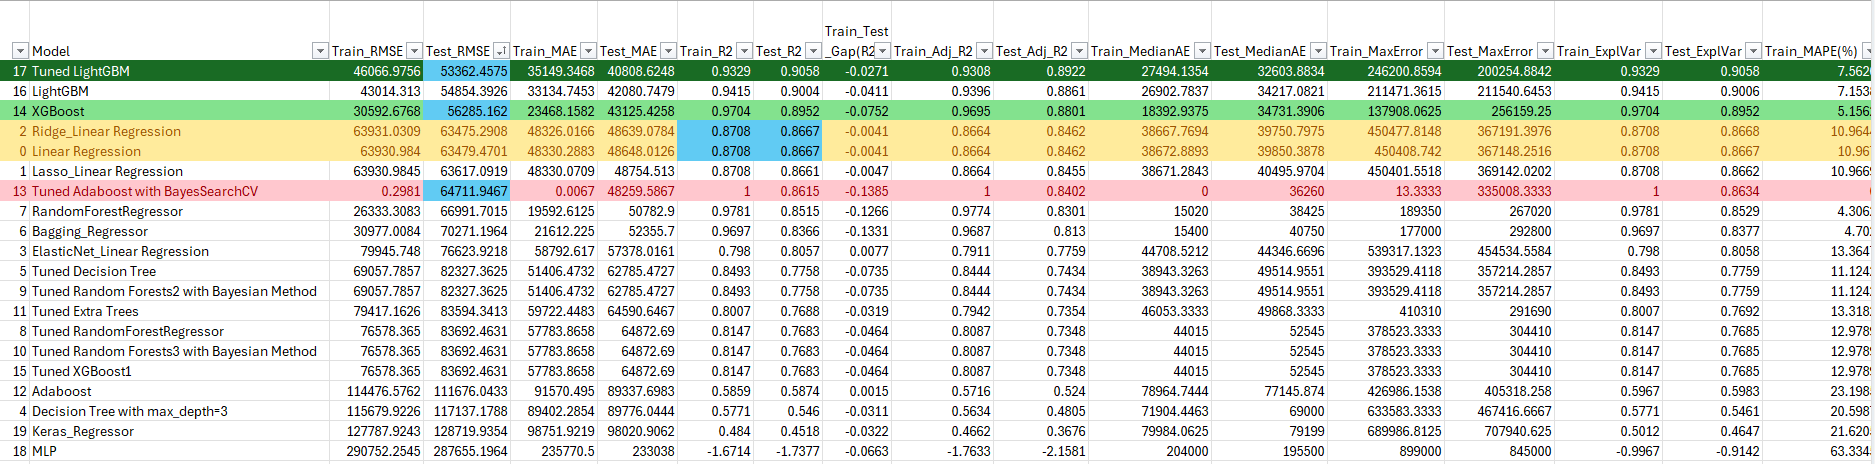

# Champion–Challenger Model Selection

## Objective
The objective of this analysis is to identify the most suitable Champion and Challenger models based on their predictive performance, generalization ability, and stability across cross-validation folds. Given the class imbalance in the dataset, particular emphasis was placed on **PR AUC**, **ROC AUC**, and model robustness.

---

## Champion Model: Tuned LightGBM

### Key Performance Metrics

| Metric | Value |
|----------|---------|
| Test R2 | 0.9058| Highest Overall
| Test RMSE | 53362.4575 |
| Train-Test Gap (R2) | -0.0271
| CV Mean R2 | 0.8846 | Most stable acorss folds


### Rationale

The Tuned LightGBM model was selected as the **Champion** because it provides the best overall balance between predictive performance and generalization:

- Achieved one of the highest **Test R2** values.

- Demonstrated a relatively small train-test performance gap, indicating limited overfitting.
- Delivered strong and consistent cross-validation results.
- Achieved the most stable cross-validation Mean R2 score among the leading candidates.

Overall, Tuned LightGBM offers the strongest combination of discrimination power, stability, and generalization performance.

---

## Challenger Model:  XGBoost

### Key Performance Metrics

| Metric | Value |
|----------|---------|
| Test R2 | 0.8952| Second
| Test RMSE | 56285.162
| Train-Test Gap (R2) | -0.0752
| CV Mean R2 | 0.88124 |  stable acorss folds


### Rationale

The XGBoost model was selected as the **Challenger** because:

- It achieved the second highest Test R2 among all evaluated models.
- It demonstrated the smallest train-test performance gap, suggesting excellent generalization.
- Cross-validation results indicate strong model stability.

Although its ranking performance is extremely competitive, its classification performance (Test RMSE score) is weaker than Tuned LightGBM. Therefore, it is retained as the Challenger model for ongoing monitoring and future comparison.

---
### Linear Regression Variants
- Ridge and Default Linear Regressionhave identical Train & Test R2 score.
- Did not provide sufficient improvement in stability or interpretability to offset the performance gap.

## Models Not Selected

### Default Random Forest
- Significant overfitting observed.
- Train R2 = 0.9781 compared with Test R2=0.8515

### Tuned Adaboost with BayesSearchCV
- Train RMSE = 0.2981, Train R2=1
- Evidence of overfitting despite tuning.

### Bagging Regressor
- Train R2 versus Test R2 = -0.1385
- Generalization performance is weaker than the selected models.



---

## Final Recommendation

| Role | Model |
|--------|--------|
| **Champion** | **Tuned LightGBM** |
| **Challenger** | **XGBoost** |
| **Benchmark / Reserve** | **LightGBM (Default)** |

The Champion–Challenger framework will use **Tuned LightGBM** as the production model and **XGBoost** as the primary challenger for ongoing performance monitoring and future model validation exercises.fitting

# Model Explainabilty

In [82]:
#Feature Importance
feature_importances = model_lgb2.feature_importances_
features = X_train.columns
feature_importances_df = pd.DataFrame({'features': features, 'importance': feature_importances})
feature_importances_df.sort_values(by="importance", ascending=False).reset_index(drop=True)

,features,importance
0,living_area_sqft,456
1,sale_year,170
2,year_built,166
3,lot_size_sqft,128
4,sqft_relative_to_neighborhood,112
...,...,...
121,neighborhood_Secteur_A,0
122,neighborhood_Trois-Rivières-Ouest,0
123,neighborhood_Villeray,0
124,neighborhood_Vimont,0


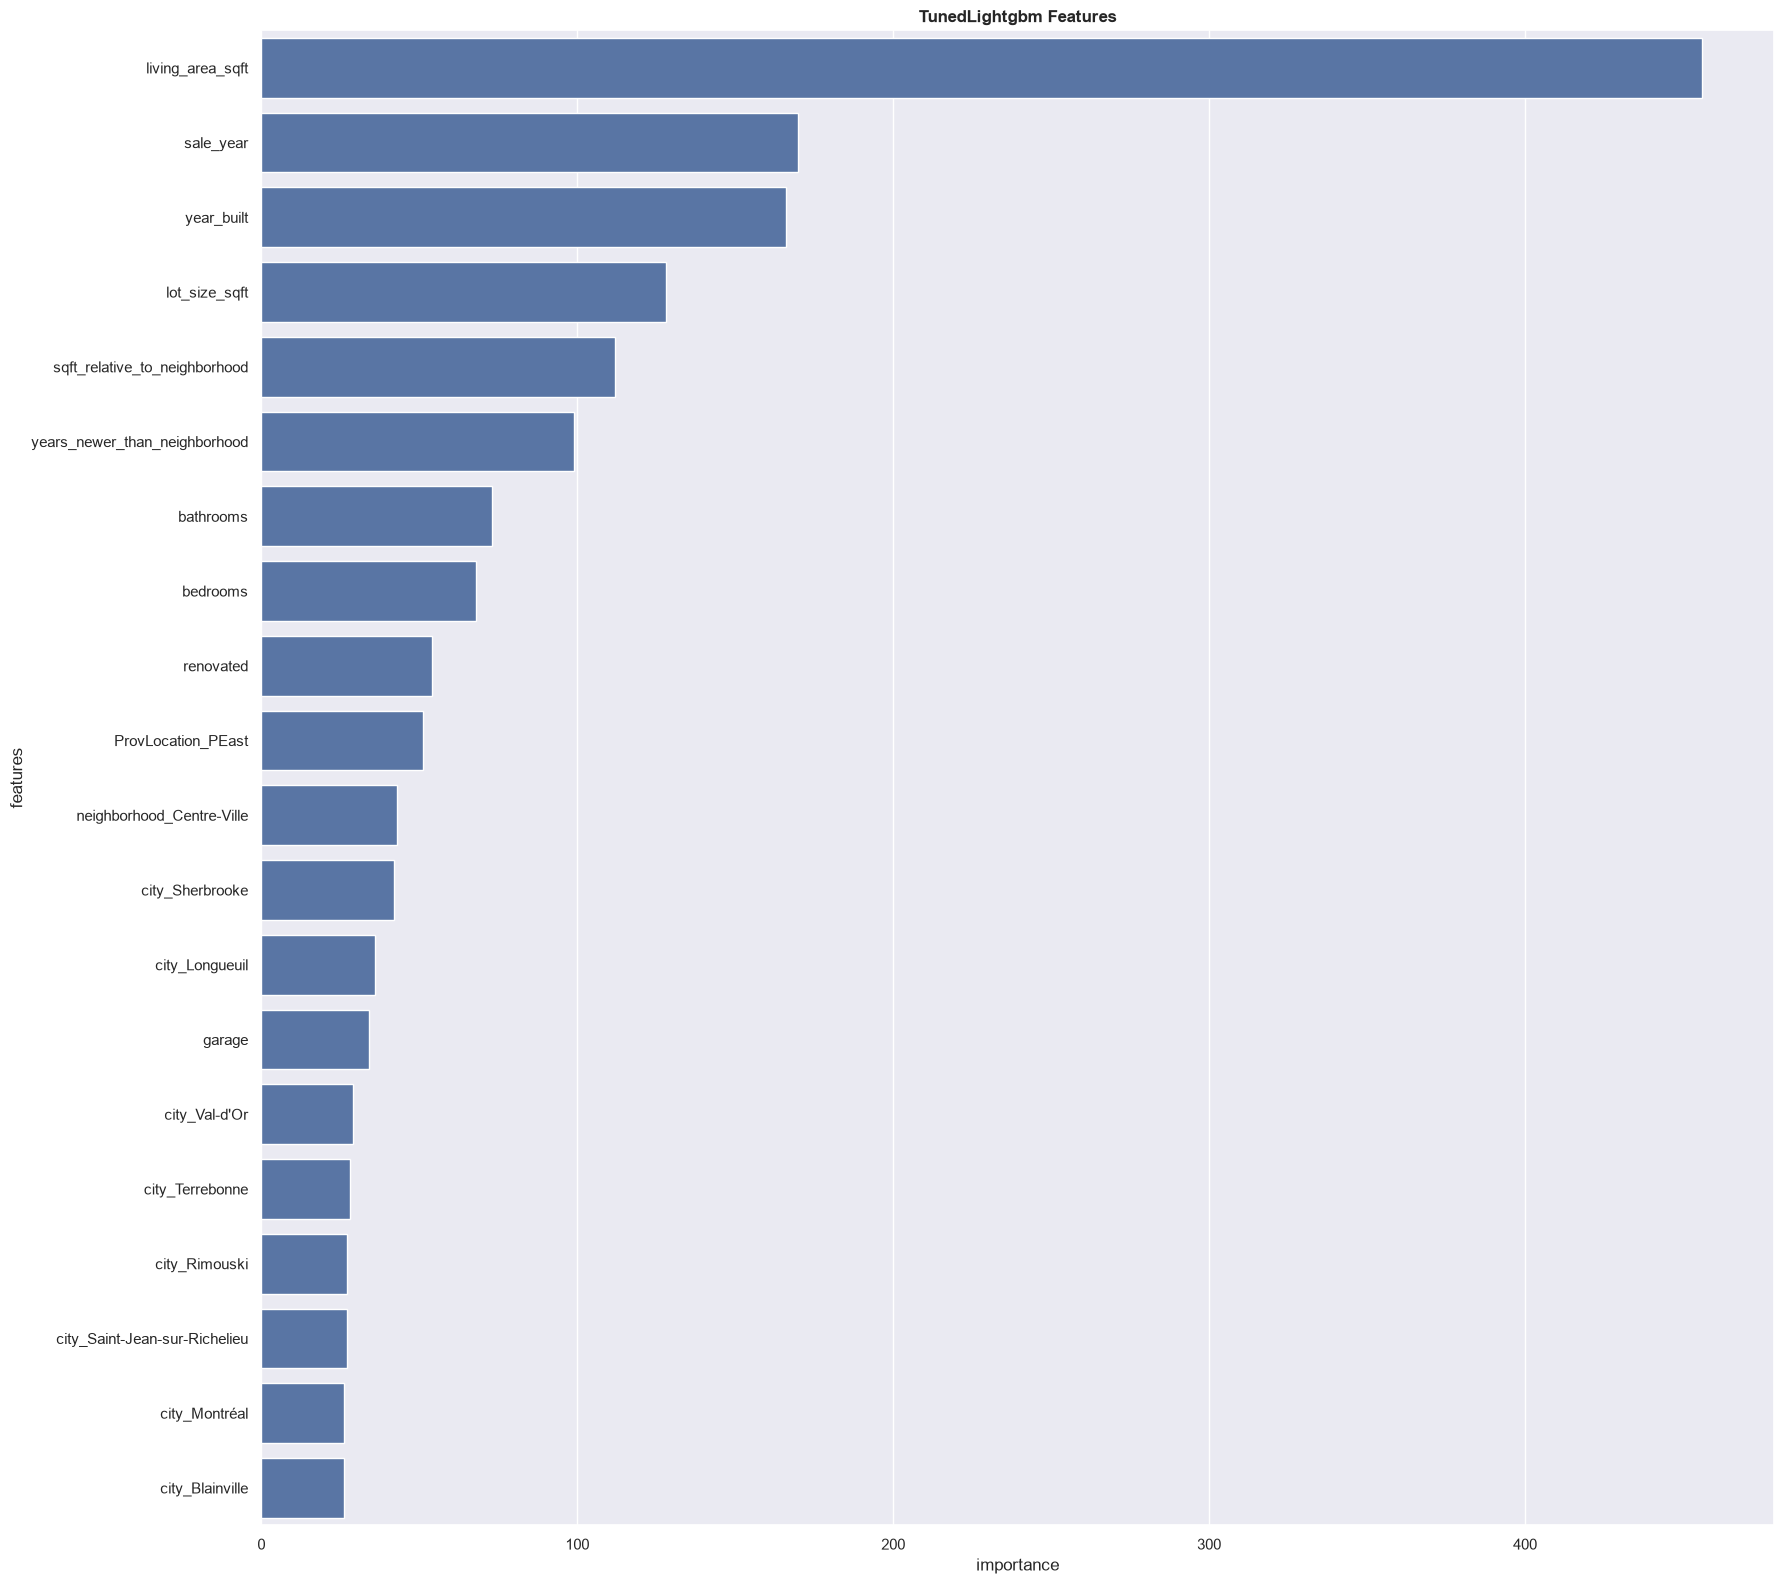

In [83]:
imp=feature_importances_df.sort_values(by="importance", ascending=False).head(20)
plt.figure(figsize=(18, 16))
sns.set(font_scale = 1)
sns.barplot(x="importance", y="features", data=imp.sort_values(by="importance", ascending=False))
plt.title('TunedLightgbm Features', weight='bold')
plt.tight_layout()
plt.show()

## SHAP: Individual AND Aggregate

In [84]:
#For Tuned Lightgbm
X_train=X_train_gb.copy()
y_train =y_train_gb.copy()
X_test=X_test_gb.copy()
y_test = y_test_gb.copy()
model=model_lgb2

STEP 1: Training LightGBM Regressor Model
R² Score:  0.8950
MAE:       43383.6347
RMSE:      56335.1584

Model trained successfully!
Training samples: 4000
Test samples: 1000
Features: 126


PART 1: SHAP ANALYSIS (REGRESSION)

Initializing SHAP TreeExplainer...
Calculating SHAP values (this may take a minute)...
SHAP values calculated! Shape: (1000, 126)

--------------------------------------------------------------------------------
SHAP PLOT 1: Summary Plot (Global Importance)
--------------------------------------------------------------------------------

SUMMARY PLOT INTERPRETATION (REGRESSION)
This plot shows:
- X-axis: SHAP value (impact on numerical prediction in original units)
- Y-axis: Features (ranked by overall importance)
- Color: Feature value (red=high value, blue=low value)
- Each dot: One individual prediction from the test set

How to read it:
1. Features at the TOP are the most influential on the final numeric value.
2. Wide spread = feature can cause massive swing

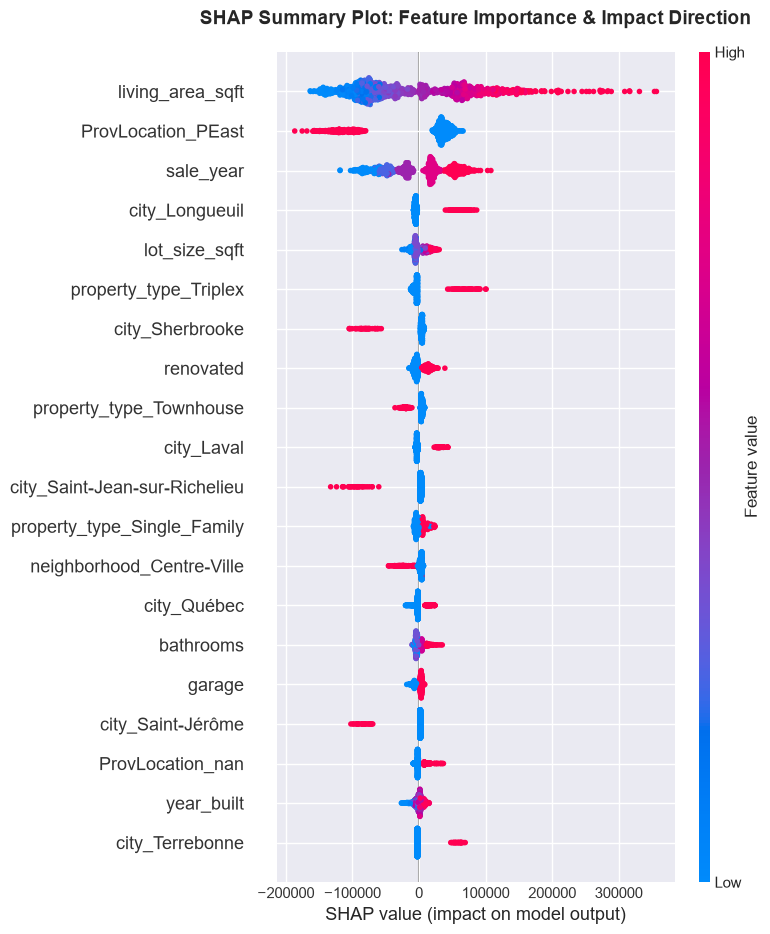


--------------------------------------------------------------------------------
SHAP PLOT 2: Bar Plot (Mean Absolute Impact)
--------------------------------------------------------------------------------

BAR PLOT INTERPRETATION (REGRESSION)
This plot shows the AVERAGE absolute impact of each feature on the final numerical output.

How to read it:
- Longer bar = More important feature (on average, it causes bigger shifts).
- This ignores the DIRECTION (whether it increases or decreases the target value).
- It purely captures the total MAGNITUDE of the impact in the original target units.

Example (Predicting House Prices):
If "Annual Income" or "Living Area" has a bar length of 25,000:
- On average, that feature changes the predicted house price by ±$25,000.
- For some houses it adds to the value, for others it subtracts.
- But on average, its raw pulling power is $25,000 in magnitude.

✓ Saved: shap_bar_plot.png


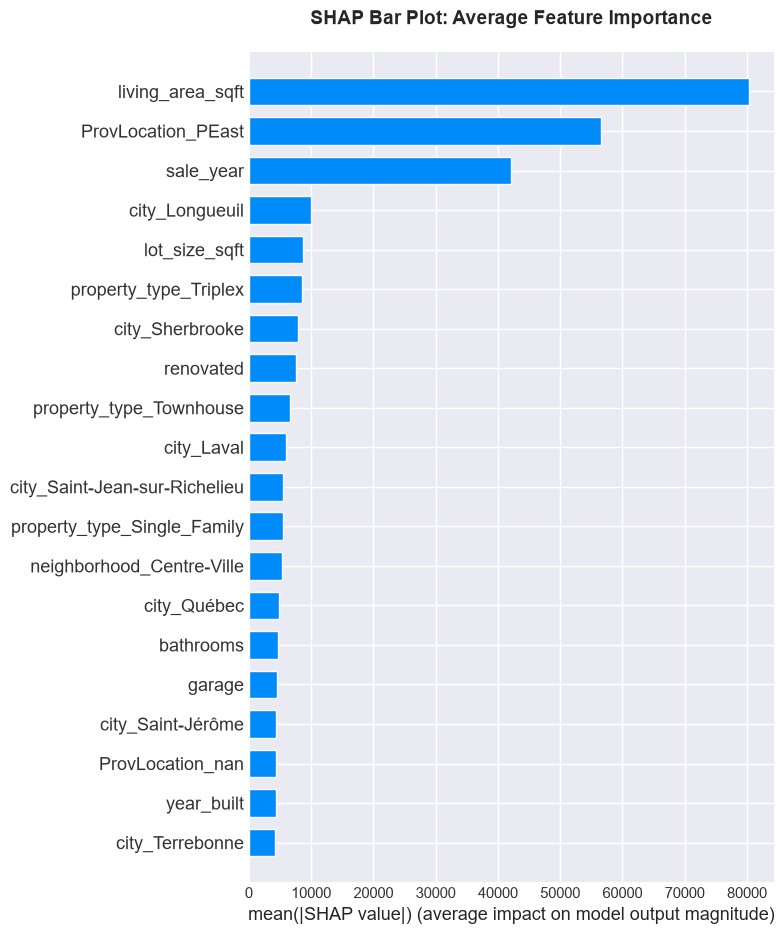


--------------------------------------------------------------------------------
SHAP PLOT 3: Waterfall Plot (Individual Explanation)
--------------------------------------------------------------------------------

WATERFALL PLOT INTERPRETATION (REGRESSION)
This explains ONE specific numerical prediction step-by-step.

How to read it:
- Starts at the base value (E(f(x)) = the average prediction for all samples).
- Each bar shows how one feature pushes the prediction up or down in raw units.
- Red bars = Push prediction HIGHER (increase the output value).
- Blue bars = Push prediction LOWER (decrease the output value).
- Final value at the top = the actual exact numeric prediction for this sample.

Example walkthrough (Predicting House Prices):
1. Base value: $300,000 (Average price across all houses)
2. Large living area (+$100,000): Now at $400,000
3. Close to downtown (+$40,000): Now at $440,000
4. Busy main street (-$15,000): Now at $425,000
5. ... (other features)
6. Final predic

findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmti10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


✓ Saved: shap_waterfall_high_prediction.png


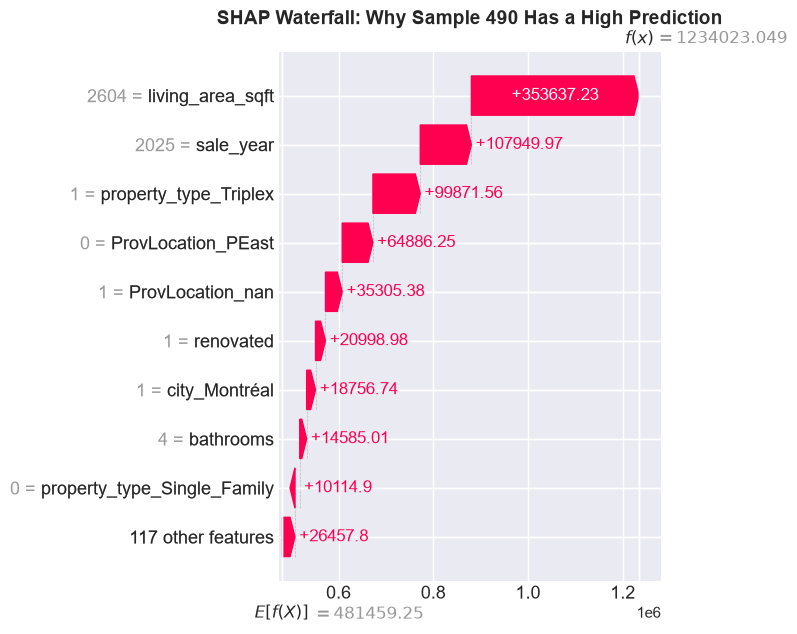


Analyzing LOWEST prediction sample (index 480)
Predicted Value: 147556.9126
Actual Value:    148000.0000
✓ Saved: shap_waterfall_low_prediction.png


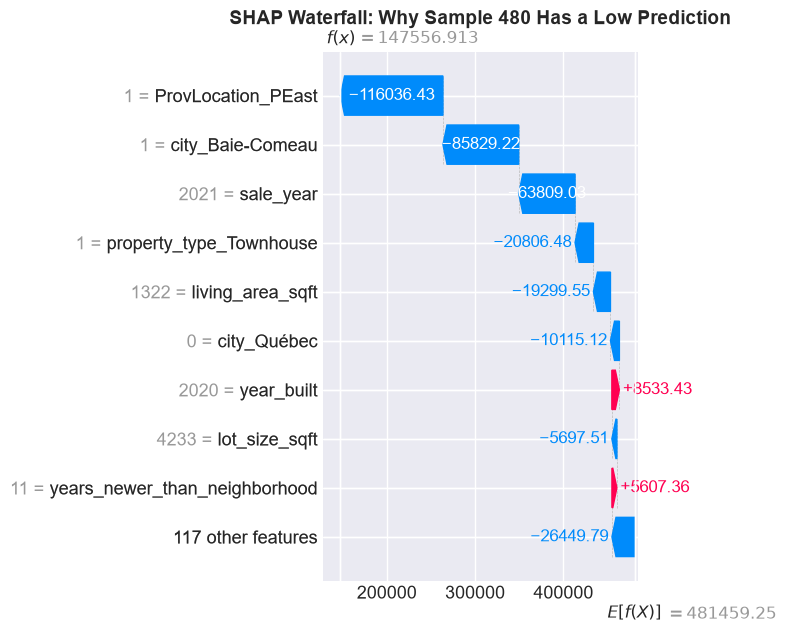


--------------------------------------------------------------------------------
SHAP PLOT 4: Force Plot (Individual Horizon Impact)
--------------------------------------------------------------------------------

FORCE PLOT INTERPRETATION (REGRESSION)
Similar to the waterfall plot, but visualized horizontally as a tug-of-war.

- Red sections = Push the continuous prediction HIGHER (increasing the final value).
- Blue sections = Pull the continuous prediction LOWER (decreasing the final value).
- The width of each block shows the size/magnitude of that feature's impact.
- The bold number where the red and blue blocks meet is the final predicted output.

✓ Saved: shap_force_high_prediction.png


<Figure size 1200x400 with 0 Axes>

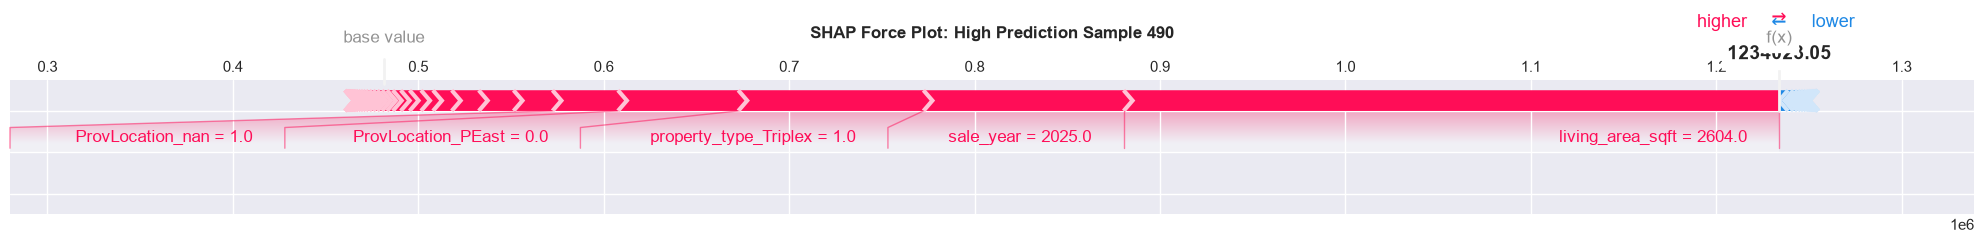


--------------------------------------------------------------------------------
SHAP PLOT 5: Dependence Plot (Feature Relationships)
--------------------------------------------------------------------------------

DEPENDENCE PLOT INTERPRETATION (REGRESSION)
This plot reveals non-linear patterns and interaction thresholds for continuous variables.

- X-axis: Actual raw value of the feature (e.g., Square Footage, Years of Experience).
- Y-axis: SHAP value (The direct numerical value added or subtracted from the prediction).
- Color: Automatically selected interaction feature (shows how a second variable shifts the impact).

How to read it:
1. Upward trend = As this feature increases, it pushes the target value HIGHER.
2. Downward trend = As this feature increases, it pulls the target value LOWER.
3. Plateau/Flattening = Indicates diminishing returns or a ceiling/floor effect.
4. Vertical Color Split = Shows an interaction (e.g., High feature values only push predictions 
   up when th

<Figure size 1000x600 with 0 Axes>

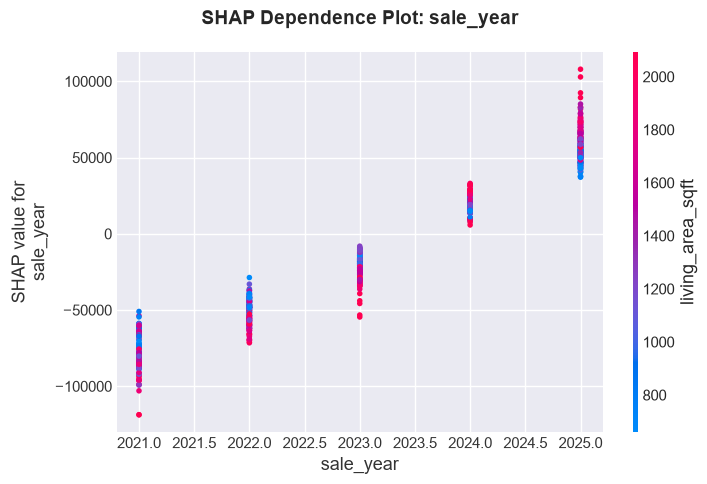

✓ Saved: shap_dependence_ProvLocation_PEast.png


<Figure size 1000x600 with 0 Axes>

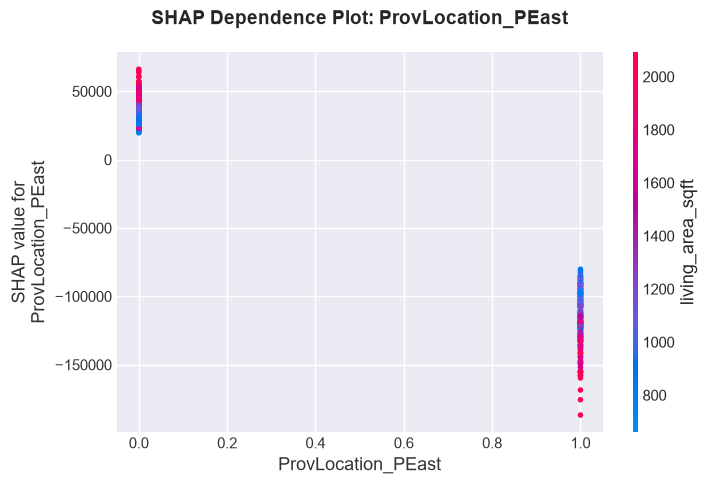

✓ Saved: shap_dependence_living_area_sqft.png


<Figure size 1000x600 with 0 Axes>

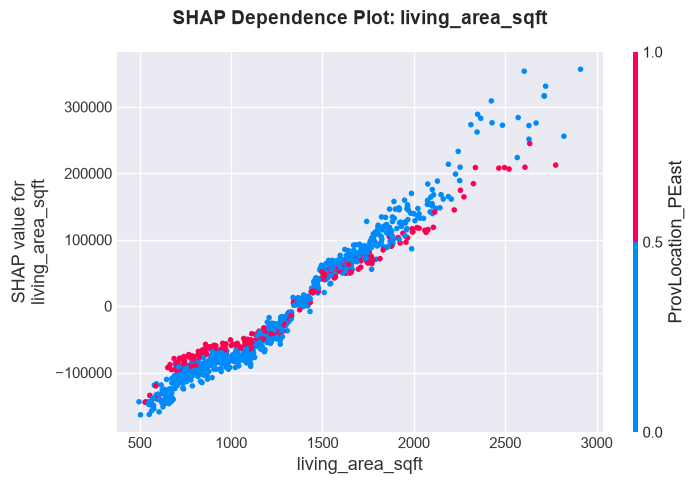



PART 2: LIME ANALYSIS (REGRESSION)

Initializing LIME Tabular Explainer for Regression...
LIME regression explainer initialized!

--------------------------------------------------------------------------------
LIME EXPLANATION 1: High Prediction Sample
--------------------------------------------------------------------------------
Explaining high prediction sample (index 490)...

LIME Explanation (text format):
  ProvLocation_PEast <= 0.00          : +174734.0322
  city_Val-d'Or <= 0.00               : +173477.2447
  living_area_sqft > 1656.25          : +171059.2406
  2024.00 < sale_year <= 2025.00      : +91684.4943
  city_Saint-Jean-sur-Richelieu <= 0.00 : +91031.6156
  city_Saint-Jérôme <= 0.00           : +85151.4114
  city_Sherbrooke <= 0.00             : +85039.4110
  city_Châteauguay <= 0.00            : +76894.9143
  city_Rouyn-Noranda <= 0.00          : +74989.2863
  city_Alma <= 0.00                   : +68496.9800

✓ Saved: lime_high_prediction.png


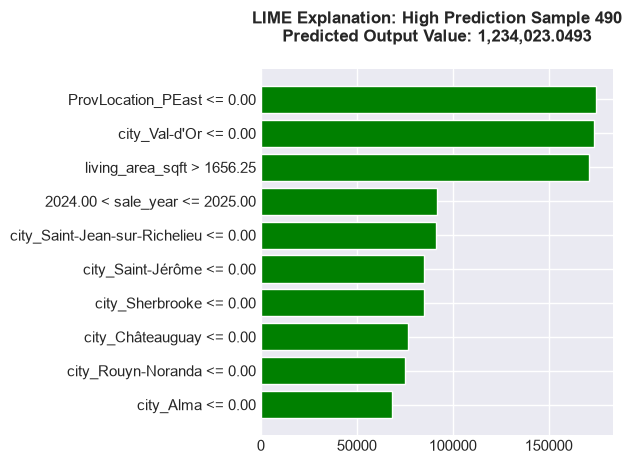


--------------------------------------------------------------------------------
LIME EXPLANATION 2: Low Prediction Sample
--------------------------------------------------------------------------------
Explaining low prediction sample (index 480)...

LIME Explanation (text format):
  city_Val-d'Or <= 0.00               : +191720.5212
  ProvLocation_PEast > 0.00           : -165648.8564
  city_Saint-Jean-sur-Richelieu <= 0.00 : +90230.2447
  city_Châteauguay <= 0.00            : +88072.2944
  city_Sept-Îles <= 0.00              : +87268.3594
  sale_year <= 2022.00                : -83616.5233
  city_Sherbrooke <= 0.00             : +72008.8473
  city_Saint-Jérôme <= 0.00           : +70611.6593
  city_Mirabel <= 0.00                : +65776.5626
  city_Rouyn-Noranda <= 0.00          : +63644.2020

✓ Saved: lime_low_prediction.png


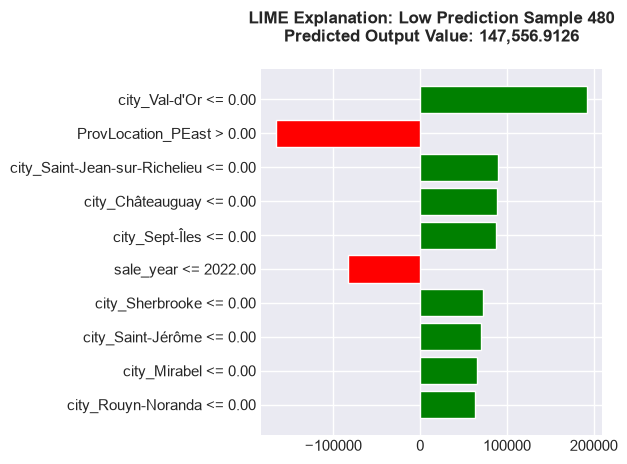


--------------------------------------------------------------------------------
LIME: Analyzing 5 Random Samples
--------------------------------------------------------------------------------

Sample 1 (index 521):
  Predicted Value: 584,541.0882
  Actual Value:    618,000.0000
  Top 5 Local Feature Drivers:
    - city_Val-d'Or <= 0.00               : INCREASES  value by 185,030.2082
    - ProvLocation_PEast <= 0.00          : INCREASES  value by 171,694.4434
    - city_Sherbrooke <= 0.00             : INCREASES  value by 84,352.2053
    - city_Longueuil <= 0.00              : DECREASES  value by 67,923.8385
    - 1279.00 < living_area_sqft <= 1656.25 : INCREASES  value by 44,211.0697

Sample 2 (index 737):
  Predicted Value: 752,369.1274
  Actual Value:    735,000.0000
  Top 5 Local Feature Drivers:
    - city_Val-d'Or <= 0.00               : INCREASES  value by 219,940.1859
    - ProvLocation_PEast <= 0.00          : INCREASES  value by 170,343.4118
    - living_area_sqft > 1656.

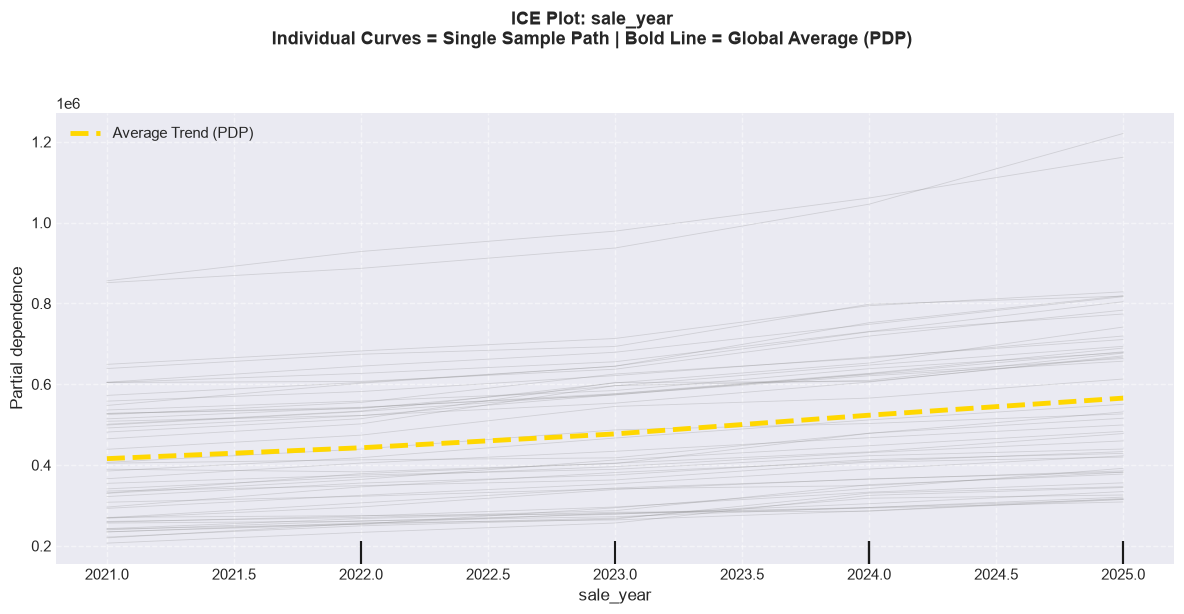


Processing ICE plot pipeline for: ProvLocation_PEast
✓ Saved: ice_plot_ProvLocation_PEast.png


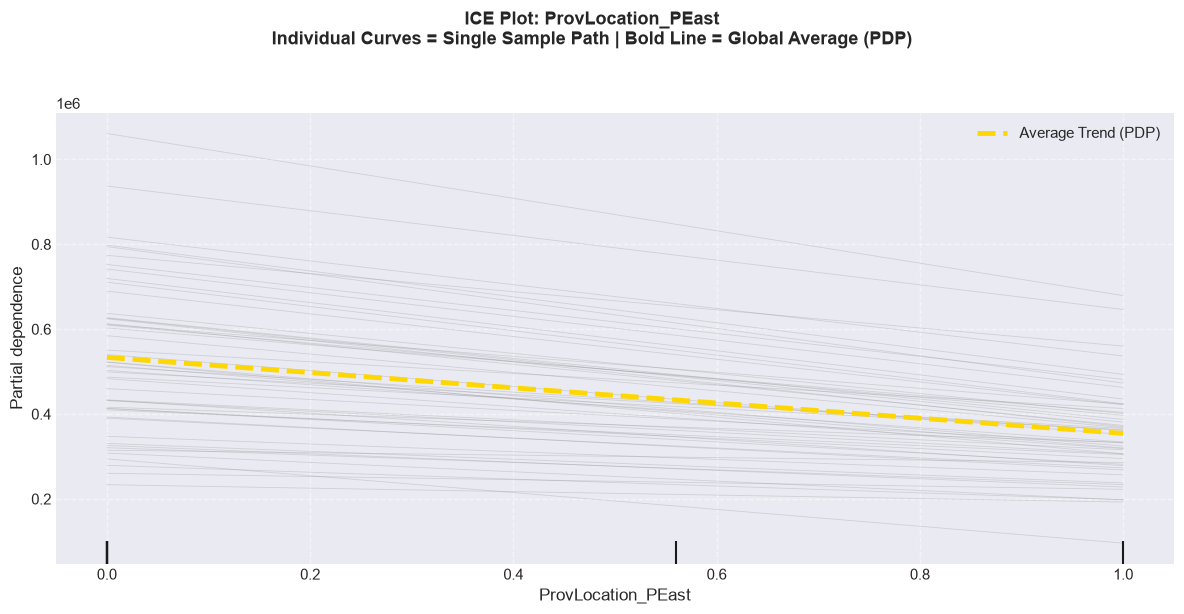


Processing ICE plot pipeline for: living_area_sqft
✓ Saved: ice_plot_living_area_sqft.png


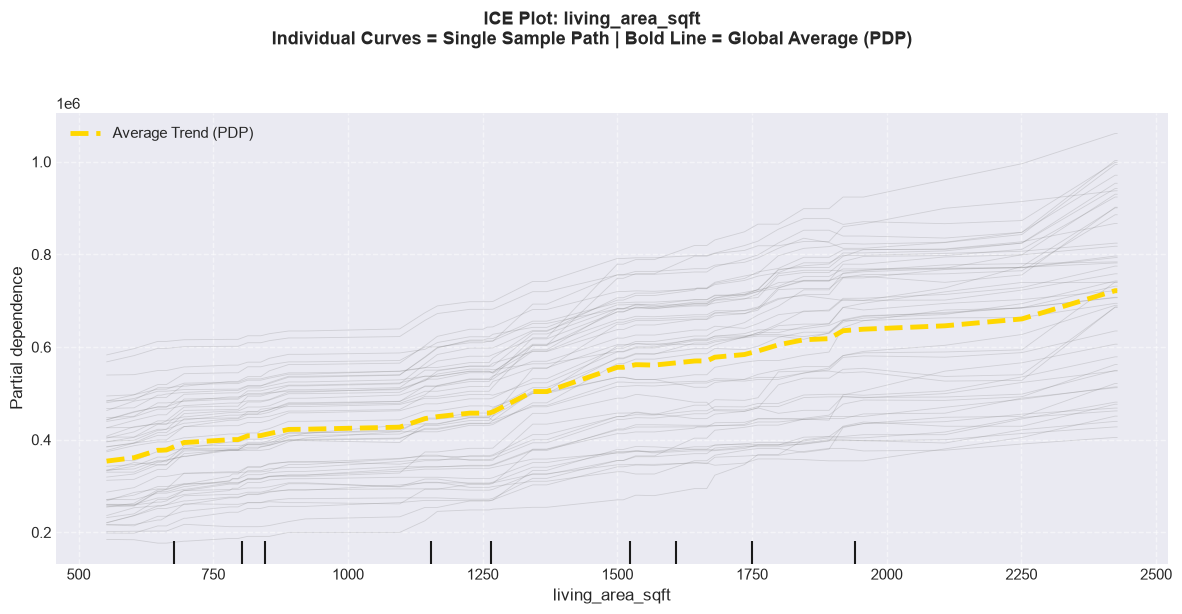


--------------------------------------------------------------------------------
ICE PLOT: Manual Analysis for Specific Samples (Regression)
--------------------------------------------------------------------------------

MANUAL ICE PLOT (WHAT-IF SCENARIOS)
Let's manually create an ICE plot to execute custom "what-if" simulations.
We'll take a few individual samples and systematically shift one specific feature
across its entire range while locking all other features in place.

This allows us to track exactly how the numerical prediction fluctuates:
"What if this specific property had a different square footage or age?"

Analyzing feature: living_area_sqft
✓ Saved: ice_manual_comparison_living_area_sqft.png


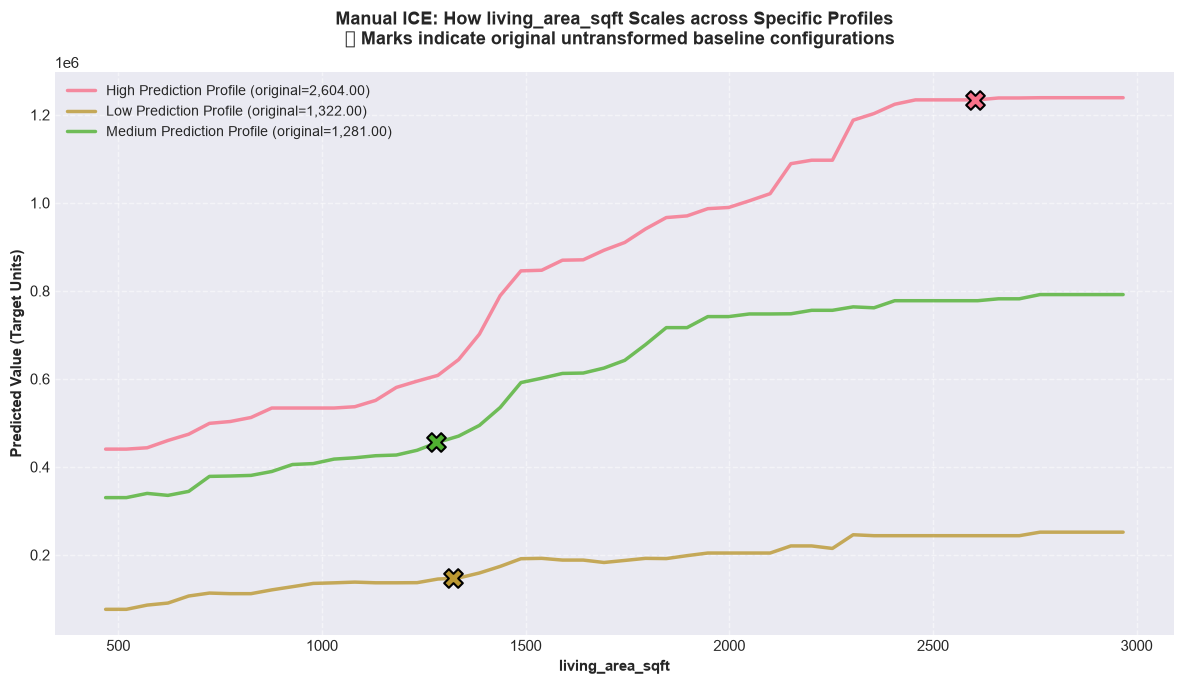


Interpretation:
- Each continuous line tracks how changing 'living_area_sqft' scales that individual profile's outcome.
- ❌ marks highlight their exact real-world baseline parameters.
- Varying slopes or intersecting paths expose hidden interaction dependencies (heterogeneity) inside the model.


SUMMARY: SHAP vs LIME vs ICE

┌─────────────┬──────────────────────────────┬──────────────────────────────┬──────────────────────────────┐
│ Aspect      │ SHAP                         │ LIME                         │ ICE                          │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Question    │ "How much does each feature  │ "Why this specific           │ "How would prediction change │
│             │  contribute?"                │  prediction?"                │  if we varied one feature?"  │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Scope       │ G

In [85]:
import shap
import lime
import lime.lime_tabular
from sklearn.inspection import PartialDependenceDisplay

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# ══════════════════════════════════════════════════════════════════════════════
# STEP 1: Train LightGBM Regressor Model
# ══════════════════════════════════════════════════════════════════════════════
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("=" * 80)
print("STEP 1: Training LightGBM Regressor Model")
print("=" * 80)

# Initialize and train regression model
model = LGBMRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    verbose=-1
)

model.fit(X_train, y_train)

# Evaluate predictions (Regression outputs continuous numeric values)
y_pred = model.predict(X_test)

# Calculate metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² Score:  {r2:.4f}")
print(f"MAE:       {mae:.4f}")
print(f"RMSE:      {rmse:.4f}")
print(f"\nModel trained successfully!")
print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")
print(f"Features: {X_train.shape[1]}")

# ══════════════════════════════════════════════════════════════════════════════
# PART 1: SHAP (SHapley Additive exPlanations) - Regression
# ══════════════════════════════════════════════════════════════════════════════
import shap

print("\n\n" + "=" * 80)
print("PART 1: SHAP ANALYSIS (REGRESSION)")
print("=" * 80)

"""
WHAT IS SHAP FOR REGRESSION?
============================
SHAP (SHapley Additive exPlanations) answers the question:
"How much does each feature add to or subtract from the numerical prediction?"

Think of it like a team game:
- The baseline is the average value the model predicts for the whole dataset.
- The final prediction is the specific numerical value predicted for one row.
- SHAP values tell you exactly how many units each feature added or subtracted.

SHAP calculates values for EACH individual record, but can also show aggregate patterns across all records.
# Each row = SHAP values for ONE sample
# shap_values[0] = SHAP values for sample 0
# shap_values[1] = SHAP values for sample 1
# ... and so on

Example (Predicting House Prices):
Base prediction (average house price): $300,000
House A's prediction:                 $450,000

SHAP breakdown:
- Large living area (sqft):   +$120,000 (increases price)
- Premium neighborhood:       + $40,000 (increases price)
- Old roof condition:         - $15,000 (decreases price)
- Small yard size:            -  $5,000 (decreases price)
                              ---------
Total change:                 +$140,000 → Final: $300,000 + $140,000 = $450,000 ✓

Key Concepts:
1. POSITIVE SHAP value = Pushes prediction HIGHER (increases the predicted number)
2. NEGATIVE SHAP value = Pushes prediction LOWER (decreases the predicted number)
3. Sum of all SHAP values = Final prediction - Base prediction

Why SHAP is powerful:
✓ Based on game theory (Shapley values) - mathematically rigorous
✓ Consistent across all models (works for any ML algorithm)
✓ Provides both global (overall) and local (individual) explanations
✓ Shows feature interactions
"""

# Initialize SHAP explainer for tree-based regression models
print("\nInitializing SHAP TreeExplainer...")
explainer = shap.TreeExplainer(model)

# Calculate SHAP values for test set
print("Calculating SHAP values (this may take a minute)...")
shap_values = explainer.shap_values(X_test)

# NOTE: For regression, TreeExplainer always returns a single array or a direct Explainer object.
# We extract the raw values if an Explainer object is returned by newer SHAP versions.
if hasattr(shap_values, 'values'):
    shap_values = shap_values.values

print(f"SHAP values calculated! Shape: {shap_values.shape}")


# ──────────────────────────────────────────────────────────────────────────────
# SHAP Plot 1: Summary Plot (Global Feature Importance) - Regression
# ──────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt

print("\n" + "-" * 80)
print("SHAP PLOT 1: Summary Plot (Global Importance)")
print("-" * 80)
print("""
SUMMARY PLOT INTERPRETATION (REGRESSION)
=======================================
This plot shows:
- X-axis: SHAP value (impact on numerical prediction in original units)
- Y-axis: Features (ranked by overall importance)
- Color: Feature value (red=high value, blue=low value)
- Each dot: One individual prediction from the test set

How to read it:
1. Features at the TOP are the most influential on the final numeric value.
2. Wide spread = feature can cause massive swings in the prediction.
3. Dots on the RIGHT of 0 = feature pushed the prediction HIGHER than average.
4. Dots on the LEFT of 0 = feature pulled the prediction LOWER than average.

Example interpretation (Predicting House Prices):
"Living Area (SqFt)" at the top with:
- Red dots (large houses) on the RIGHT → High square footage INCREASES the price.
- Blue dots (small houses) on the LEFT → Low square footage DECREASES the price.
The units on the X-axis tell you exactly how many dollars were added or subtracted!
""")

plt.figure(figsize=(12, 8))
# Note: For regression, ensure shap_values is a 2D numpy array of shape (n_samples, n_features)
shap.summary_plot(shap_values, X_test, plot_type="dot", show=False)

plt.title("SHAP Summary Plot: Feature Importance & Impact Direction", 
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('shap_summary_plot.png', dpi=300, bbox_inches='tight')
print("✓ Saved: shap_summary_plot.png")
plt.show()

# ──────────────────────────────────────────────────────────────────────────────
# SHAP Plot 2: Bar Plot (Average Absolute SHAP Values) - Regression
# ──────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import shap

print("\n" + "-" * 80)
print("SHAP PLOT 2: Bar Plot (Mean Absolute Impact)")
print("-" * 80)

print("""
BAR PLOT INTERPRETATION (REGRESSION)
===================================
This plot shows the AVERAGE absolute impact of each feature on the final numerical output.

How to read it:
- Longer bar = More important feature (on average, it causes bigger shifts).
- This ignores the DIRECTION (whether it increases or decreases the target value).
- It purely captures the total MAGNITUDE of the impact in the original target units.

Example (Predicting House Prices):
If "Annual Income" or "Living Area" has a bar length of 25,000:
- On average, that feature changes the predicted house price by ±$25,000.
- For some houses it adds to the value, for others it subtracts.
- But on average, its raw pulling power is $25,000 in magnitude.
""")

plt.figure(figsize=(10, 8))
# Generates a clean bar chart based on mean absolute values
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)

plt.title("SHAP Bar Plot: Average Feature Importance", 
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('shap_bar_plot.png', dpi=300, bbox_inches='tight')
print("✓ Saved: shap_bar_plot.png")
plt.show()


# ──────────────────────────────────────────────────────────────────────────────
# SHAP Plot 3: Waterfall Plot (Individual Prediction Explanation) - Regression
# ──────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np
import shap

print("\n" + "-" * 80)
print("SHAP PLOT 3: Waterfall Plot (Individual Explanation)")
print("-" * 80)

print("""
WATERFALL PLOT INTERPRETATION (REGRESSION)
=========================================
This explains ONE specific numerical prediction step-by-step.

How to read it:
- Starts at the base value (E(f(x)) = the average prediction for all samples).
- Each bar shows how one feature pushes the prediction up or down in raw units.
- Red bars = Push prediction HIGHER (increase the output value).
- Blue bars = Push prediction LOWER (decrease the output value).
- Final value at the top = the actual exact numeric prediction for this sample.

Example walkthrough (Predicting House Prices):
1. Base value: $300,000 (Average price across all houses)
2. Large living area (+$100,000): Now at $400,000
3. Close to downtown (+$40,000): Now at $440,000
4. Busy main street (-$15,000): Now at $425,000
5. ... (other features)
6. Final prediction: $432,000

This tells the exact STORY of how a single prediction was constructed.
""")

# Handle potential expected_value format differences from TreeExplainer
base_val = explainer.expected_value
if isinstance(base_val, (list, np.ndarray)) and len(base_val) > 1:
    base_val = base_val[0]

# 1. Pick the sample with the HIGHEST predicted value
high_pred_idx = np.argmax(y_pred)
print(f"Analyzing HIGHEST prediction sample (index {high_pred_idx})")
print(f"Predicted Value: {y_pred[high_pred_idx]:.4f}")
print(f"Actual Value:    {y_test.iloc[high_pred_idx] if hasattr(y_test, 'iloc') else y_test[high_pred_idx]:.4f}")

# Create waterfall plot for highest prediction
plt.figure(figsize=(12, 8))
shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[high_pred_idx],
        base_values=base_val,
        data=X_test.iloc[high_pred_idx] if hasattr(X_test, 'iloc') else X_test[high_pred_idx],
        feature_names=X_test.columns.tolist() if hasattr(X_test, 'columns') else None
    ),
    show=False
)
plt.title(f"SHAP Waterfall: Why Sample {high_pred_idx} Has a High Prediction", 
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('shap_waterfall_high_prediction.png', dpi=300, bbox_inches='tight')
print("✓ Saved: shap_waterfall_high_prediction.png")
plt.show()


# 2. Pick the sample with the LOWEST predicted value
low_pred_idx = np.argmin(y_pred)
print(f"\nAnalyzing LOWEST prediction sample (index {low_pred_idx})")
print(f"Predicted Value: {y_pred[low_pred_idx]:.4f}")
print(f"Actual Value:    {y_test.iloc[low_pred_idx] if hasattr(y_test, 'iloc') else y_test[low_pred_idx]:.4f}")

# Create waterfall plot for lowest prediction
plt.figure(figsize=(12, 8))
shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[low_pred_idx],
        base_values=base_val,
        data=X_test.iloc[low_pred_idx] if hasattr(X_test, 'iloc') else X_test[low_pred_idx],
        feature_names=X_test.columns.tolist() if hasattr(X_test, 'columns') else None
    ),
    show=False
)
plt.title(f"SHAP Waterfall: Why Sample {low_pred_idx} Has a Low Prediction", 
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('shap_waterfall_low_prediction.png', dpi=300, bbox_inches='tight')
print("✓ Saved: shap_waterfall_low_prediction.png")
plt.show()

# ──────────────────────────────────────────────────────────────────────────────
# SHAP Plot 4: Force Plot (Individual Horizon Explanation) - Regression
# ──────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np
import shap

print("\n" + "-" * 80)
print("SHAP PLOT 4: Force Plot (Individual Horizon Impact)")
print("-" * 80)

print("""
FORCE PLOT INTERPRETATION (REGRESSION)
=====================================
Similar to the waterfall plot, but visualized horizontally as a tug-of-war.

- Red sections = Push the continuous prediction HIGHER (increasing the final value).
- Blue sections = Pull the continuous prediction LOWER (decreasing the final value).
- The width of each block shows the size/magnitude of that feature's impact.
- The bold number where the red and blue blocks meet is the final predicted output.
""")

# Handle potential expected_value format differences from TreeExplainer
base_val = explainer.expected_value
if isinstance(base_val, (list, np.ndarray)) and len(base_val) > 1:
    base_val = base_val[1] # standard fallback if formatting overlaps

# Force plot for the highest predicted sample
plt.figure(figsize=(12, 4))
shap.force_plot(
    base_val,
    shap_values[high_pred_idx],
    X_test.iloc[high_pred_idx] if hasattr(X_test, 'iloc') else X_test[high_pred_idx],
    matplotlib=True,
    show=False
)

plt.title(f"SHAP Force Plot: High Prediction Sample {high_pred_idx}", 
          fontsize=12, fontweight='bold', pad=30)
plt.tight_layout()
plt.savefig('shap_force_high_prediction.png', dpi=300, bbox_inches='tight')
print("✓ Saved: shap_force_high_prediction.png")
plt.show()

# ──────────────────────────────────────────────────────────────────────────────
# SHAP Plot 5: Dependence Plot (Feature Interaction) - Regression
# ──────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np
import shap

print("\n" + "-" * 80)
print("SHAP PLOT 5: Dependence Plot (Feature Relationships)")
print("-" * 80)

print("""
DEPENDENCE PLOT INTERPRETATION (REGRESSION)
===========================================
This plot reveals non-linear patterns and interaction thresholds for continuous variables.

- X-axis: Actual raw value of the feature (e.g., Square Footage, Years of Experience).
- Y-axis: SHAP value (The direct numerical value added or subtracted from the prediction).
- Color: Automatically selected interaction feature (shows how a second variable shifts the impact).

How to read it:
1. Upward trend = As this feature increases, it pushes the target value HIGHER.
2. Downward trend = As this feature increases, it pulls the target value LOWER.
3. Plateau/Flattening = Indicates diminishing returns or a ceiling/floor effect.
4. Vertical Color Split = Shows an interaction (e.g., High feature values only push predictions 
   up when the secondary color-coded feature is also high).

Example (Predicting House Prices):
If evaluating "Living Area (SqFt)":
- Small sizes (left) have negative SHAP values → lowers the home valuation below average.
- Large sizes (right) have positive SHAP values → raises the home valuation above average.
- Color pattern (Age of Home): Large sizes might have a much higher SHAP impact (brighter red) 
   if the home is new versus old.
""")

# Ensure shap_values is a 2D numpy array of shape (n_samples, n_features)
# Get top 3 most important features based on mean absolute magnitude
feature_importance = np.abs(shap_values).mean(axis=0)
top_features_idx = np.argsort(feature_importance)[-3:]
top_features = X_test.columns[top_features_idx].tolist()

print(f"Creating dependence plots for the top 3 features: {top_features}")

for feature in top_features:
    plt.figure(figsize=(10, 6))
    
    # Generate the dependence plot
    # SHAP automatically finds the best interaction feature to color code by default
    shap.dependence_plot(
        feature,
        shap_values,
        X_test,
        show=False
    )
    
    plt.title(f"SHAP Dependence Plot: {feature}", 
              fontsize=14, fontweight='bold', pad=20)
    plt.tight_layout()
    
    # Sanitize feature name for file system safety
    safe_feature_name = feature.replace('/', '_').replace(' ', '_').replace(':', '_')
    file_name = f'shap_dependence_{safe_feature_name}.png'
    
    plt.savefig(file_name, dpi=300, bbox_inches='tight')
    print(f"✓ Saved: {file_name}")
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PART 2: LIME (Local Interpretable Model-agnostic Explanations) - Regression
# ══════════════════════════════════════════════════════════════════════════════
import lime
import lime.lime_tabular

print("\n\n" + "=" * 80)
print("PART 2: LIME ANALYSIS (REGRESSION)")
print("=" * 80)

"""
WHAT IS LIME FOR REGRESSION?
============================
LIME answers: "Why did the model predict THIS specific numerical value?"

How LIME works:
1. Take one prediction you want to explain.
2. Create thousands of "similar" synthetic variations of that sample.
3. Observe how the complex model predicts values on these variations.
4. Fit a simple linear model to approximate the complex model's local behavior.
5. The simple model's weights/coefficients explain the local decision.

Think of it like this:
- Complex model = A brilliant expert who can't explain their pricing strategy.
- LIME = A translator who fits a simple "rule-of-thumb" line to explain that single decision.

Example LIME output (Predicting House Prices):
"House A predicted price: $450,000 because:"
- Living Area > 2,500 sqft     (Adds $80,000)
- Neighborhood = Premium       (Adds $45,000)
- Age > 30 years               (Subtracts $12,000)
- No Garage                    (Subtracts $8,000)

Key differences from SHAP:
- SHAP: Globally consistent, mathematically rigorous, but computationally slower.
- LIME: Faster, model-agnostic, but approximations can vary slightly between runs.
- LIME: Highly intuitive for presenting localized rules to non-technical business partners.
- SHAP: Ideal for comprehensive technical audits and root-cause analysis.
"""

# Initialize LIME explainer for regression tasks
print("\nInitializing LIME Tabular Explainer for Regression...")
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    mode='regression',  # Changed from 'classification' to 'regression'
    random_state=42
)

print("LIME regression explainer initialized!")

# ──────────────────────────────────────────────────────────────────────────────
# LIME Explanation 1: High Prediction Sample
# ──────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt

print("\n" + "-" * 80)
print("LIME EXPLANATION 1: High Prediction Sample")
print("-" * 80)

"""
HOW TO READ LIME REGRESSION OUTPUT
==================================
Left side / Negative values: Features that DECREASE the final numerical prediction
Right side / Positive values: Features that INCREASE the final numerical prediction

Example (Predicting House Prices):
Positive/Right (increases value):
  Living_Area > 2500.00             80000.00  ████████████
  Neighborhood = Premium           45000.00  ███████
  
Negative/Left (decreases value):
  Age > 30.00                     -12000.00  ██
  No_Garage                        -8000.00  █

Prediction value: $450,000

This means:
- Large living area is the BIGGEST reason for the high valuation (+$80k)
- Premium neighborhood also pushes the price up significantly (+$45k)
- House age slightly penalizes the value (-$12k)
- Lack of a garage pulls it down a bit further (-$8k)
"""

print(f"Explaining high prediction sample (index {high_pred_idx})...")

# Get LIME explanation using the regression predict function
lime_exp_high = lime_explainer.explain_instance(
    data_row=X_test.iloc[high_pred_idx].values if hasattr(X_test, 'iloc') else X_test[high_pred_idx],
    predict_fn=model.predict,  # Changed from model.predict_proba to model.predict
    num_features=10           # Show top 10 contributing features
)

# Display explanation text breakdown
print("\nLIME Explanation (text format):")
for feature_rule, coefficient in lime_exp_high.as_list():
    print(f"  {feature_rule:<35} : {coefficient:+.4f}")

# Plot explanation as a matplotlib figure
fig = lime_exp_high.as_pyplot_figure()
plt.title(f"LIME Explanation: High Prediction Sample {high_pred_idx}\n"
          f"Predicted Output Value: {y_pred[high_pred_idx]:,.4f}",
          fontsize=12, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('lime_high_prediction.png', dpi=300, bbox_inches='tight')
print("\n✓ Saved: lime_high_prediction.png")
plt.show()

# ──────────────────────────────────────────────────────────────────────────────
# LIME Explanation 2: Low Prediction Sample
# ──────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt

print("\n" + "-" * 80)
print("LIME EXPLANATION 2: Low Prediction Sample")
print("-" * 80)

print(f"Explaining low prediction sample (index {low_pred_idx})...")

# Get LIME explanation using the regression predict function
lime_exp_low = lime_explainer.explain_instance(
    data_row=X_test.iloc[low_pred_idx].values if hasattr(X_test, 'iloc') else X_test[low_pred_idx],
    predict_fn=model.predict,  # Changed from model.predict_proba to model.predict
    num_features=10           # Show top 10 contributing features
)

# Display explanation text breakdown
print("\nLIME Explanation (text format):")
for feature_rule, coefficient in lime_exp_low.as_list():
    print(f"  {feature_rule:<35} : {coefficient:+.4f}")

# Plot explanation as a matplotlib figure
fig = lime_exp_low.as_pyplot_figure()
plt.title(f"LIME Explanation: Low Prediction Sample {low_pred_idx}\n"
          f"Predicted Output Value: {y_pred[low_pred_idx]:,.4f}",
          fontsize=12, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('lime_low_prediction.png', dpi=300, bbox_inches='tight')
print("\n✓ Saved: lime_low_prediction.png")
plt.show()


# ──────────────────────────────────────────────────────────────────────────────
# LIME: Compare Multiple Predictions - Regression
# ──────────────────────────────────────────────────────────────────────────────
import numpy as np

print("\n" + "-" * 80)
print("LIME: Analyzing 5 Random Samples")
print("-" * 80)

"""
COMPARING MULTIPLE LIME EXPLANATIONS (REGRESSION)
=================================================
This shows how LIME explanations change dynamically across different samples.
Notice how:
- Different features take priority for different individual records.
- The same feature can push the continuous prediction up or down depending on the context.
- This highlights the "local" nature of LIME — it builds a unique explanation 
  tuned specifically around each individual record's neighborhood.
"""

# Select 5 random test samples
np.random.seed(42)
random_indices = np.random.choice(len(X_test), size=5, replace=False)

for i, idx in enumerate(random_indices):
    # Safe checks for pandas Series vs numpy array indexing
    actual_val = y_test.iloc[idx] if hasattr(y_test, 'iloc') else y_test[idx]
    row_data = X_test.iloc[idx].values if hasattr(X_test, 'iloc') else X_test[idx]
    
    print(f"\nSample {i+1} (index {idx}):")
    print(f"  Predicted Value: {y_pred[idx]:,.4f}")
    print(f"  Actual Value:    {actual_val:,.4f}")
    
    # Get local linear explanation using the regression predict function
    lime_exp = lime_explainer.explain_instance(
        row_data,
        model.predict,  # Changed from model.predict_proba to model.predict
        num_features=5
    )
    
    print("  Top 5 Local Feature Drivers:")
    for feature, weight in lime_exp.as_list()[:5]:
        direction = "INCREASES" if weight > 0 else "DECREASES"
        print(f"    - {feature:<35} : {direction:<10} value by {abs(weight):,.4f}")
# ══════════════════════════════════════════════════════════════════════════════
# PART 3: ICE (Individual Conditional Expectation) Plots - Regression
# ══════════════════════════════════════════════════════════════════════════════
print("\n\n" + "=" * 80)
print("PART 3: ICE PLOTS (REGRESSION)")
print("=" * 80)

print("""
WHAT ARE ICE PLOTS FOR REGRESSION?
==================================
ICE plots answer: "How would the numerical prediction change if we varied ONE specific feature?"

Imagine asking:
"What if this specific asset's square footage was 1,000? 2,000? 3,000? 4,000?"
An ICE plot tracks how the continuous prediction scales across that entire range for individual samples.

How ICE works:
1. Pick one feature to examine (e.g., Living Area / Experience Level).
2. Take a single record and vary ONLY that feature across its entire numerical range.
3. Keep all other feature values for that record completely fixed.
4. Run the model's regression predict function on each variation and map the changes.
5. Repeat this process for multiple individual samples.
6. Plot all the lines together on a single canvas.

ICE vs PDP (Partial Dependence Plot):
- ICE: Shows individual curves for each specific sample (highly detailed).
- PDP: Shows a single bolded average curve across all samples (simplified summary).
- ICE reveals heterogeneity: It proves if different samples react uniquely to feature changes.

Example interpretation (Predicting House Prices):
A Living Area ICE plot might show:
- Most samples: Larger area → Higher predicted value (upward sloping lines).
- Some samples: Beyond 3,000 sqft, the valuation flattens out (diminishing returns).
- Extreme samples: For luxury zip codes, the line jumps up drastically (exponential interaction).

This individual heterogeneity is completely HIDDEN in a standard PDP average line, 
but explicitly REVEALED here in an ICE plot!
""")

# ──────────────────────────────────────────────────────────────────────────────
# ICE Plot 1: Using sklearn's PartialDependenceDisplay with ICE - Regression
# ──────────────────────────────────────────────────────────────────────────────
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt
import numpy as np

print("\n" + "-" * 80)
print("ICE PLOT: Top 3 Most Important Features (Regression)")
print("-" * 80)

print("""
INTERPRETING ICE + PDP PLOTS (REGRESSION)
=========================================
Each plot visualizes two distinct components on a continuous target scale:

1. ICE Curves (thin background lines):
   - Each individual line represents one specific sample from your test subset.
   - It charts exactly how that sample's numeric prediction responds as the feature scales.
   - Splay, cross-over, or diverse slopes indicate significant interaction effects (heterogeneity).

2. PDP Curve (thick yellow line):
   - The global average of all individual ICE curves.
   - Captures the overall directional trend across the dataset.

How to read:
- Lines sloped UP = Higher feature values consistently increase the predicted numeric output.
- Lines sloped DOWN = Higher feature values consistently pull the predicted numeric output down.
- Diverging/Crossing lines = The feature's behavior flips depending on other parameters.
- Flat lines = Changing this feature has zero localized impact on those records.
""")

# Sample data points for ICE (evaluating the entire test split can heavily lag)
ice_sample_size = min(50, len(X_test))
np.random.seed(42) # Ensuring reproducibility across runs
ice_indices = np.random.choice(len(X_test), size=ice_sample_size, replace=False)

# Safe slice supporting pandas DataFrame or numpy structures
X_ice = X_test.iloc[ice_indices] if hasattr(X_test, 'iloc') else X_test[ice_indices]

print(f"Using a subset of {ice_sample_size} samples for visualization generation.")
print(f"Creating ICE plots for: {top_features}")

for feature in top_features:
    # Resolve index positional reference safely
    feature_idx = X_train.columns.get_loc(feature) if hasattr(X_train, 'columns') else feature
    # 1. Cast your ICE feature matrix to float to satisfy scikit-learn
    X_ice = X_ice.astype(float)
    
    print(f"\nProcessing ICE plot pipeline for: {feature}")
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # from_estimator seamlessly works on LightGBMRegressor models
    display = PartialDependenceDisplay.from_estimator(
        estimator=model,
        X=X_ice,
        features=[feature_idx],
        kind='both',  # 'both' maps individual ICE lines alongside the macro PDP trend
        ice_lines_kw={'alpha': 0.25, 'linewidth': 0.6, 'color': 'gray'}, # Distinct transparent curves
        pd_line_kw={'color': 'gold', 'linewidth': 3.5, 'label': 'Average Trend (PDP)'}, # Prominent summary line
        ax=ax
    )
    
    plt.suptitle(f"ICE Plot: {feature}\n"
                 f"Individual Curves = Single Sample Path | Bold Line = Global Average (PDP)",
                 fontsize=13, fontweight='bold', y=1.02)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    
    # Secure string name formatting for standard OS directory writing
    safe_feature_name = str(feature).replace('/', '_').replace(' ', '_').replace(':', '_')
    file_name = f'ice_plot_{safe_feature_name}.png'
    
    plt.savefig(file_name, dpi=300, bbox_inches='tight')
    print(f"✓ Saved: {file_name}")
    plt.show()

# ──────────────────────────────────────────────────────────────────────────────
# ICE Plot 2: Manual ICE for Specific Samples - Regression
# ──────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np

print("\n" + "-" * 80)
print("ICE PLOT: Manual Analysis for Specific Samples (Regression)")
print("-" * 80)

print("""
MANUAL ICE PLOT (WHAT-IF SCENARIOS)
===================================
Let's manually create an ICE plot to execute custom "what-if" simulations.
We'll take a few individual samples and systematically shift one specific feature
across its entire range while locking all other features in place.

This allows us to track exactly how the numerical prediction fluctuates:
"What if this specific property had a different square footage or age?"
""")

# Pick the feature to analyze (e.g., the top prioritized feature from the list)
most_important_feature = top_features[-1]  # Highest absolute pull
feature_idx = X_train.columns.get_loc(most_important_feature) if hasattr(X_train, 'columns') else most_important_feature

print(f"Analyzing feature: {most_important_feature}")

# Select 3 specific reference profiles: High, Medium, and Low predicted values
prediction_levels = {
    'High Prediction Profile': high_pred_idx,
    'Low Prediction Profile': low_pred_idx,
    'Medium Prediction Profile': np.argsort(y_pred)[len(y_pred) // 2]
}

# Create a uniform distribution range of values spanning the feature's training spectrum
feature_min = X_train.iloc[:, feature_idx].min() if hasattr(X_train, 'iloc') else X_train[:, feature_idx].min()
feature_max = X_train.iloc[:, feature_idx].max() if hasattr(X_train, 'iloc') else X_train[:, feature_idx].max()
feature_range = np.linspace(feature_min, feature_max, 50)

# Initialize manual calculation and plot canvas
plt.figure(figsize=(12, 7))

for level_label, idx in prediction_levels.items():
    # Safely duplicate the sample baseline row data
    sample_data = X_test.iloc[idx].values.copy() if hasattr(X_test, 'iloc') else X_test[idx].copy()
    original_value = sample_data[feature_idx]
    
    # Track the moving continuous target prediction across the value range
    predictions = []
    
    for value in feature_range:
        # Alter only the specific target feature under test
        sample_modified = sample_data.copy()
        sample_modified[feature_idx] = value
        
        # Predict the numerical output response (using .predict instead of predict_proba)
        pred = model.predict([sample_modified])[0]
        predictions.append(pred)
    
    # Plot the specific individual ICE trajectory curve
    plt.plot(feature_range, predictions, 
             label=f'{level_label} (original={original_value:,.2f})',
             linewidth=2.5, alpha=0.8)
    
    # Calculate and overlay the original marker location
    original_pred = model.predict([sample_data])[0]
    plt.scatter([original_value], [original_pred], 
                s=180, marker='X', zorder=5,
                edgecolors='black', linewidths=1.5)

plt.xlabel(str(most_important_feature), fontsize=11, fontweight='bold')
plt.ylabel('Predicted Value (Target Units)', fontsize=11, fontweight='bold')
plt.title(f'Manual ICE: How {most_important_feature} Scales across Specific Profiles\n'
          f'❌ Marks indicate original untransformed baseline configurations',
          fontsize=13, fontweight='bold', pad=20)
plt.legend(loc='best', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Secure filename formatting
safe_feature_name = str(most_important_feature).replace('/', '_').replace(' ', '_').replace(':', '_')
plt.savefig(f'ice_manual_comparison_{safe_feature_name}.png', dpi=300, bbox_inches='tight')
print(f"✓ Saved: ice_manual_comparison_{safe_feature_name}.png")
plt.show()

print("\nInterpretation:")
print(f"- Each continuous line tracks how changing '{most_important_feature}' scales that individual profile's outcome.")
print(f"- ❌ marks highlight their exact real-world baseline parameters.")
print(f"- Varying slopes or intersecting paths expose hidden interaction dependencies (heterogeneity) inside the model.")
# ══════════════════════════════════════════════════════════════════════════════
# SUMMARY AND COMPARISON
# ══════════════════════════════════════════════════════════════════════════════
print("\n\n" + "=" * 80)
print("SUMMARY: SHAP vs LIME vs ICE")
print("=" * 80)

summary_table = """
┌─────────────┬──────────────────────────────┬──────────────────────────────┬──────────────────────────────┐
│ Aspect      │ SHAP                         │ LIME                         │ ICE                          │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Question    │ "How much does each feature  │ "Why this specific           │ "How would prediction change │
│             │  contribute?"                │  prediction?"                │  if we varied one feature?"  │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Scope       │ Global + Local               │ Local only                   │ Local only                   │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Math Basis  │ Game theory (Shapley values) │ Local linear approximation   │ Conditional expectation      │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Consistency │ Always same for same input   │ Can vary between runs        │ Always same for same input   │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Speed       │ Slower (rigorous)            │ Faster (approximate)         │ Medium                       │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Audience    │ Technical users, auditors    │ Non-technical stakeholders   │ Data scientists              │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Best For    │ Fairness audits, feature     │ Explaining individual        │ Understanding feature        │
│             │ importance, debugging        │ decisions to customers       │ effects, finding non-linear  │
│             │                              │                              │ relationships                │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Output      │ Feature contribution values  │ Simple if-then rules         │ Prediction curves            │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Model       │ Any model                    │ Any model                    │ Any model                    │
│ Agnostic?   │ Yes (but optimized for trees)│ Yes                          │ Yes                          │
└─────────────┴──────────────────────────────┴──────────────────────────────┴──────────────────────────────┘

WHEN TO USE WHICH?

Use SHAP when you need:
✓ Rigorous, defensible explanations (e.g., for regulators)
✓ Consistent results across multiple runs
✓ Both global and local interpretability
✓ Feature importance for model debugging
✓ Fairness analysis (checking for bias)

Use LIME when you need:
✓ Quick, intuitive explanations for stakeholders
✓ Simple "if-then" style explanations
✓ To explain predictions to customers
✓ Fast results (LIME is faster than SHAP)
✓ Explanations in non-technical language

Use ICE when you need:
✓ To understand how predictions change with one feature
✓ To find non-linear relationships
✓ To discover heterogeneous effects (feature affects different people differently)
✓ To do "what-if" analysis
✓ To validate feature engineering ideas

RECOMMENDED WORKFLOW:
1. Start with SHAP Summary Plot → Identify important features globally
2. Use ICE Plots → Understand how those features work
3. Use LIME → Explain specific predictions to stakeholders
4. Use SHAP Waterfall → Deep-dive into individual cases for debugging
"""

print(summary_table)

# ══════════════════════════════════════════════════════════════════════════════
# SAVED FILES SUMMARY
# ══════════════════════════════════════════════════════════════════════════════
print("\n" + "=" * 80)
print("ALL SAVED VISUALIZATIONS")
print("=" * 80)
print("""
SHAP Plots:
1. shap_summary_plot.png        - Global feature importance with value distribution
2. shap_bar_plot.png             - Average absolute feature importance
3. shap_waterfall_high_risk.png  - Detailed explanation of high-risk prediction
4. shap_waterfall_low_risk.png   - Detailed explanation of low-risk prediction
5. shap_force_high_risk.png      - Visual force plot for high-risk customer
6. shap_dependence_*.png         - Feature relationship plots (one per top feature)

LIME Plots:
7. lime_high_risk.png            - LIME explanation for high-risk customer
8. lime_low_risk.png             - LIME explanation for low-risk customer

ICE Plots:
9. ice_plot_*.png                - ICE curves (one per top feature)
10. ice_manual_comparison.png    - Custom ICE comparison of 3 customers

Total plots saved: ~10-15 depending on number of top features
""")

print("=" * 80)
print("ANALYSIS COMPLETE!")
print("=" * 80)